# Predicting Vehicle Prices Using Regression Models

## **Objectives**  
The primary goal of this project is to develop a robust regression model to predict used car prices for a reseller based on various listed features and specifications. In addition to predicting prices, the project focuses on identifying feature importance and mitigating overfitting through the application of regularisation techniques.

There can be several business objectives for this, such as:

* **Price Prediction**: Model car prices based on features like mileage, fuel type, and performance.
* **Market Analysis**: Explore trends and preferences in the used car market, by type, region, or other metrics.
* **Feature Importance**: Identify the most important factors influencing car prices (e.g., fuel type, mileage, age).

### **Tasks Overview**
The data pipeline for this task involves the following steps:  
1. **Dataset Overview**   
2. **Data Preprocessing**
3. **Data Visualisation & Exploration**
4. **Model Building**
3. **Regularisation**

## **1 Data Understanding**

| **Variable** | **Description** |
--------|--------------|
| `make_model` | The brand and model of the vehicle (e.g., 'Audi A1'). |
| `body_type` | The body style of the vehicle, such as Sedan, Compact, or Station Wagon. |
| `price`  | The listed price of the car in currency. |
| `vat`  | Indicates the VAT status for the vehicle's price (e.g., VAT deductible, Price negotiable). |
| `km` | The total mileage (in kilometers) of the vehicle, indicating its usage. |
| `Type` | Condition of the vehicle, whether it's 'Used' or 'New'.|
| `Fuel` | Type of fuel the vehicle uses, such as 'Diesel', 'Benzine', etc. |
| `Gears` | The number of gears in the vehicle's transmission. |
| `Comfort_Convenience` | Comfort and convenience features, such as 'Air conditioning', 'Leather steering wheel', 'Cruise control', and more. |
| `Entertainment_Media` | Media features available in the vehicle, including 'Bluetooth', 'MP3', 'Radio', etc. |
| `Extras` | Additional features like 'Alloy wheels', 'Sport suspension', etc.|
| `Safety_Security` | Safety features like 'ABS', 'Airbags', 'Electronic stability control', 'Isofix', etc.  |
| `age` | Age of the car (calculated based on the model year). |
| `Previous_Owners`| The number of previous owners the car has had. |
| `hp_kW` | Engine power in kilowatts (kW), indicating the performance capacity of the engine.|
| `Inspection_new` | Indicates whether the car has recently undergone an inspection (1 for yes, 0 for no). |
| `Paint_Type`| The type of paint on the car, such as 'Metallic', 'Matte', etc. |
| `Upholstery_type` | The material used for the interior upholstery, such as 'Cloth', 'Leather', etc.|
| `Gearing_Type` | The type of transmission the car uses, either 'Automatic' or 'Manual'. |
| `Displacement_cc` | The engine displacement in cubic centimeters (cc), indicating the size of the engine.|
| `Weight_kg` | The total weight of the vehicle in kilograms.|
| `Drive_chain` | The type of drivetrain, indicating whether it's 'Front' or 'Rear' wheel drive. |
| `cons_comb`  | The combined fuel consumption in liters per 100 kilometers.|

### **1.1 Data Loading**

**Importing Necessary Libraries**

In [ ]:
# Importing necessary libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

#### **1.1.1**
Load the dataset

In [ ]:
import pandas as pd

df = pd.read_csv('Car_Price_data.csv')

In [ ]:
df.head()

,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,Extras,Safety_Security,age,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
0,Audi A1,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...","Alloy wheels,Catalytic Converter,Voice Control","ABS,Central door lock,Daytime running lights,D...",3.0,2.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1220.0,front,3.8
1,Audi A1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Hil...","Bluetooth,Hands-free equipment,On-board comput...","Alloy wheels,Sport seats,Sport suspension,Voic...","ABS,Central door lock,Central door lock with r...",2.0,1.0,141.0,0,Metallic,Cloth,Automatic,1798.0,1255.0,front,5.6
2,Audi A1,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,"Air conditioning,Cruise control,Electrical sid...","MP3,On-board computer","Alloy wheels,Voice Control","ABS,Central door lock,Daytime running lights,D...",3.0,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8
3,Audi A1,Sedans,14500,VAT deductible,73000.0,Used,Diesel,6.0,"Air suspension,Armrest,Auxiliary heating,Elect...","Bluetooth,CD player,Hands-free equipment,MP3,O...","Alloy wheels,Sport seats,Voice Control","ABS,Alarm system,Central door lock with remote...",3.0,1.0,66.0,0,Metallic,Cloth,Automatic,1422.0,1195.0,front,3.8
4,Audi A1,Sedans,16790,VAT deductible,16200.0,Used,Diesel,7.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,CD player,Hands-free equipment,MP3,O...","Alloy wheels,Sport package,Sport suspension,Vo...","ABS,Central door lock,Driver-side airbag,Elect...",3.0,1.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1135.0,front,4.1


In [ ]:
df.tail()

,make_model,body_type,price,vat,km,Type,Fuel,Gears,Comfort_Convenience,Entertainment_Media,Extras,Safety_Security,age,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb
15910,Renault Espace,Van,39950,VAT deductible,1647.362609,New,Diesel,6.0,"Air conditioning,Automatic climate control,Cru...","Bluetooth,Digital radio,Hands-free equipment,O...","Alloy wheels,Touch screen","ABS,Central door lock,Central door lock with r...",0.0,1.0,147.0,0,Metallic,Part/Full Leather,Automatic,1997.0,1758.0,front,5.3
15911,Renault Espace,Van,39885,VAT deductible,9900.000000,Used,Benzine,7.0,"Air conditioning,Automatic climate control,Cru...","Bluetooth,Digital radio,Hands-free equipment,R...","Alloy wheels,Touch screen,Voice Control","ABS,Adaptive Cruise Control,Blind spot monitor...",0.0,1.0,165.0,0,Metallic,Cloth,Automatic,1798.0,1708.0,front,7.4
15912,Renault Espace,Van,39875,VAT deductible,15.000000,Pre-registered,Diesel,6.0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...",Alloy wheels,"ABS,Adaptive Cruise Control,Blind spot monitor...",0.0,1.0,146.0,1,Metallic,Part/Full Leather,Automatic,1997.0,1734.0,front,5.3
15913,Renault Espace,Van,39700,VAT deductible,10.000000,Pre-registered,Diesel,6.0,"Air conditioning,Automatic climate control,Cru...","Bluetooth,Digital radio,Radio,USB","Alloy wheels,Touch screen","ABS,Blind spot monitor,Driver-side airbag,Elec...",0.0,1.0,147.0,0,Metallic,Part/Full Leather,Automatic,1997.0,1758.0,front,5.3
15914,Renault Espace,Van,40999,VAT deductible,1647.362609,Demonstration,Benzine,6.0,"Air conditioning,Automatic climate control,Cru...",USB,"Alloy wheels,Touch screen","ABS,Blind spot monitor,Daytime running lights,...",0.0,1.0,165.0,1,Metallic,Part/Full Leather,Automatic,1798.0,1685.0,4WD,6.8


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15915 entries, 0 to 15914
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   make_model           15915 non-null  object 
 1   body_type            15915 non-null  object 
 2   price                15915 non-null  int64  
 3   vat                  15915 non-null  object 
 4   km                   15915 non-null  float64
 5   Type                 15915 non-null  object 
 6   Fuel                 15915 non-null  object 
 7   Gears                15915 non-null  float64
 8   Comfort_Convenience  15915 non-null  object 
 9   Entertainment_Media  15915 non-null  object 
 10  Extras               15915 non-null  object 
 11  Safety_Security      15915 non-null  object 
 12  age                  15915 non-null  float64
 13  Previous_Owners      15915 non-null  float64
 14  hp_kW                15915 non-null  float64
 15  Inspection_new       15915 non-null 

In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
make_model,15915,9,Audi A3,3097,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body_type,15915,8,Sedans,8004,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,15915.0,NaN,NaN,NaN,18024.380584,7381.679318,4950.0,12850.0,16900.0,21900.0,74600.0
vat,15915,2,VAT deductible,15044,NaN,NaN,NaN,NaN,NaN,NaN,NaN
km,15915.0,NaN,NaN,NaN,32089.995708,36977.214964,0.0,1920.5,20413.0,46900.0,317000.0
Type,15915,5,Used,11095,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fuel,15915,4,Benzine,8548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gears,15915.0,NaN,NaN,NaN,5.937355,0.704772,5.0,5.0,6.0,6.0,8.0
Comfort_Convenience,15915,6196,"Air conditioning,Electrical side mirrors,Hill ...",388,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Entertainment_Media,15915,346,"Bluetooth,Hands-free equipment,On-board comput...",1737,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## **2 Analysis and Feature Engineering** <font color =red> [35 marks] </font>



### **2.1 Preliminary Analysis and Frequency Distributions** <font color = red> [13 marks] </font>

#### **2.1.1** <font color =red> [1 marks] </font>
Check and fix missing values.

In [ ]:
# Find the proportion of missing values in each column and handle if found

# Step 1: Check missing values
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100).round(2)
})

print("Missing Value Summary:")
display(missing_summary)


# Step 2: Identify columns with missing values
missing_columns = missing_summary[
    missing_summary['Missing Count'] > 0
]

if missing_columns.empty:
    print("No missing values found in the dataset.")
else:
    print("Columns containing missing values:")
    display(missing_columns)


# Step 3: Final validation
total_missing = df.isnull().sum().sum()

print(f"\nTotal missing values in dataset: {total_missing}")

Missing Value Summary:


,Missing Count,Missing Percentage
make_model,0,0.0
body_type,0,0.0
price,0,0.0
vat,0,0.0
km,0,0.0
Type,0,0.0
Fuel,0,0.0
Gears,0,0.0
Comfort_Convenience,0,0.0
Entertainment_Media,0,0.0


No missing values found in the dataset.

Total missing values in dataset: 0


**From the features, identify the target feature and numerical and categorical predictors. Select the numerical and categorical features carefully as they will be used in analysis.**

#### **2.1.2** <font color =red> [3 marks] </font>
Identify numerical predictors and plot their frequency distributions.

In [ ]:
# Identify numerical features and plot histograms

# Identify numerical predictors
numeric_predictors = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Remove target variable
if 'price' in numeric_predictors:
    numeric_predictors.remove('price')

print("Numerical Predictors:")
print(numeric_predictors)

print("\nNumber of numerical predictors:", len(numeric_predictors))

Numerical Predictors:
['km', 'Gears', 'age', 'Previous_Owners', 'hp_kW', 'Inspection_new', 'Displacement_cc', 'Weight_kg', 'cons_comb']

Number of numerical predictors: 9


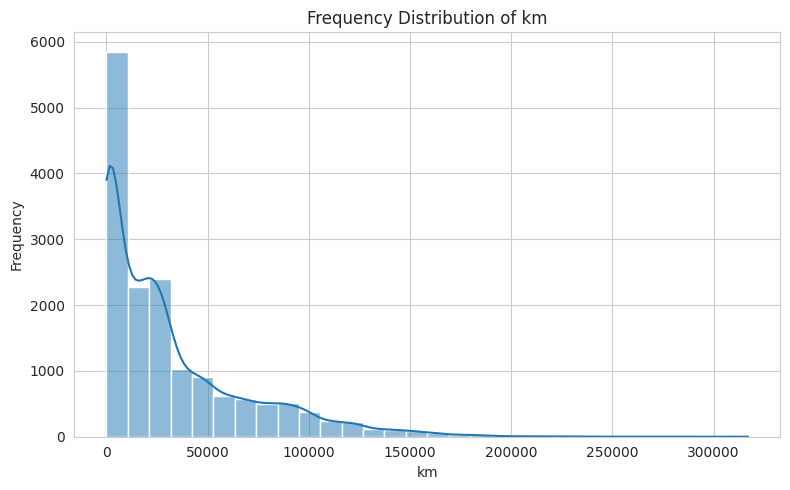

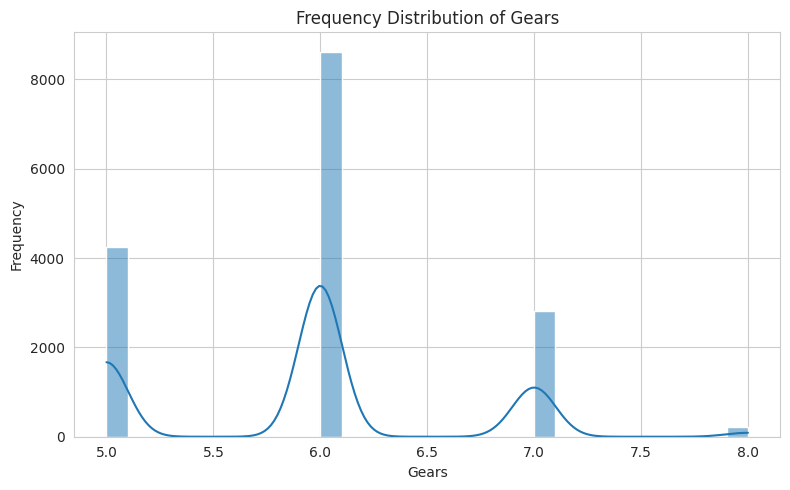

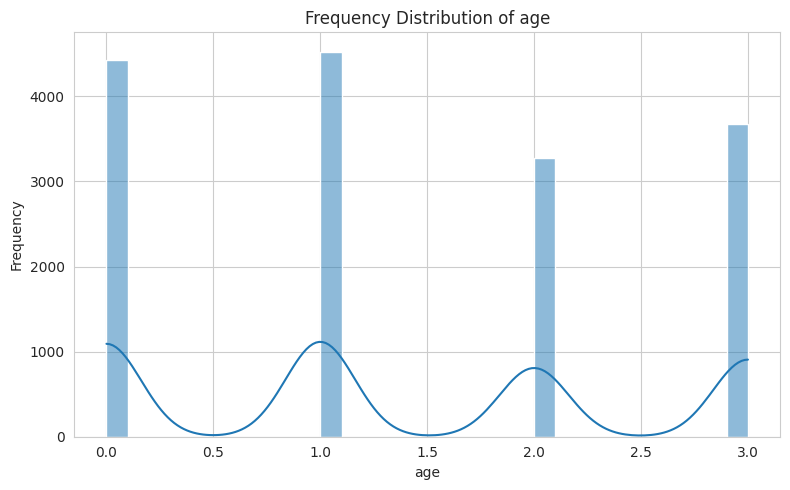

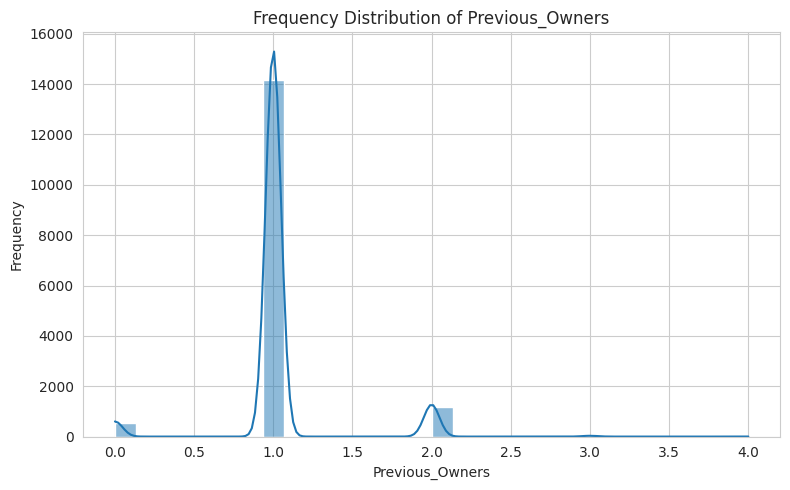

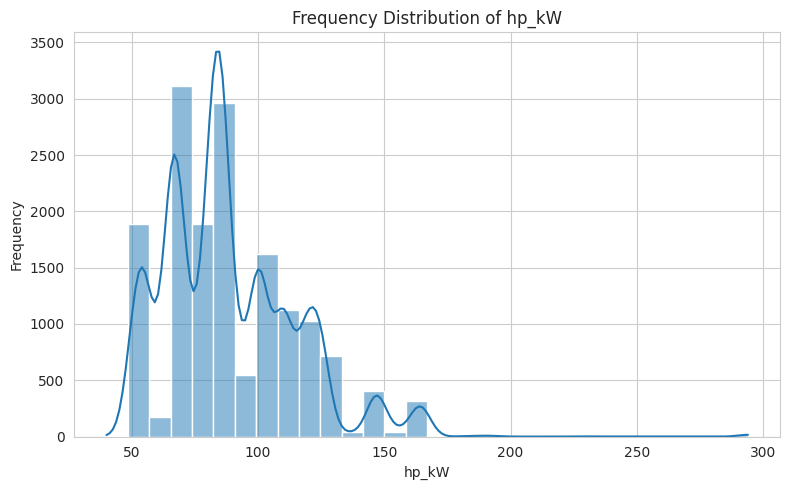

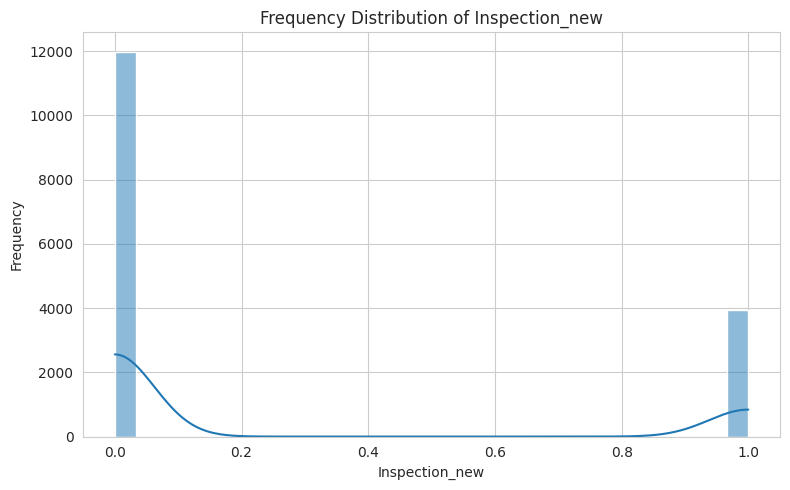

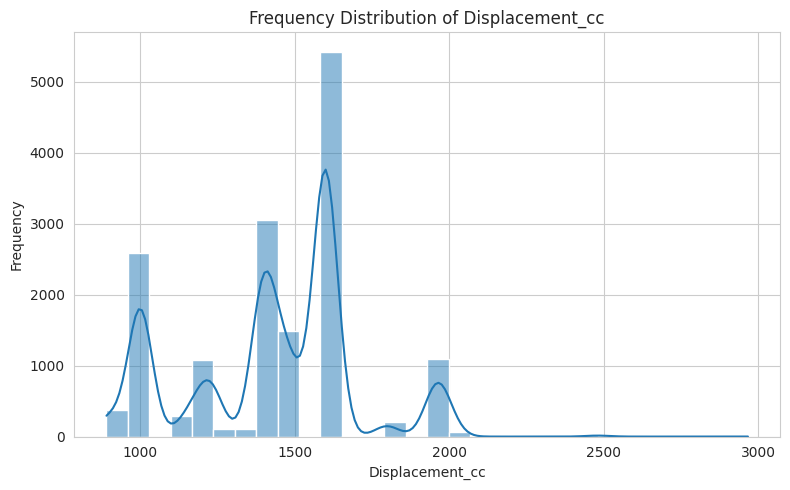

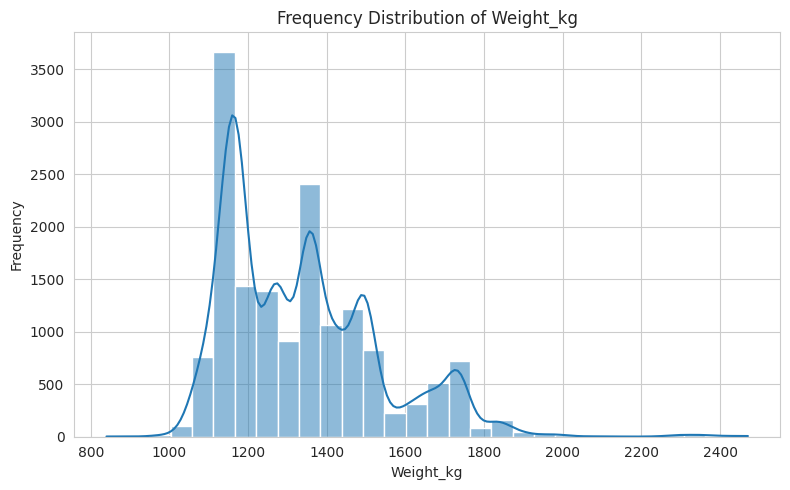

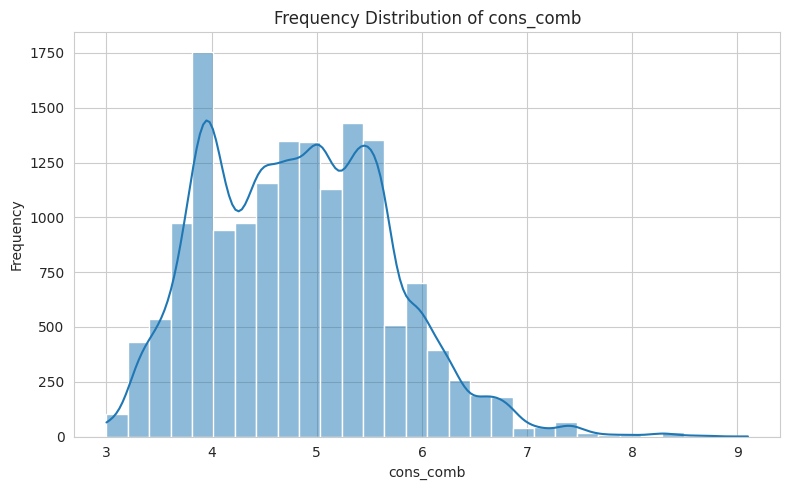

In [ ]:
# Frequency Distributions of Numerical Predictors (Histogram)
import matplotlib.pyplot as plt
import seaborn as sns

for col in numeric_predictors:
    plt.figure(figsize=(8, 5))

    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True
    )

    plt.title(f'Frequency Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

#### **2.1.3** <font color =red> [3 marks] </font>
Identify categorical predictors and plot their frequency distributions.

In [ ]:
# Identify categorical columns and check their frequency distributions
# Identify categorical columns
categorical_predictors = df.select_dtypes(include=['object']).columns.tolist()

print("Categorical Predictors:")
print("-" * 0)

for i, col in enumerate(categorical_predictors, start=1):
    print(f"{i}. {col}")

print("\nTotal number of categorical predictors:", len(categorical_predictors))

Categorical Predictors:

1. make_model
2. body_type
3. vat
4. Type
5. Fuel
6. Comfort_Convenience
7. Entertainment_Media
8. Extras
9. Safety_Security
10. Paint_Type
11. Upholstery_type
12. Gearing_Type
13. Drive_chain

Total number of categorical predictors: 13



Variable: make_model
Number of unique categories: 9


,make_model,Frequency
0,Audi A3,3097
1,Audi A1,2614
2,Opel Insignia,2598
3,Opel Astra,2525
4,Opel Corsa,2216
5,Renault Clio,1839
6,Renault Espace,991
7,Renault Duster,34
8,Audi A2,1


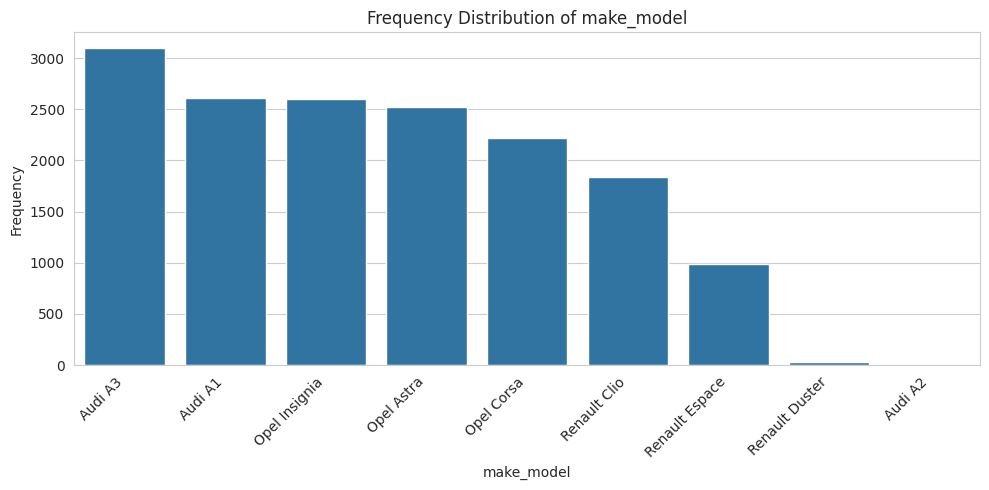


Variable: body_type
Number of unique categories: 8


,body_type,Frequency
0,Sedans,8004
1,Station wagon,3677
2,Compact,3240
3,Van,817
4,Transporter,88
5,Off-Road,56
6,Coupe,25
7,Convertible,8


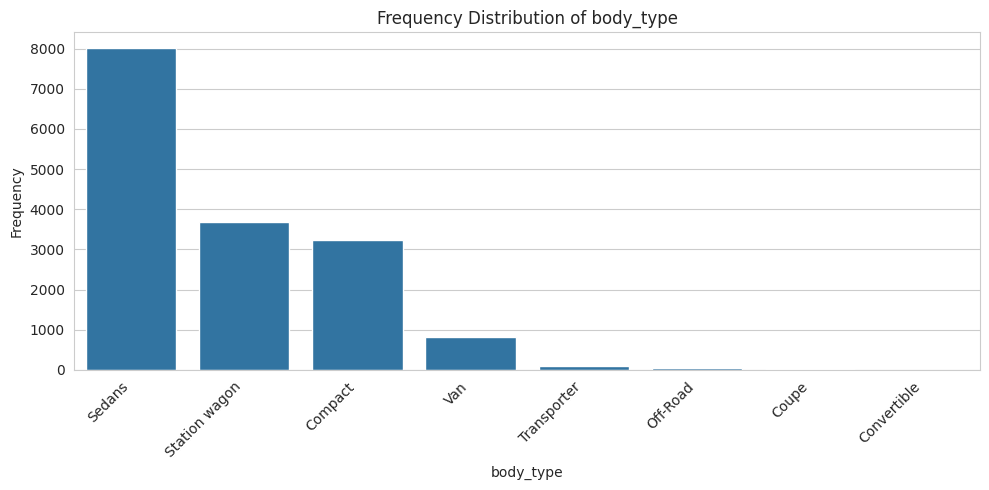


Variable: vat
Number of unique categories: 2


,vat,Frequency
0,VAT deductible,15044
1,Price negotiable,871


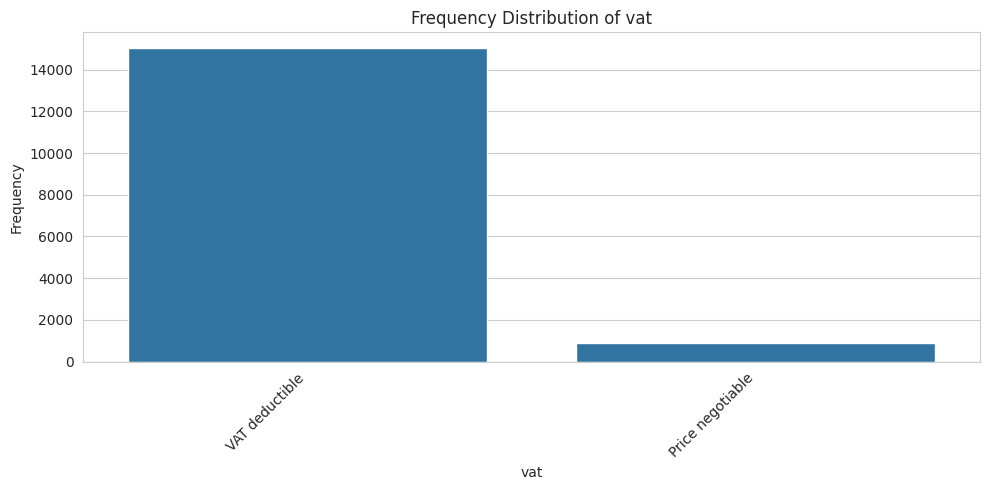


Variable: Type
Number of unique categories: 5


,Type,Frequency
0,Used,11095
1,New,1649
2,Pre-registered,1364
3,Employee's car,1011
4,Demonstration,796


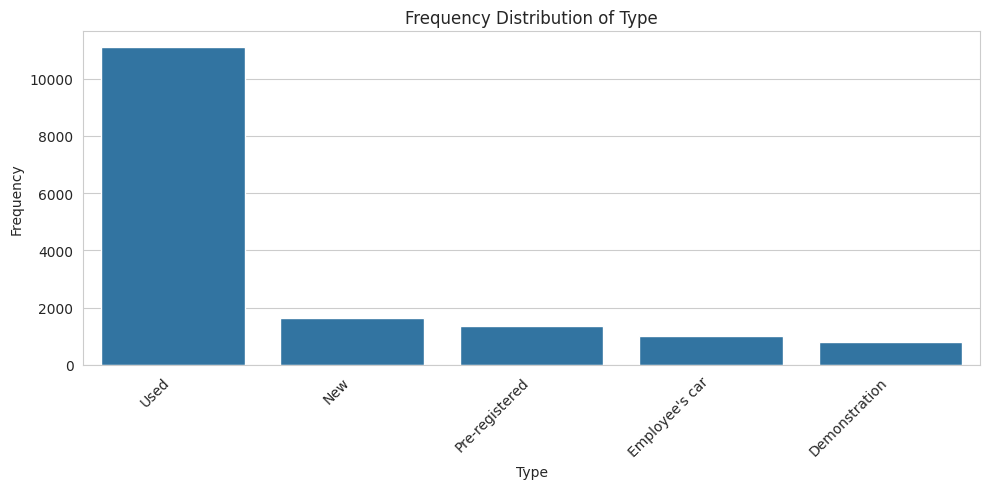


Variable: Fuel
Number of unique categories: 4


,Fuel,Frequency
0,Benzine,8548
1,Diesel,7298
2,LPG/CNG,64
3,Electric,5


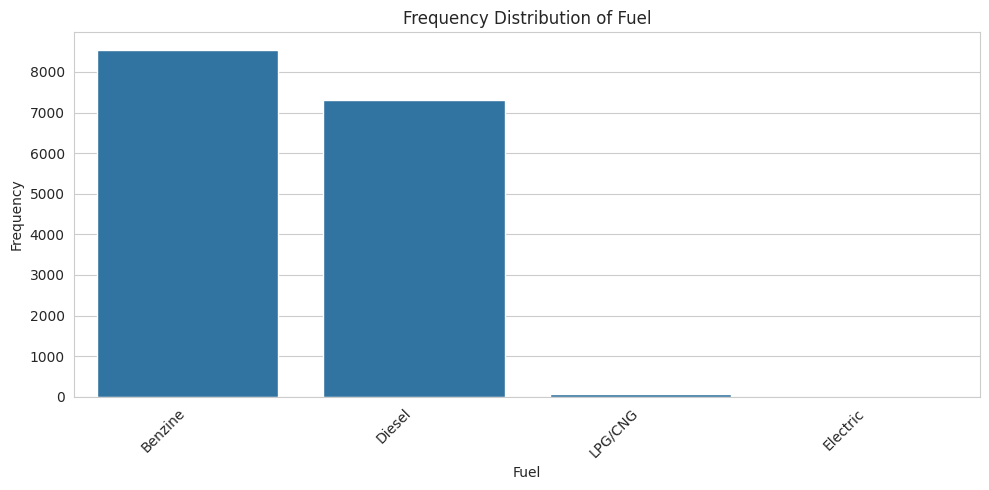


Variable: Comfort_Convenience
Number of unique categories: 6196


,Comfort_Convenience,Frequency
0,"Air conditioning,Electrical side mirrors,Hill ...",388
1,"Air conditioning,Armrest,Automatic climate con...",187
2,"Air conditioning,Armrest,Automatic climate con...",161
3,"Air conditioning,Automatic climate control,Cru...",160
4,"Air conditioning,Electrical side mirrors,Power...",134
5,"Air conditioning,Power windows",130
6,"Air conditioning,Automatic climate control,Cru...",119
7,"Cruise control,Electrical side mirrors,Power w...",114
8,"Air conditioning,Armrest,Cruise control,Electr...",113
9,"Air conditioning,Armrest,Automatic climate con...",92


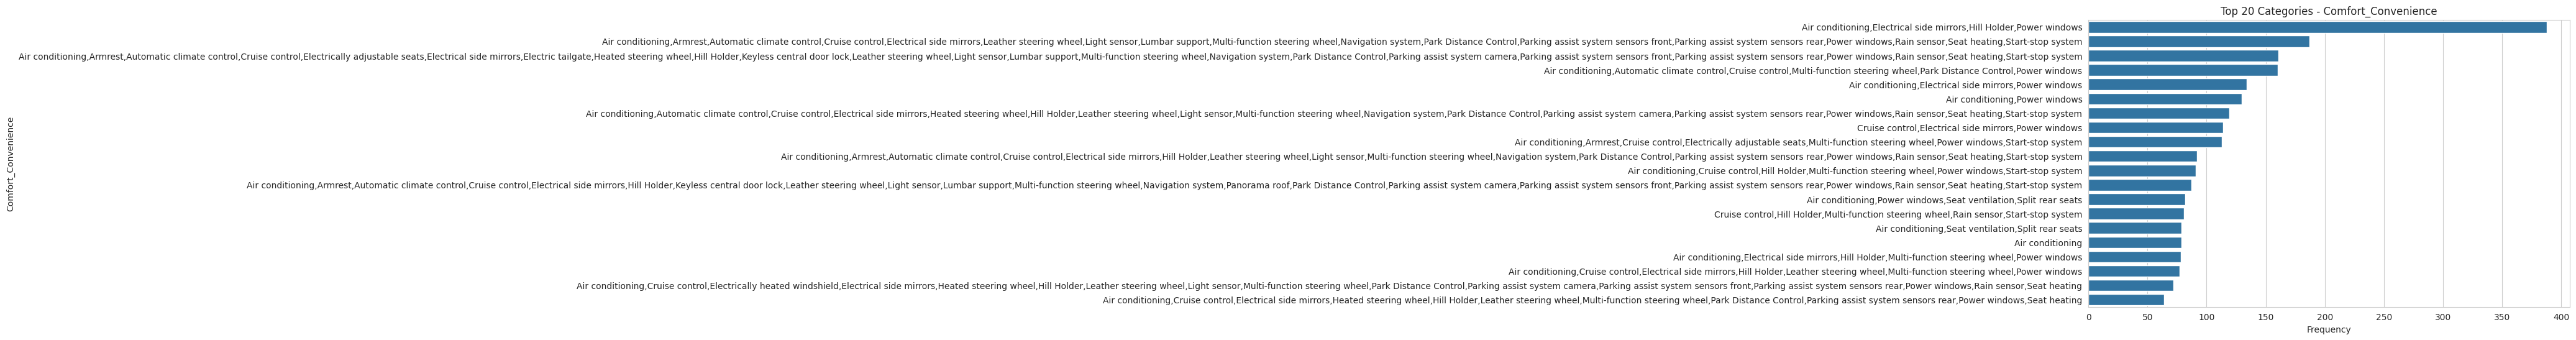


Variable: Entertainment_Media
Number of unique categories: 346


,Entertainment_Media,Frequency
0,"Bluetooth,Hands-free equipment,On-board comput...",1737
1,"Bluetooth,Hands-free equipment,MP3,On-board co...",1134
2,"Bluetooth,CD player,Hands-free equipment,MP3,O...",1009
3,On-board computer,615
4,Radio,558
5,"Bluetooth,Hands-free equipment,On-board comput...",515
6,"On-board computer,Radio",487
7,"Bluetooth,CD player,Hands-free equipment,On-bo...",466
8,"Bluetooth,On-board computer,Radio",426
9,"Bluetooth,CD player,Hands-free equipment,MP3,O...",404


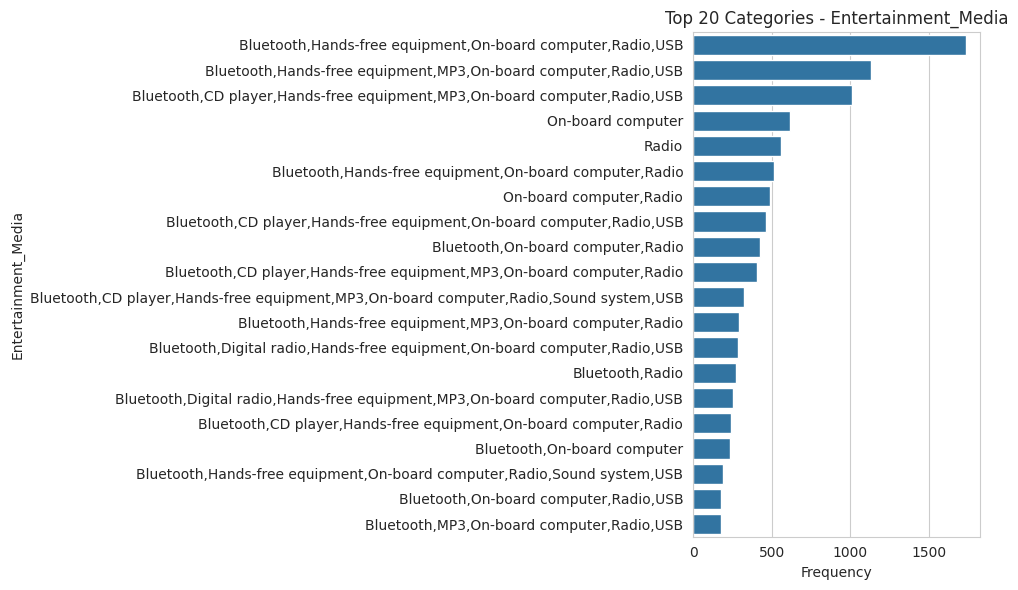


Variable: Extras
Number of unique categories: 659


,Extras,Frequency
0,Alloy wheels,5785
1,"Alloy wheels,Touch screen",697
2,Roof rack,595
3,"Alloy wheels,Voice Control",582
4,"Alloy wheels,Touch screen,Voice Control",544
5,"Alloy wheels,Roof rack",529
6,"Alloy wheels,Sport seats",382
7,"Alloy wheels,Catalytic Converter",275
8,"Alloy wheels,Sport seats,Sport suspension",234
9,"Alloy wheels,Catalytic Converter,Touch screen",228


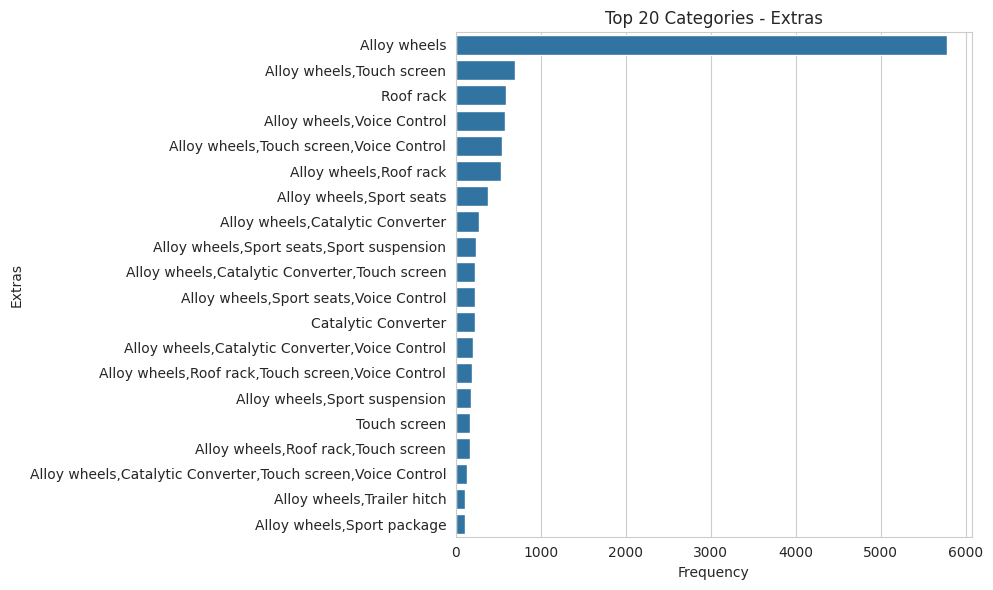


Variable: Safety_Security
Number of unique categories: 4442


,Safety_Security,Frequency
0,"ABS,Central door lock,Daytime running lights,D...",729
1,"ABS,Central door lock,Daytime running lights,D...",480
2,"ABS,Central door lock,Daytime running lights,D...",373
3,"ABS,Central door lock,Daytime running lights,D...",352
4,"ABS,Central door lock,Daytime running lights,D...",306
5,"ABS,Central door lock,Daytime running lights,D...",286
6,"ABS,Central door lock,Daytime running lights,D...",269
7,"ABS,Adaptive headlights,Central door lock,Dayt...",152
8,"ABS,Central door lock,Daytime running lights,D...",123
9,"ABS,Central door lock,Daytime running lights,D...",114


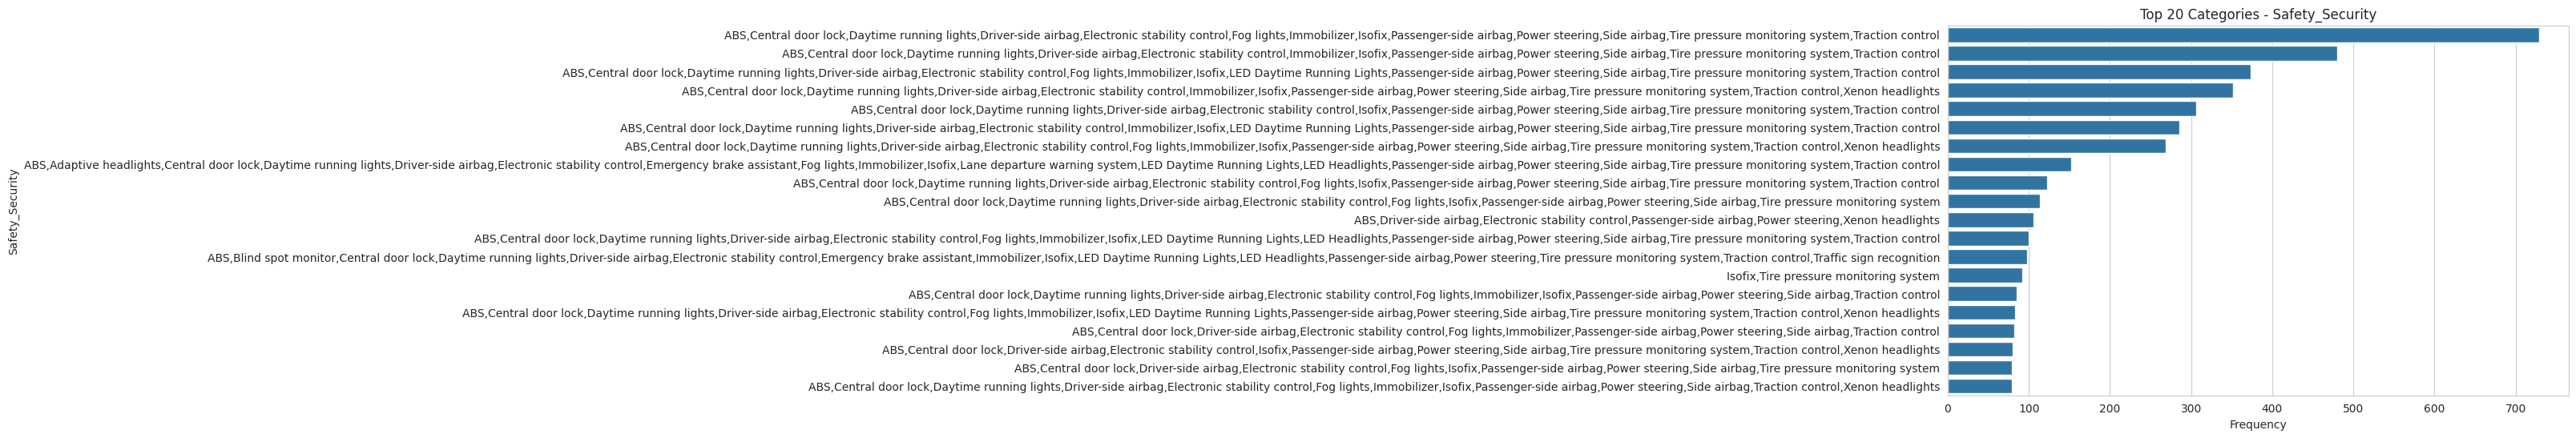


Variable: Paint_Type
Number of unique categories: 3


,Paint_Type,Frequency
0,Metallic,15246
1,Uni/basic,637
2,Perl effect,32


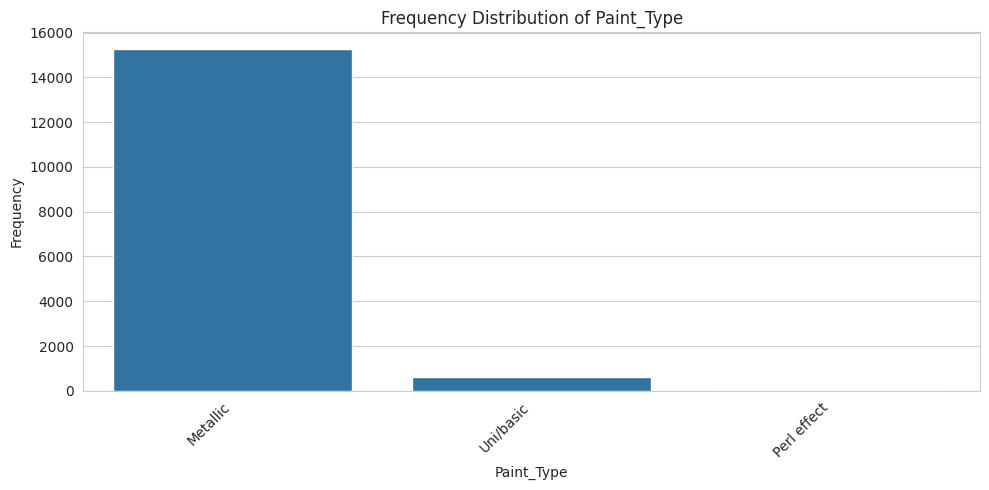


Variable: Upholstery_type
Number of unique categories: 2


,Upholstery_type,Frequency
0,Cloth,12234
1,Part/Full Leather,3681


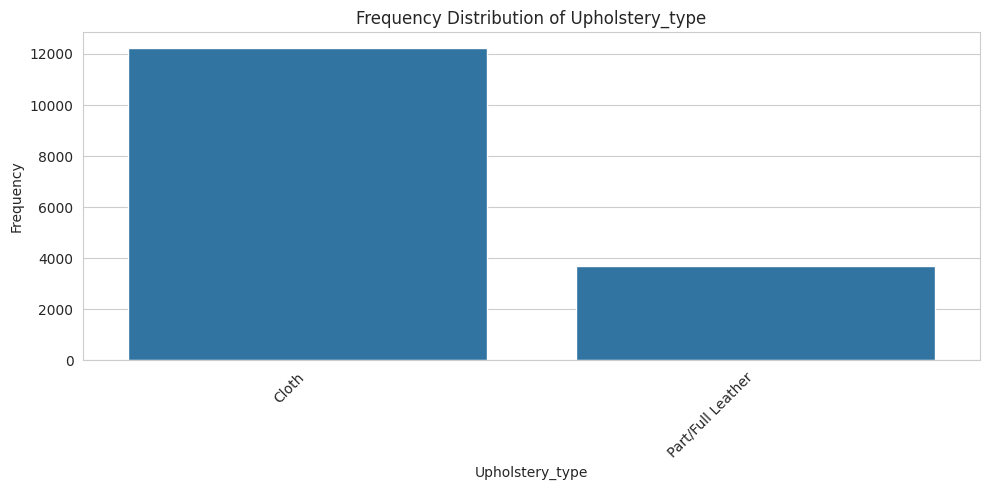


Variable: Gearing_Type
Number of unique categories: 3


,Gearing_Type,Frequency
0,Manual,8149
1,Automatic,7297
2,Semi-automatic,469


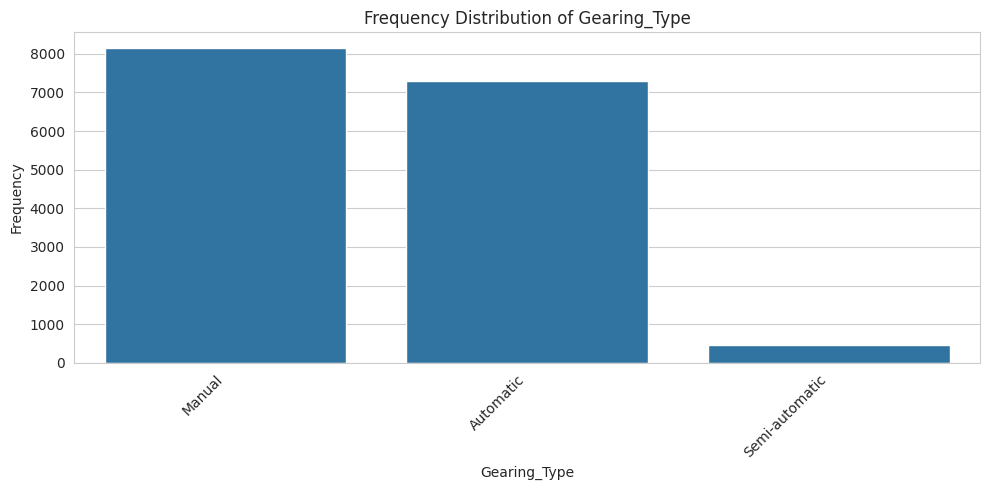


Variable: Drive_chain
Number of unique categories: 3


,Drive_chain,Frequency
0,front,15707
1,4WD,204
2,rear,4


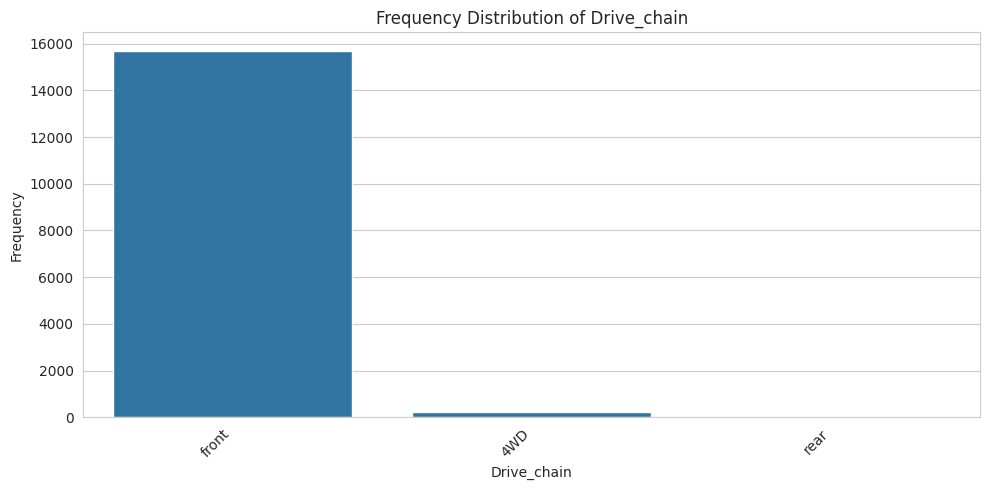

In [ ]:
# Frequency Distribution of Categorical Variables
for col in categorical_predictors:

    # Count unique categories
    n_unique = df[col].nunique()

    print(f"\n{'='*60}")
    print(f"Variable: {col}")
    print(f"Number of unique categories: {n_unique}")
    print(f"{'='*60}")

    # Display frequency table
    frequency_table = df[col].value_counts().reset_index()
    frequency_table.columns = [col, 'Frequency']

    display(frequency_table.head(20))

    # Plot all categories if manageable
    if n_unique <= 20:

        plt.figure(figsize=(10, 5))

        sns.countplot(
            data=df,
            x=col,
            order=df[col].value_counts().index
        )

        plt.title(f'Frequency Distribution of {col}')
        plt.xlabel(col)
        plt.ylabel('Frequency')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

    # Otherwise plot top 20 categories
    else:

        top_categories = df[col].value_counts().head(20)

        plt.figure(figsize=(10, 6))

        sns.barplot(
            x=top_categories.values,
            y=top_categories.index
        )

        plt.title(f'Top 20 Categories - {col}')
        plt.xlabel('Frequency')
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()

**Note**: Look carefully at the values stored in columns `["Comfort_Convenience", "Entertainment_Media", "Extras", "Safety_Security"]`.

Should they be considered categorical? Should they be dropped or handled any other way?

We should not treat them as ordinary categorical variables and don't drop them — decompose them into individual binary features plus specification counts.

In [ ]:
from sklearn.preprocessing import MultiLabelBinarizer

def engineer_specifications(df, spec_columns, min_prevalence=0.01):

    df = df.copy()

    for col in spec_columns:

        # Convert missing values to empty strings
        values = df[col].fillna("").astype(str)

        # Split comma-separated specifications
        token_lists = values.str.split(",")

        # Clean whitespace and remove empty values
        token_lists = token_lists.apply(
            lambda items: [
                item.strip()
                for item in items
                if item.strip()
            ]
        )

        # Create specification count
        df[f"{col}_count"] = token_lists.apply(len)

        # Calculate prevalence of each specification
        all_specs = [
            item
            for items in token_lists
            for item in items
        ]

        counts = pd.Series(all_specs).value_counts()

        prevalence = counts / len(df)

        # Keep specifications appearing in at least 1%
        # and at most 99% of observations
        keep_features = prevalence[
            (prevalence >= min_prevalence) &
            (prevalence <= 0.99)
        ].index

        # Create binary indicators
        for feature in keep_features:

            # Make feature name safe for column naming
            safe_feature = re.sub(
                r'[^A-Za-z0-9_]+',
                '_',
                feature
            ).strip('_')

            df[f"{col}_{safe_feature}"] = token_lists.apply(
                lambda items: int(feature in items)
            )

    # Drop original specification columns
    df = df.drop(columns=spec_columns)

    return df

In [ ]:
# Define the specification columns
import re
spec_columns = [
    "Comfort_Convenience",
    "Entertainment_Media",
    "Extras",
    "Safety_Security"
]

# Apply specification feature engineering
df_model = engineer_specifications(
    df,
    spec_columns=spec_columns
)

# Check the resulting dataset
print("New dataset shape:", df_model.shape)

# Display first 5 rows
display(df_model.head())

New dataset shape: (15915, 106)


,make_model,body_type,price,vat,km,Type,Fuel,Gears,age,Previous_Owners,hp_kW,Inspection_new,Paint_Type,Upholstery_type,Gearing_Type,Displacement_cc,Weight_kg,Drive_chain,cons_comb,Comfort_Convenience_count,Comfort_Convenience_Air_conditioning,Comfort_Convenience_Power_windows,Comfort_Convenience_Electrical_side_mirrors,Comfort_Convenience_Multi_function_steering_wheel,Comfort_Convenience_Cruise_control,Comfort_Convenience_Park_Distance_Control,Comfort_Convenience_Parking_assist_system_sensors_rear,Comfort_Convenience_Leather_steering_wheel,Comfort_Convenience_Start_stop_system,Comfort_Convenience_Automatic_climate_control,Comfort_Convenience_Rain_sensor,Comfort_Convenience_Navigation_system,Comfort_Convenience_Light_sensor,Comfort_Convenience_Armrest,Comfort_Convenience_Seat_heating,Comfort_Convenience_Hill_Holder,Comfort_Convenience_Parking_assist_system_sensors_front,Comfort_Convenience_Parking_assist_system_camera,Comfort_Convenience_Lumbar_support,Comfort_Convenience_Heated_steering_wheel,Comfort_Convenience_Keyless_central_door_lock,Comfort_Convenience_Split_rear_seats,Comfort_Convenience_Electrically_adjustable_seats,Comfort_Convenience_Tinted_windows,Comfort_Convenience_Electric_tailgate,Comfort_Convenience_Electrically_heated_windshield,Comfort_Convenience_Seat_ventilation,Comfort_Convenience_Parking_assist_system_self_steering,Comfort_Convenience_Panorama_roof,Comfort_Convenience_Heads_up_display,Comfort_Convenience_Sunroof,Comfort_Convenience_Massage_seats,Comfort_Convenience_Auxiliary_heating,Entertainment_Media_count,Entertainment_Media_On_board_computer,Entertainment_Media_Radio,Entertainment_Media_Bluetooth,Entertainment_Media_Hands_free_equipment,Entertainment_Media_USB,Entertainment_Media_MP3,Entertainment_Media_CD_player,Entertainment_Media_Sound_system,Entertainment_Media_Digital_radio,Extras_count,Extras_Alloy_wheels,Extras_Voice_Control,Extras_Touch_screen,Extras_Sport_seats,Extras_Roof_rack,Extras_Catalytic_Converter,Extras_Sport_suspension,Extras_Sport_package,Extras_Trailer_hitch,Extras_Shift_paddles,Extras_Cab_or_rented_Car,Extras_Ski_bag,Extras_Winter_tyres,Safety_Security_count,Safety_Security_ABS,Safety_Security_Driver_side_airbag,Safety_Security_Power_steering,Safety_Security_Passenger_side_airbag,Safety_Security_Electronic_stability_control,Safety_Security_Side_airbag,Safety_Security_Central_door_lock,Safety_Security_Isofix,Safety_Security_Traction_control,Safety_Security_Tire_pressure_monitoring_system,Safety_Security_Daytime_running_lights,Safety_Security_Immobilizer,Safety_Security_Fog_lights,Safety_Security_LED_Daytime_Running_Lights,Safety_Security_Xenon_headlights,Safety_Security_Emergency_brake_assistant,Safety_Security_LED_Headlights,Safety_Security_Lane_departure_warning_system,Safety_Security_Central_door_lock_with_remote_control,Safety_Security_Head_airbag,Safety_Security_Adaptive_headlights,Safety_Security_Traffic_sign_recognition,Safety_Security_Alarm_system,Safety_Security_Emergency_system,Safety_Security_Blind_spot_monitor,Safety_Security_Adaptive_Cruise_Control,Safety_Security_Rear_airbag,Safety_Security_Driver_drowsiness_detection
0,Audi A1,Sedans,15770,VAT deductible,56013.0,Used,Diesel,7.0,3.0,2.0,66.0,1,Metallic,Cloth,Automatic,1422.0,1220.0,front,3.8,16,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4,1,1,1,1,0,0,0,0,0,3,1,1,0,0,0,1,0,0,0,0,0,0,0,14,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,Audi A1,Sedans,14500,Price negotiable,80000.0,Used,Benzine,7.0,2.0,1.0,141.0,0,Metallic,Cloth,Automatic,1798.0,1255.0,front,5.6,9,1,1,0,0,0,0,1,1,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,5,1,1,1,1,0,0,0,1,0,4,1,1,0,1,0,0,1,0,0,0,0,0,0,15,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0
2,Audi A1,Sedans,14640,VAT deductible,83450.0,Used,Diesel,7.0,3.0,1.0,85.0,0,Metallic,Cloth,Automatic,1598.0,1135.0,front,3.8,13,1,1,1,1,1,1,1,1,1,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,1,0,0,0,0,1,0,0,0,2,1,1,0,0,0,0,0,0,0,0,0,0,0,12,1,1,1,1,1,1,1,

In [ ]:
# Start fresh from the original dataset
import re
df_clean = df.copy()

print("Working dataframe created.")
print("Shape:", df_clean.shape)

# Specification columns
spec_columns = [
    'Comfort_Convenience',
    'Entertainment_Media',
    'Extras',
    'Safety_Security'
]

# Engineer specifications
df_clean = engineer_specifications(
    df_clean,
    spec_columns=spec_columns,
    min_prevalence=0.01
)

print("New shape:", df_clean.shape)

# Show engineered specification columns
spec_features = [
    col for col in df_clean.columns
    if any(col.startswith(spec_col + "_") for spec_col in spec_columns)
]

print("Number of engineered specification features:", len(spec_features))

display(df_clean[spec_features].head())

Working dataframe created.
Shape: (15915, 23)
New shape: (15915, 106)
Number of engineered specification features: 87


,Comfort_Convenience_count,Comfort_Convenience_Air_conditioning,Comfort_Convenience_Power_windows,Comfort_Convenience_Electrical_side_mirrors,Comfort_Convenience_Multi_function_steering_wheel,Comfort_Convenience_Cruise_control,Comfort_Convenience_Park_Distance_Control,Comfort_Convenience_Parking_assist_system_sensors_rear,Comfort_Convenience_Leather_steering_wheel,Comfort_Convenience_Start_stop_system,Comfort_Convenience_Automatic_climate_control,Comfort_Convenience_Rain_sensor,Comfort_Convenience_Navigation_system,Comfort_Convenience_Light_sensor,Comfort_Convenience_Armrest,Comfort_Convenience_Seat_heating,Comfort_Convenience_Hill_Holder,Comfort_Convenience_Parking_assist_system_sensors_front,Comfort_Convenience_Parking_assist_system_camera,Comfort_Convenience_Lumbar_support,Comfort_Convenience_Heated_steering_wheel,Comfort_Convenience_Keyless_central_door_lock,Comfort_Convenience_Split_rear_seats,Comfort_Convenience_Electrically_adjustable_seats,Comfort_Convenience_Tinted_windows,Comfort_Convenience_Electric_tailgate,Comfort_Convenience_Electrically_heated_windshield,Comfort_Convenience_Seat_ventilation,Comfort_Convenience_Parking_assist_system_self_steering,Comfort_Convenience_Panorama_roof,Comfort_Convenience_Heads_up_display,Comfort_Convenience_Sunroof,Comfort_Convenience_Massage_seats,Comfort_Convenience_Auxiliary_heating,Entertainment_Media_count,Entertainment_Media_On_board_computer,Entertainment_Media_Radio,Entertainment_Media_Bluetooth,Entertainment_Media_Hands_free_equipment,Entertainment_Media_USB,Entertainment_Media_MP3,Entertainment_Media_CD_player,Entertainment_Media_Sound_system,Entertainment_Media_Digital_radio,Extras_count,Extras_Alloy_wheels,Extras_Voice_Control,Extras_Touch_screen,Extras_Sport_seats,Extras_Roof_rack,Extras_Catalytic_Converter,Extras_Sport_suspension,Extras_Sport_package,Extras_Trailer_hitch,Extras_Shift_paddles,Extras_Cab_or_rented_Car,Extras_Ski_bag,Extras_Winter_tyres,Safety_Security_count,Safety_Security_ABS,Safety_Security_Driver_side_airbag,Safety_Security_Power_steering,Safety_Security_Passenger_side_airbag,Safety_Security_Electronic_stability_control,Safety_Security_Side_airbag,Safety_Security_Central_door_lock,Safety_Security_Isofix,Safety_Security_Traction_control,Safety_Security_Tire_pressure_monitoring_system,Safety_Security_Daytime_running_lights,Safety_Security_Immobilizer,Safety_Security_Fog_lights,Safety_Security_LED_Daytime_Running_Lights,Safety_Security_Xenon_headlights,Safety_Security_Emergency_brake_assistant,Safety_Security_LED_Headlights,Safety_Security_Lane_departure_warning_system,Safety_Security_Central_door_lock_with_remote_control,Safety_Security_Head_airbag,Safety_Security_Adaptive_headlights,Safety_Security_Traffic_sign_recognition,Safety_Security_Alarm_system,Safety_Security_Emergency_system,Safety_Security_Blind_spot_monitor,Safety_Security_Adaptive_Cruise_Control,Safety_Security_Rear_airbag,Safety_Security_Driver_drowsiness_detection
0,16,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,4,1,1,1,1,0,0,0,0,0,3,1,1,0,0,0,1,0,0,0,0,0,0,0,14,1,1,1,1,1,1,1,1,1,1,1,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0
1,9,1,1,0,0,0,0,1,1,1,1,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,5,1,1,1,1,0,0,0,1,0,4,1,1,0,1,0,0,1,0,0,0,0,0,0,15,1,1,1,1,1,1,1,1,1,1,1,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,0
2,13,1,1,1,1,1,1,1,1,1,0,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,1,0,0,0,0,1,0,0,0,2,1,1,0,0,0,0,0,0,0,0,0,0,0,12,1,1,1,1,1,1,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,16,0,1,1,1,0,0,0,1,1,0,1,1,1,1,1,1,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,1,8,1,1,1,1,1,1,1,1,0,3,1,1,0,1,0,0,0,0,0,0,0,0,0,14,1,1,1,1,1,1,0,1,0,1,0,1,0,0,0,0,0,0,1,1,0,0,1,1,0,0,0,1
4,13,1,1,1,1,0,1,1,1,1,1,1,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,7,1,1,1,1,1,1,1,0,0,4,1,1,0,0,0,0,1,1,0,0,0,0,0,13,1,1,1,1,1,1,1,1,1,1,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
print("Shape:", df_clean.shape)

print("\nOriginal specification columns remaining:")
print([
    col for col in spec_columns
    if col in df_clean.columns
])

print("\nNumber of engineered specification features:", len(spec_features))

Shape: (15915, 106)

Original specification columns remaining:
[]

Number of engineered specification features: 87


#### **2.1.4** <font color =red> [3 marks] </font>
Fix columns with low frequency values and class imbalances.

Some information regarding values in the `Type` column that may help:
- *'Pre-registered'* cars are ones which have already been registered previously by the seller.
- *'New'* cars are not necessarily new cars, but new-like cars. These might also have multiple owners due to multiple pre-registrations as well.
- *'Employee's car'* are cars used by employees over a short period of time and small distance.
- *'Demonstration'* cars are used for trial purposes and also driven for a short time and distance.

Based on these, you can handle this particular column. For other columns, decide a strategy on your own.

In [ ]:
# Check Frequency and Class Imbalance


categorical_columns = df.select_dtypes(include='object').columns.tolist()

for col in categorical_columns:

    print("\n" + "=" * 70)
    print(f"Column: {col}")
    print("=" * 70)

    frequency = df[col].value_counts(dropna=False)
    percentage = df[col].value_counts(
        normalize=True,
        dropna=False
    ) * 100

    summary = pd.DataFrame({
        'Frequency': frequency,
        'Percentage': percentage.round(2)
    })

    display(summary)


Column: make_model


,Frequency,Percentage
make_model,,
Audi A3,3097,19.46
Audi A1,2614,16.42
Opel Insignia,2598,16.32
Opel Astra,2525,15.87
Opel Corsa,2216,13.92
Renault Clio,1839,11.56
Renault Espace,991,6.23
Renault Duster,34,0.21
Audi A2,1,0.01



Column: body_type


,Frequency,Percentage
body_type,,
Sedans,8004,50.29
Station wagon,3677,23.10
Compact,3240,20.36
Van,817,5.13
Transporter,88,0.55
Off-Road,56,0.35
Coupe,25,0.16
Convertible,8,0.05



Column: vat


,Frequency,Percentage
vat,,
VAT deductible,15044,94.53
Price negotiable,871,5.47


... (16 outputs left out)


Column: Gearing_Type


,Frequency,Percentage
Gearing_Type,,
Manual,8149,51.20
Automatic,7297,45.85
Semi-automatic,469,2.95



Column: Drive_chain


,Frequency,Percentage
Drive_chain,,
front,15707,98.69
4WD,204,1.28
rear,4,0.03


In [ ]:
# Create the working dataframe
df_clean = df.copy()

print("Working dataframe created.")
print("Shape:", df_clean.shape)

Working dataframe created.
Shape: (15915, 23)


In [ ]:
# Fix columns as needed
#Fix Low-Frequency Values and Class Imbalances

# Function to group rare categories
def group_rare_categories(series, threshold=0.01):
    """
    Groups categories occurring in less than 1%
    of observations into 'Other'.
    """

    proportions = series.value_counts(normalize=True)

    return series.where(
        series.map(proportions) >= threshold,
        'Other'
    )

# Remove exact duplicate observations before further preprocessing.
duplicate_rows_before = df_clean.duplicated().sum()
print("Duplicate rows before removal:", duplicate_rows_before)

df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Duplicate rows after removal:", df_clean.duplicated().sum())
print("Shape after duplicate removal:", df_clean.shape)



# Identify categorical columns
categorical_columns = df_clean.select_dtypes(
    include='object'
).columns.tolist()


# Columns that require special handling
special_columns = [
    'Type',
    'Comfort_Convenience',
    'Entertainment_Media',
    'Extras',
    'Safety_Security'
]


# Group rare categories in ordinary categorical variables
for col in categorical_columns:

    if col not in special_columns:

        df_clean[col] = group_rare_categories(
            df_clean[col],
            threshold=0.01
        )


# Display final distributions
for col in categorical_columns:

    print("\n" + "=" * 70)
    print(f"Category distribution after treatment: {col}")
    print("=" * 70)

    freq_table = pd.DataFrame({
        'Frequency': df_clean[col].value_counts(),
        'Percentage': (
            df_clean[col]
            .value_counts(normalize=True) * 100
        ).round(2)
    })

    display(freq_table)


Duplicate rows before removal: 0
Duplicate rows after removal: 0
Shape after duplicate removal: (14242, 23)

Category distribution after treatment: make_model


,Frequency,Percentage
make_model,,
Audi A3,2758,19.37
Opel Insignia,2417,16.97
Audi A1,2377,16.69
Opel Astra,2305,16.18
Opel Corsa,1994,14.00
Renault Clio,1486,10.43
Renault Espace,884,6.21
Other,21,0.15



Category distribution after treatment: body_type


,Frequency,Percentage
body_type,,
Sedans,7230,50.77
Station wagon,3405,23.91
Compact,2710,19.03
Van,735,5.16
Other,162,1.14



Category distribution after treatment: vat


,Frequency,Percentage
vat,,
VAT deductible,13426,94.27
Price negotiable,816,5.73


... (16 outputs left out)


Category distribution after treatment: Gearing_Type


,Frequency,Percentage
Gearing_Type,,
Manual,7232,50.78
Automatic,6546,45.96
Semi-automatic,464,3.26



Category distribution after treatment: Drive_chain


,Frequency,Percentage
Drive_chain,,
front,14067,98.77
4WD,171,1.20
Other,4,0.03


The frequency distribution of categorical variables was examined to identify low-frequency categories. Rare categories in ordinary categorical variables were grouped into an "Other" category using a 1% frequency threshold. The Type column was handled separately because its categories (New, Pre-registered, Employee's car, and Demonstration) have distinct business meanings and were therefore retained. The specification columns were also excluded from this treatment because they contain multiple comma-separated features and will be handled separately through feature engineering.

#### **2.1.5** <font color =red> [3 marks] </font>
Identify target variable and plot the frequency distributions. Apply necessary transformations.

In [ ]:
# Identify Target Variable

target = 'price'

print("Target Variable:", target)
print("Minimum Price:", df[target].min())
print("Maximum Price:", df[target].max())
print("Mean Price:", df[target].mean())
print("Median Price:", df[target].median())


Target Variable: price
Minimum Price: 4950
Maximum Price: 74600
Mean Price: 18024.38058435438
Median Price: 16900.0


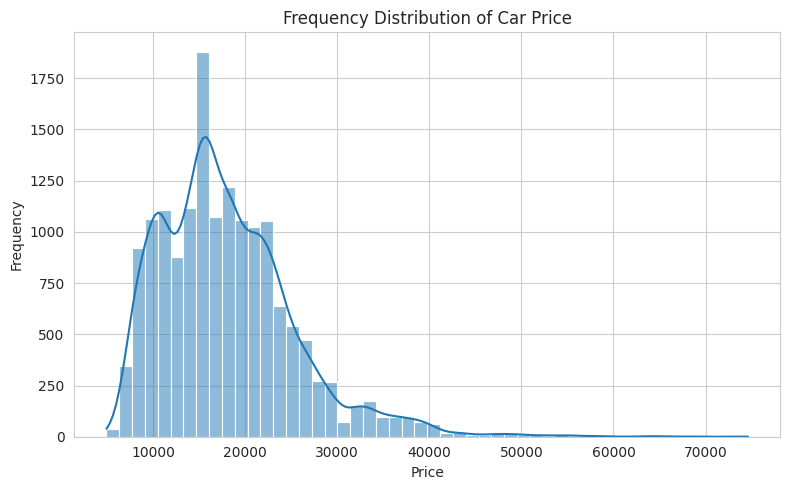

In [ ]:
# Plot histograms for target feature

# Frequency Distribution of Target Variable
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='price',
    bins=50,
    kde=True
)

plt.title('Frequency Distribution of Car Price')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

**The target variable seems to be skewed. Perform suitable transformation on the target.**

In [ ]:

# Log Transformation of Target Variable

df['log_price'] = np.log1p(df['price'])

print("Original price skewness:",
      df['price'].skew())

print("Log-transformed price skewness:",
      df['log_price'].skew())

Original price skewness: 1.2361694128996692
Log-transformed price skewness: -0.0314736417467197


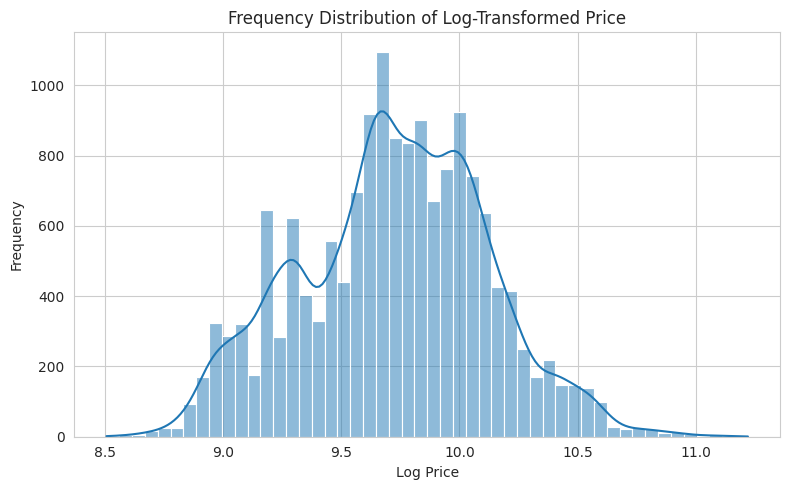

In [ ]:
# Frequency Distribution of Log-Transformed Price

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='log_price',
    bins=50,
    kde=True
)

plt.title('Frequency Distribution of Log-Transformed Price')
plt.xlabel('Log Price')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

The target variable price was identified as the response variable for the regression problem. Its frequency distribution was examined using a histogram. The original price distribution showed right-skewness, indicating the presence of relatively high-priced vehicles. To reduce the influence of extreme values and improve the distribution for linear regression, the transformation log1p(price) was applied. The original and transformed skewness values were compared to assess the effectiveness of the transformation.

### **2.2 Correlation analysis** <font color = red> [6 marks] </font>

#### **2.2.1** <font color =red> [3 marks] </font>
Plot the correlation map between features and target variable.

In [ ]:
# Correlation Analysis


# Select numerical columns including the target
correlation_data = df.select_dtypes(include=np.number)

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Display correlation of all numerical features with price
price_correlation = (
    correlation_matrix['price']
    .sort_values(ascending=False)
)

print("Correlation of Numerical Features with Price:")
display(price_correlation.to_frame(name='Correlation with Price'))

Correlation of Numerical Features with Price:


,Correlation with Price
price,1.000000
log_price,0.962281
hp_kW,0.696411
Gears,0.530291
Weight_kg,0.468433
Displacement_cc,0.281824
cons_comb,0.272261
Inspection_new,0.008180
Previous_Owners,-0.144628
km,-0.399291


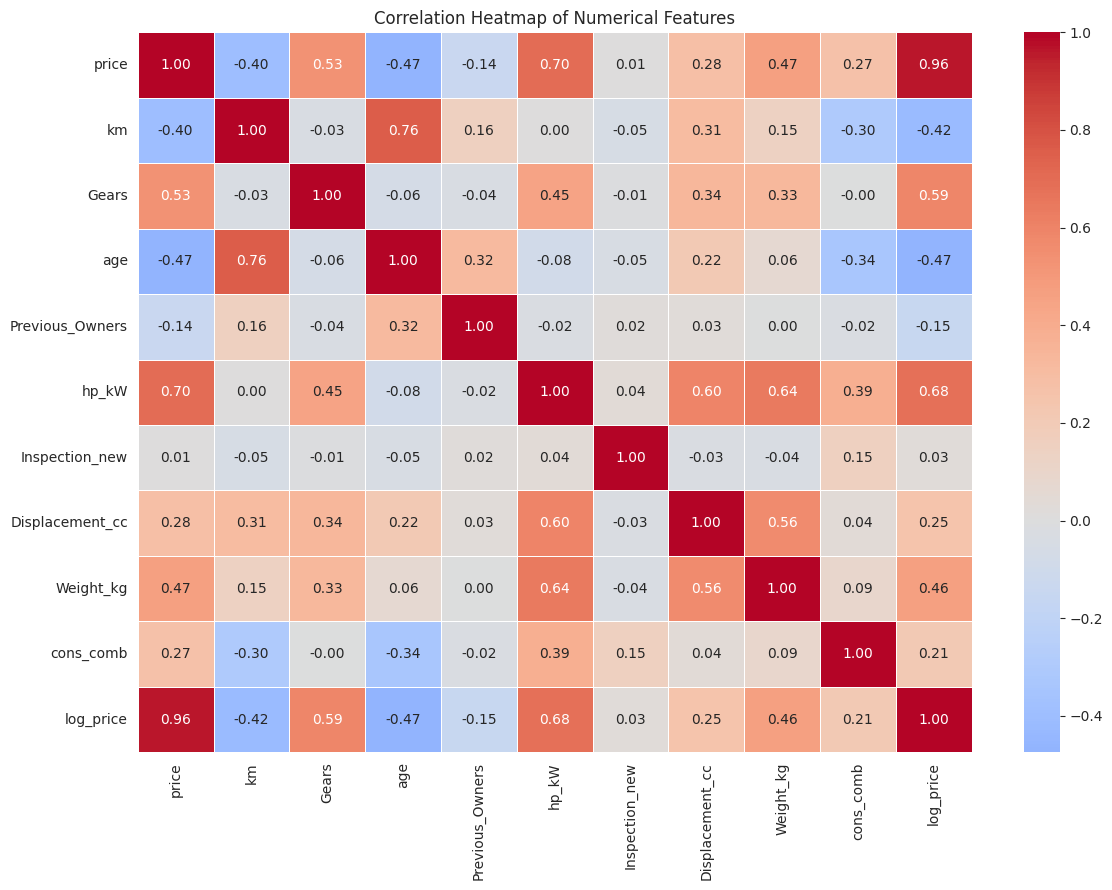

In [ ]:
# Visualise correlation
# Correlation Heatmap


plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

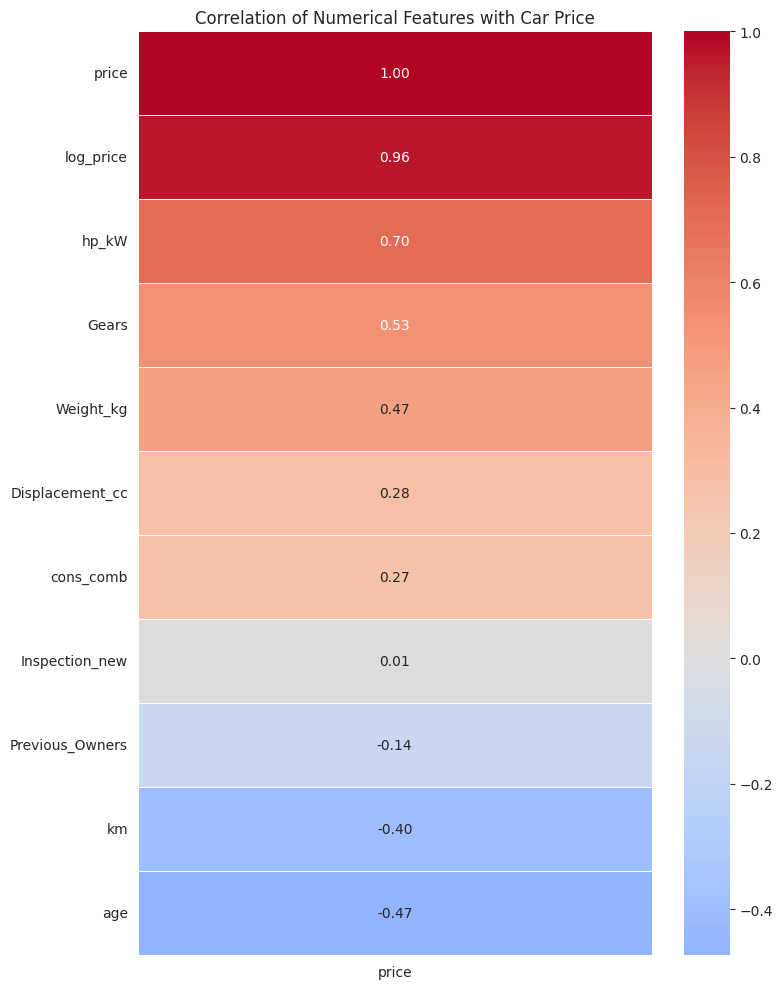

In [ ]:
 # More cleaner heatmap focused on target
 # Correlation of numerical predictors with target
target_corr = (
    correlation_matrix[['price']]
    .sort_values(by='price', ascending=False)
)

plt.figure(figsize=(8, 10))

sns.heatmap(
    target_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Correlation of Numerical Features with Car Price')
plt.tight_layout()
plt.show()

#### **2.2.2** <font color =red> [3 marks] </font>
Analyse correlation between categorical features and target variable.

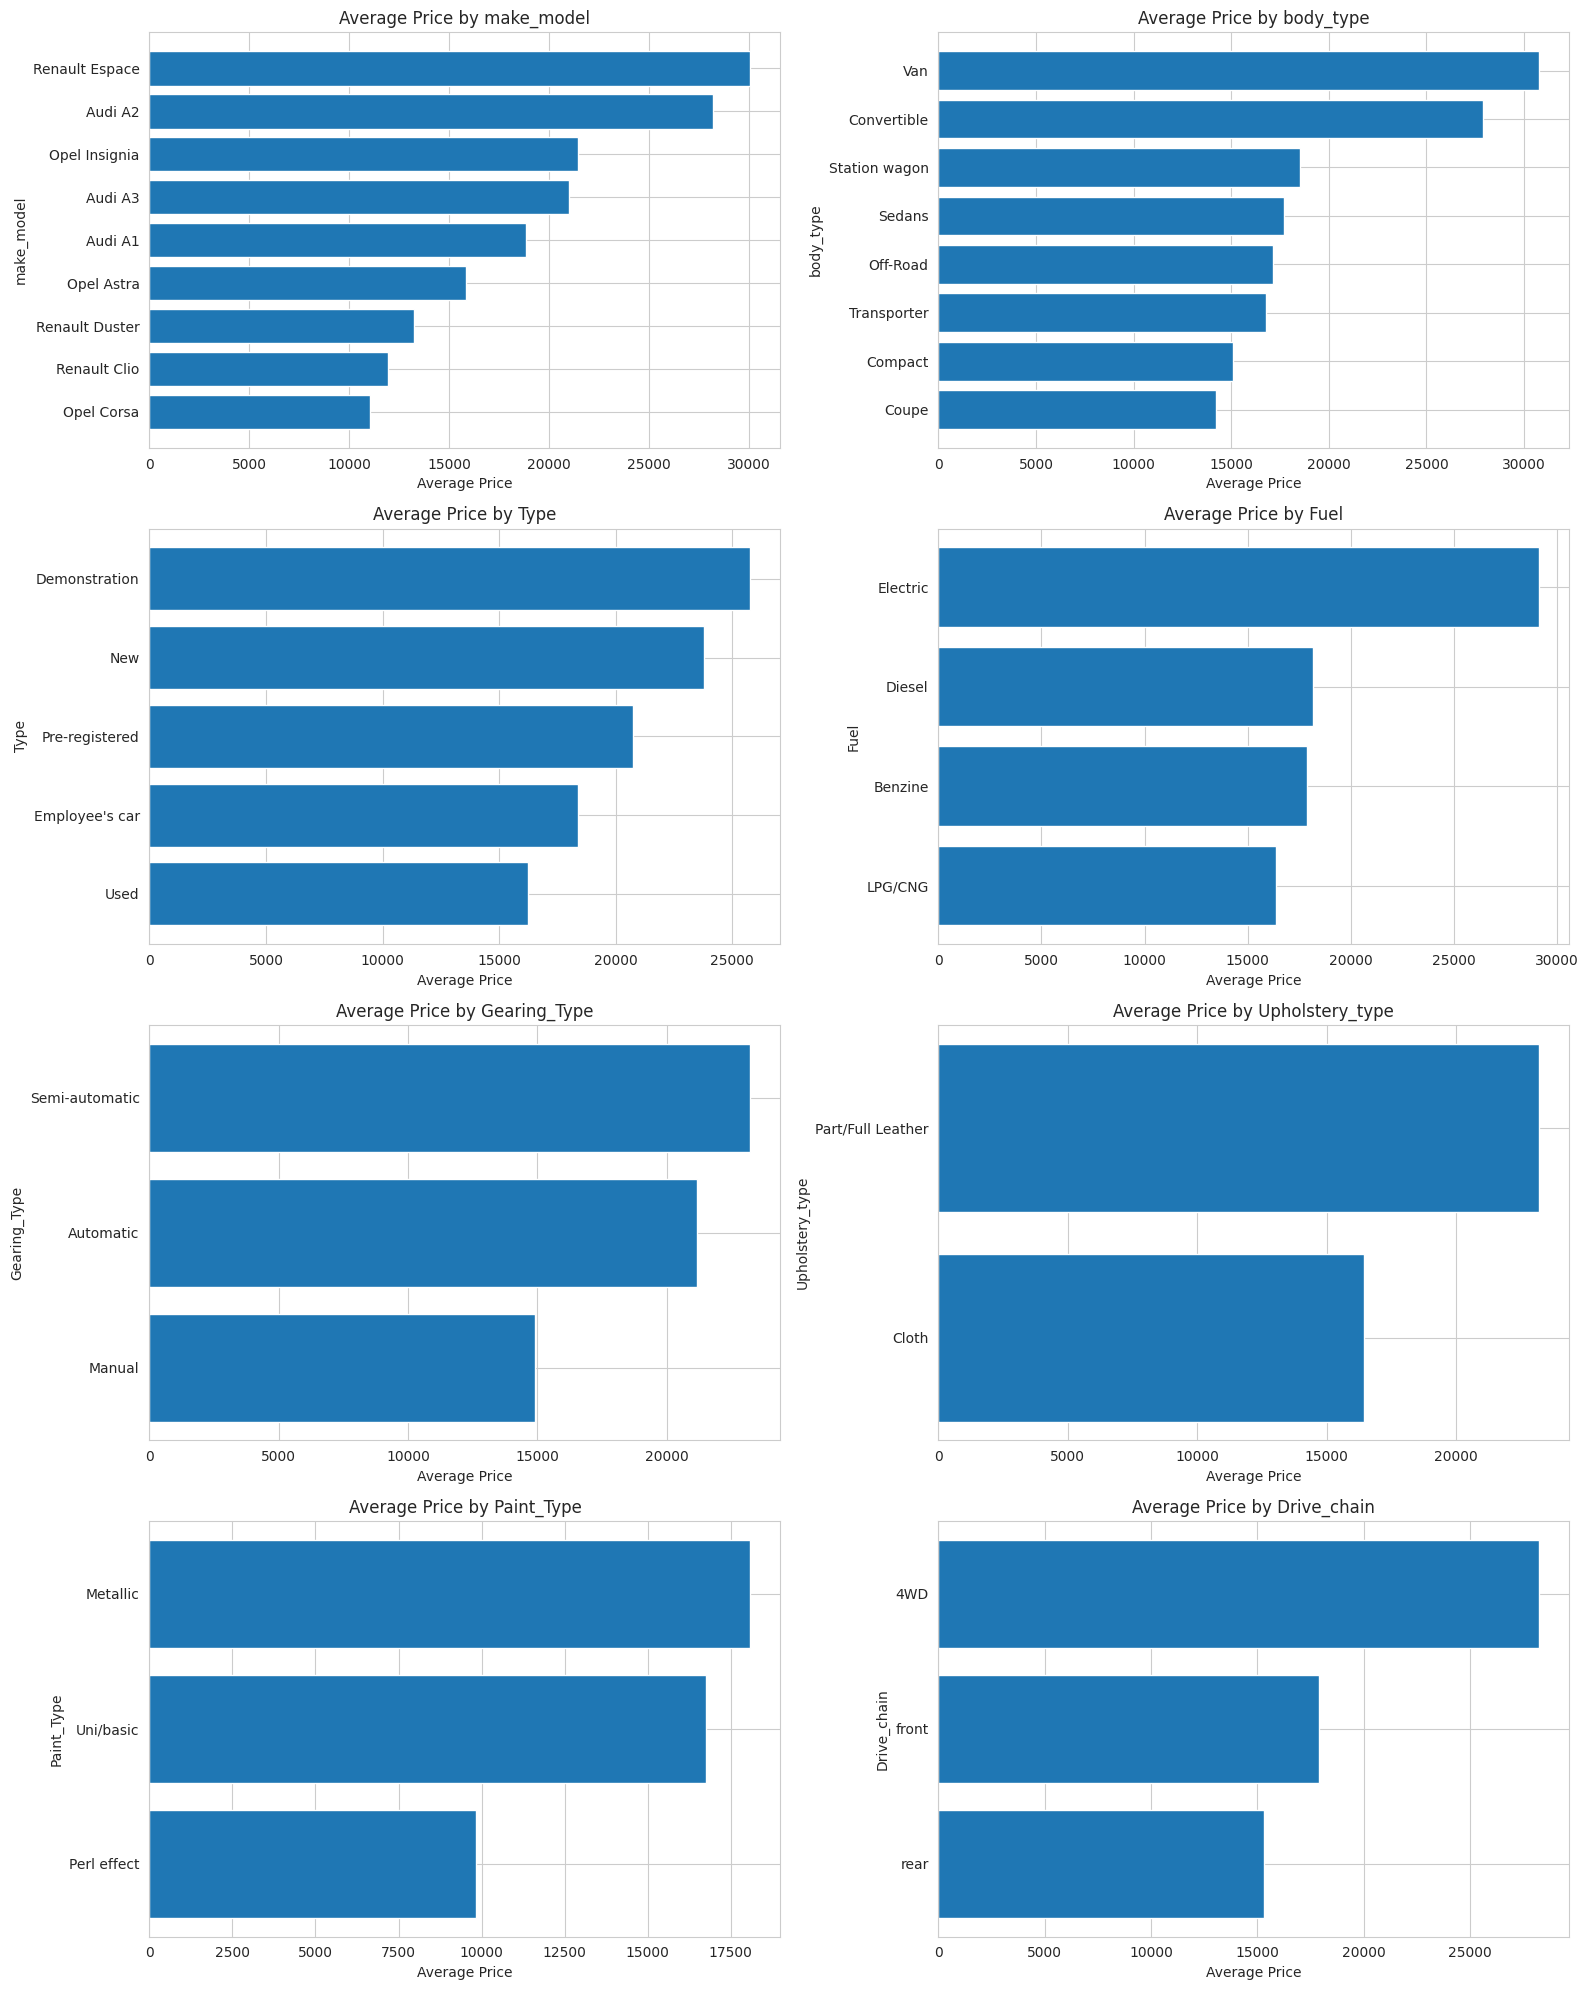

In [ ]:
# Comparing average values of target for different categories

# Categorical features to analyse
plot_cats = [
    "make_model",
    "body_type",
    "Type",
    "Fuel",
    "Gearing_Type",
    "Upholstery_type",
    "Paint_Type",
    "Drive_chain"
]

# Create subplots
n_cols = 2
n_rows = int(np.ceil(len(plot_cats) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 5 * n_rows)
)

axes = np.array(axes).reshape(-1)

# Plot average price for each category
for ax, col in zip(axes, plot_cats):

    avg_price = (
        df.groupby(col)["price"]
        .mean()
        .sort_values(ascending=True)
    )

    ax.barh(
        range(len(avg_price)),
        avg_price.values
    )

    ax.set_yticks(range(len(avg_price)))
    ax.set_yticklabels(avg_price.index)

    ax.set_title(f"Average Price by {col}")
    ax.set_xlabel("Average Price")
    ax.set_ylabel(col)

# Remove unused axes
for ax in axes[len(plot_cats):]:
    ax.remove()

plt.tight_layout()
plt.show()


In [ ]:
# Average price and number of observations by category

for col in plot_cats:

    summary = (
        df.groupby(col)["price"]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
    )

    print(f"\n{'='*60}")
    print(f"{col} vs Price")
    print(f"{'='*60}")

    display(summary)


make_model vs Price


,count,mean,median
make_model,,,
Renault Espace,991,30080.211907,28900.0
Audi A2,1,28200.000000,28200.0
Opel Insignia,2598,21463.451886,19990.0
Audi A3,3097,20996.693252,20900.0
Audi A1,2614,18864.688982,17890.0
Opel Astra,2525,15840.834059,15290.0
Renault Duster,34,13230.176471,13189.0
Renault Clio,1839,11940.320827,10650.0
Opel Corsa,2216,11061.841606,10500.0



body_type vs Price


,count,mean,median
body_type,,,
Van,817,30789.209302,29900.0
Convertible,8,27905.375000,25750.0
Station wagon,3677,18542.296981,17490.0
Sedans,8004,17699.040480,17440.0
Off-Road,56,17126.160714,14399.0
Transporter,88,16764.795455,18400.0
Compact,3240,15076.206481,14385.0
Coupe,25,14222.720000,11100.0



Type vs Price


,count,mean,median
Type,,,
Demonstration,796,25774.386935,24890.0
New,1649,23798.834445,23139.0
Pre-registered,1364,20743.063050,21470.0
Employee's car,1011,18398.100890,18800.0
Used,11095,16241.848490,15850.0


... (6 outputs left out)


Paint_Type vs Price


,count,mean,median
Paint_Type,,,
Metallic,15246,18095.052866,16900.0
Uni/basic,637,16745.040816,15500.0
Perl effect,32,9820.312500,8490.0



Drive_chain vs Price


,count,mean,median
Drive_chain,,,
4WD,204,28261.416667,29995.0
front,15707,17892.109123,16890.0
rear,4,15332.500000,15925.0


Categorical Feature–Target Analysis: Categorical predictors were analysed by comparing the mean and median vehicle price across their respective categories. Several categorical variables, particularly Type, Gearing_Type, Upholstery_type, body_type, and make_model, showed noticeable differences in average prices across categories, indicating potentially useful predictive information. However, categories with very small sample sizes, such as Audi A2, Electric, and rear drive, should be interpreted cautiously because their estimated average prices may be unstable. These findings will be considered during categorical feature preprocessing and model development.

### **2.3 Outlier analysis** <font color = red> [5 marks] </font>

#### **2.3.1** <font color =red> [2 marks] </font>
Identify potential outliers in the data.

In [ ]:
#  Outliers present in each column
# 2.3 Outlier Analysis
# 2.3.1 Identify potential outliers in the data
# step 1. Identify numerical predictors

numeric_predictors = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in ['price', 'log_price']
]

print("Numerical predictors:")
print(numeric_predictors)

Numerical predictors:
['km', 'Gears', 'age', 'Previous_Owners', 'hp_kW', 'Inspection_new', 'Displacement_cc', 'Weight_kg', 'cons_comb']


In [ ]:
# Step 2 — Calculate IQR and identify outliers
# Calculate IQR-based outliers

outlier_summary = []

for col in numeric_predictors:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (df[col] < lower_bound) | (df[col] > upper_bound)

    outlier_count = outlier_mask.sum()
    outlier_percentage = (outlier_count / len(df)) * 100

    outlier_summary.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outlier_count,
        'Outlier Percentage': round(outlier_percentage, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,km,1920.5,46900.0,44979.5,-65548.75,114369.25,689,4.33
1,Gears,5.0,6.0,1.0,3.50,7.50,225,1.41
2,age,0.0,2.0,2.0,-3.00,5.00,0,0.00
3,Previous_Owners,1.0,1.0,0.0,1.00,1.00,1757,11.04
4,hp_kW,66.0,103.0,37.0,10.50,158.50,361,2.27
5,Inspection_new,0.0,0.0,0.0,0.00,0.00,3932,24.71
6,Displacement_cc,1229.0,1598.0,369.0,675.50,2151.50,21,0.13
7,Weight_kg,1165.0,1472.0,307.0,704.50,1932.50,87,0.55
8,cons_comb,4.1,5.4,1.3,2.15,7.35,125,0.79


In [ ]:
# Step 3 — Identify features with potential outliers
# Features with potential outliers

potential_outliers = outlier_summary[
    outlier_summary['Outlier Count'] > 0
].sort_values(
    'Outlier Percentage',
    ascending=False
)

display(potential_outliers)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
5,Inspection_new,0.0,0.0,0.0,0.00,0.00,3932,24.71
3,Previous_Owners,1.0,1.0,0.0,1.00,1.00,1757,11.04
0,km,1920.5,46900.0,44979.5,-65548.75,114369.25,689,4.33
4,hp_kW,66.0,103.0,37.0,10.50,158.50,361,2.27
1,Gears,5.0,6.0,1.0,3.50,7.50,225,1.41
8,cons_comb,4.1,5.4,1.3,2.15,7.35,125,0.79
7,Weight_kg,1165.0,1472.0,307.0,704.50,1932.50,87,0.55
6,Displacement_cc,1229.0,1598.0,369.0,675.50,2151.50,21,0.13


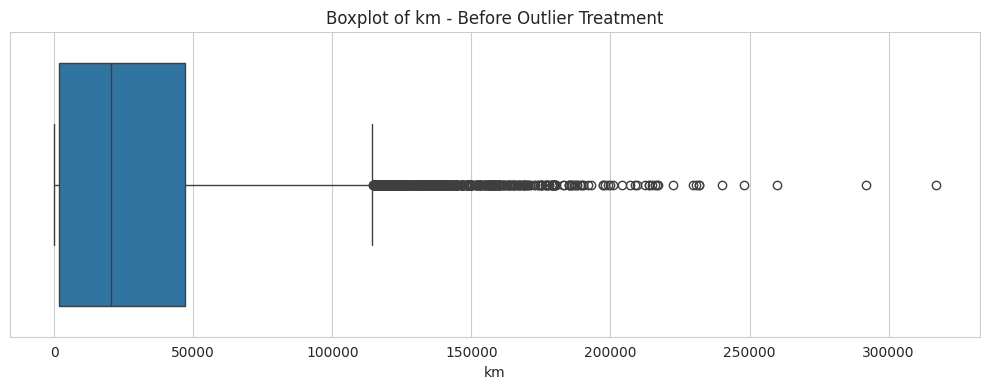

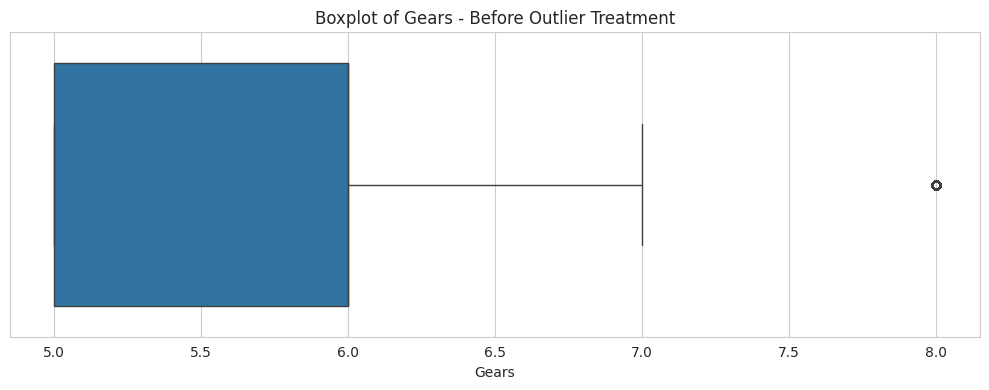

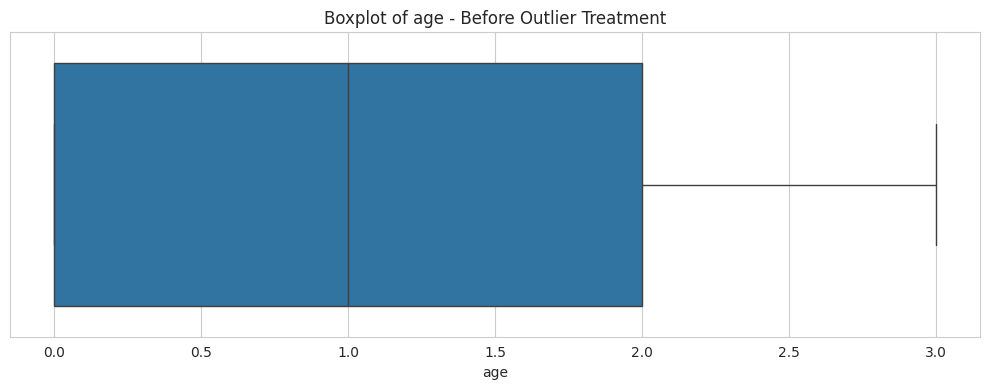

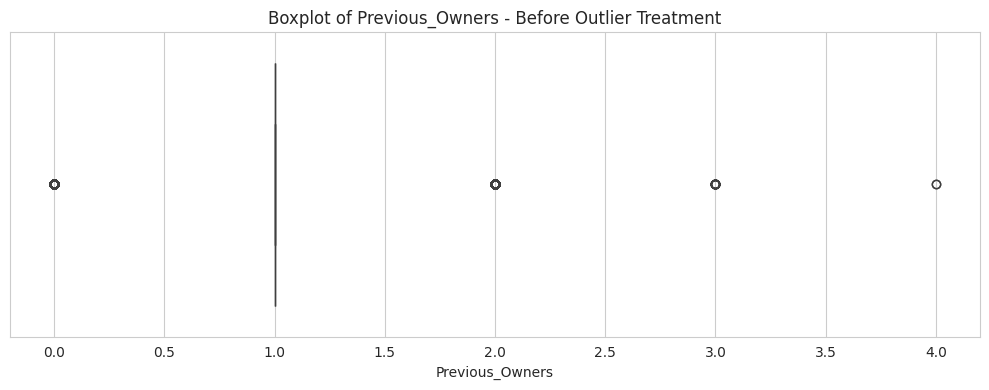

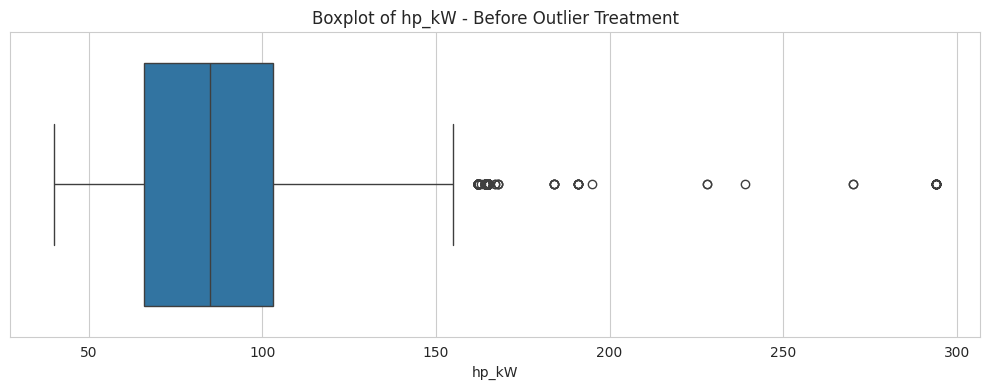

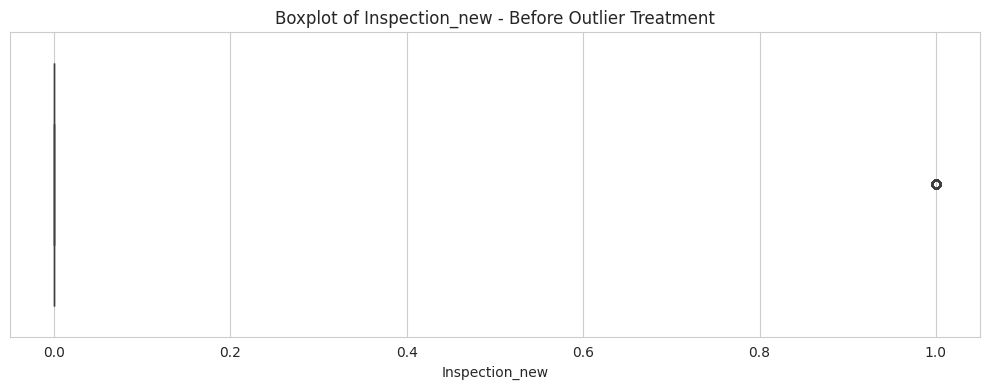

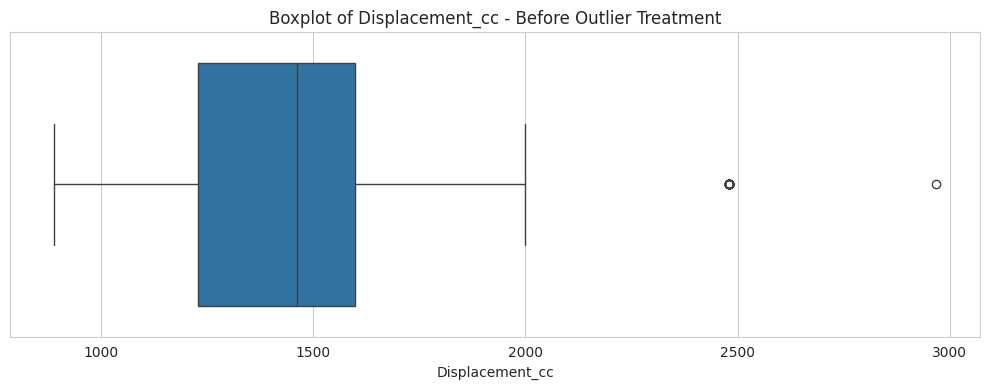

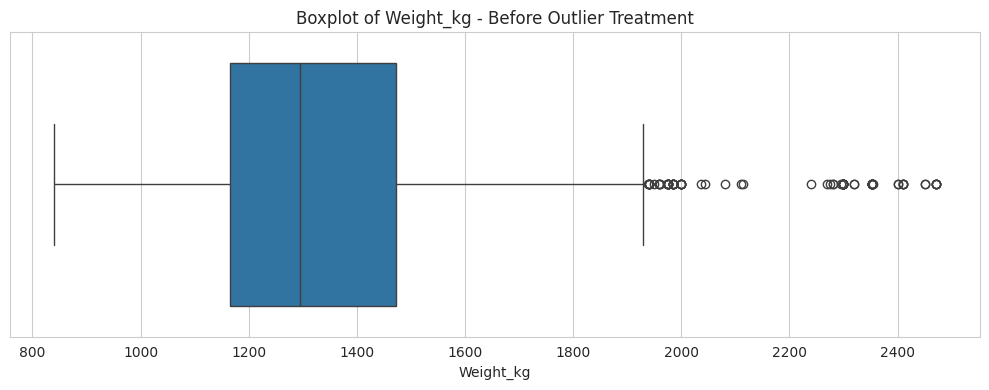

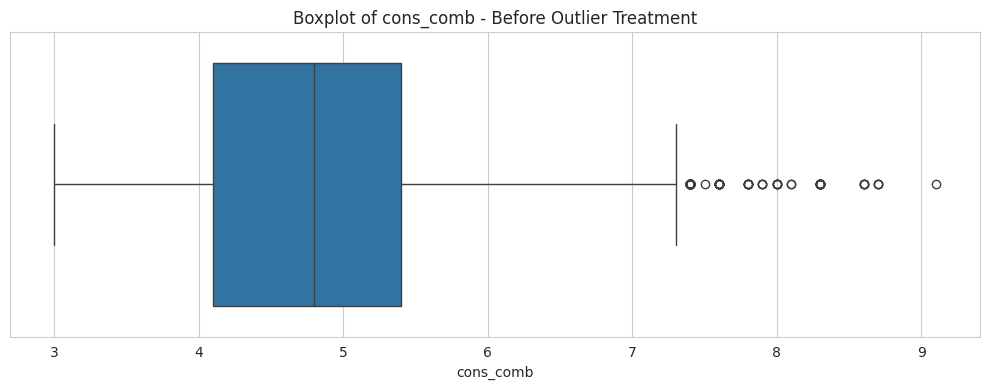

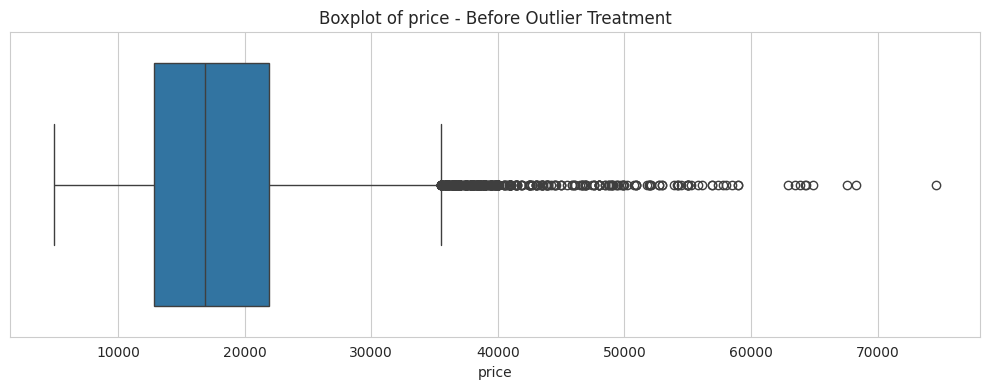

In [ ]:
# Step 4 — Boxplots BEFORE outlier treatment
# Boxplots for numerical predictors and target
# BEFORE outlier treatment

outlier_columns = numeric_predictors + ['price']

for col in outlier_columns:

    plt.figure(figsize=(10, 4))

    sns.boxplot(x=df[col])

    plt.title(f'Boxplot of {col} - Before Outlier Treatment')
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

In [ ]:
# Identify the actual extreme observations
# Price outliers

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

price_outliers = df[
    (df['price'] < lower_bound) |
    (df['price'] > upper_bound)
]

print("Number of potential price outliers:",
      len(price_outliers))

display(
    price_outliers[
        ['make_model', 'price', 'km', 'age', 'hp_kW']
    ].sort_values('price', ascending=False).head(20)
)

Number of potential price outliers: 479


,make_model,price,km,age,hp_kW
3648,Audi A3,74600,13000.0,1.0,294.0
15822,Renault Espace,68320,4307.0,0.0,118.0
3649,Audi A3,67600,37747.0,2.0,294.0
3587,Audi A3,64900,35000.0,1.0,294.0
15824,Renault Espace,64332,1.0,0.0,165.0
15827,Renault Espace,64298,15.0,0.0,165.0
3595,Audi A3,63900,10.0,0.0,294.0
15829,Renault Espace,63477,8.0,0.0,147.0
3590,Audi A3,62900,700.0,0.0,294.0
3594,Audi A3,58990,7500.0,1.0,228.0


#### **2.3.2** <font color =red> [3 marks] </font>
Handle the outliers suitably.

In [ ]:
# step 1 # Continuous numerical predictors selected for outlier treatment

continuous_predictors = [
    'km',
    'age',
    'hp_kW',
    'Displacement_cc',
    'Weight_kg',
    'cons_comb'
]

print("Continuous predictors for outlier treatment:")
print(continuous_predictors)

Continuous predictors for outlier treatment:
['km', 'age', 'hp_kW', 'Displacement_cc', 'Weight_kg', 'cons_comb']


In [ ]:
# Step 2 — Create cleaned dataset and apply IQR capping
# IMPORTANT: Calculate IQR limits from the training partition only
# to avoid using future test observations to define preprocessing bounds.
from sklearn.model_selection import train_test_split
# Create the same deterministic train/test row split that will later
# be used for the model. Only row indices are used here.
all_indices = np.arange(len(df_clean))
train_indices_for_capping, test_indices_for_capping = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=42
)

iqr_bounds = {}

for col in continuous_predictors:

    Q1 = df_clean.loc[train_indices_for_capping, col].quantile(0.25)
    Q3 = df_clean.loc[train_indices_for_capping, col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    iqr_bounds[col] = (lower_bound, upper_bound)

    # Apply training-derived bounds to the complete dataset.
    df_clean[col] = df_clean[col].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Outlier capping completed using training-derived IQR bounds.")
display(pd.DataFrame(iqr_bounds, index=['Lower Bound', 'Upper Bound']).T)


Outlier capping completed using training-derived IQR bounds.


,Lower Bound,Upper Bound
km,-61000.00,111800.00
age,-3.00,5.00
hp_kW,10.50,158.50
Displacement_cc,675.50,2151.50
Weight_kg,682.00,1970.00
cons_comb,2.15,7.35


In [ ]:
# Step 3 - Verify the treatment numerically
# Compare before and after outlier counts

outlier_comparison = []

for col in continuous_predictors:

    # Before treatment
    Q1_before = df[col].quantile(0.25)
    Q3_before = df[col].quantile(0.75)
    IQR_before = Q3_before - Q1_before

    lower_before = Q1_before - 1.5 * IQR_before
    upper_before = Q3_before + 1.5 * IQR_before

    before_count = (
        (df[col] < lower_before) |
        (df[col] > upper_before)
    ).sum()

    # After treatment
    Q1_after = df_clean[col].quantile(0.25)
    Q3_after = df_clean[col].quantile(0.75)
    IQR_after = Q3_after - Q1_after

    lower_after = Q1_after - 1.5 * IQR_after
    upper_after = Q3_after + 1.5 * IQR_after

    after_count = (
        (df_clean[col] < lower_after) |
        (df_clean[col] > upper_after)
    ).sum()

    outlier_comparison.append({
        'Feature': col,
        'Outliers Before': before_count,
        'Outliers After': after_count
    })

outlier_comparison = pd.DataFrame(outlier_comparison)

display(outlier_comparison)

,Feature,Outliers Before,Outliers After
0,km,689,657
1,age,0,0
2,hp_kW,361,0
3,Displacement_cc,21,0
4,Weight_kg,87,0
5,cons_comb,125,0


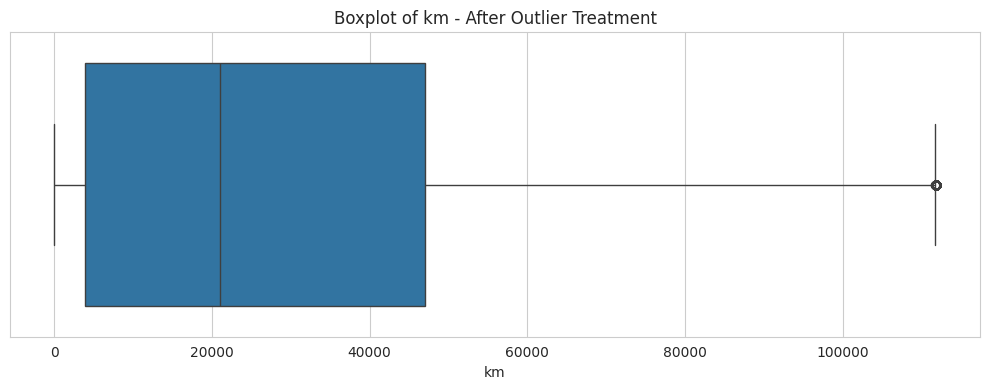

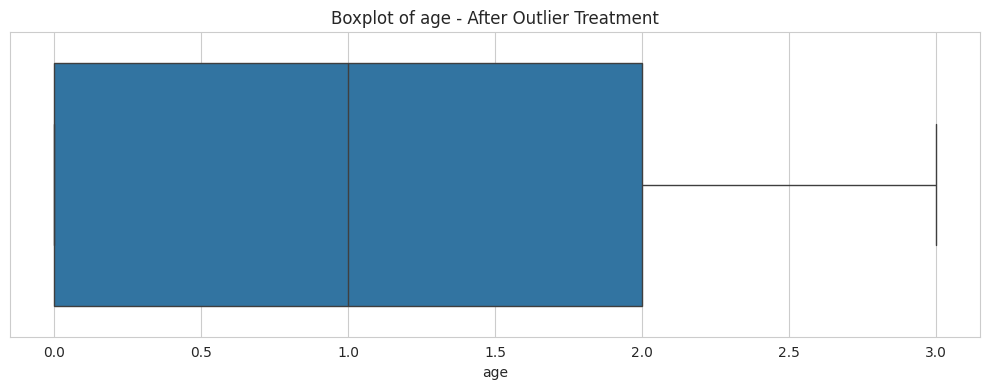

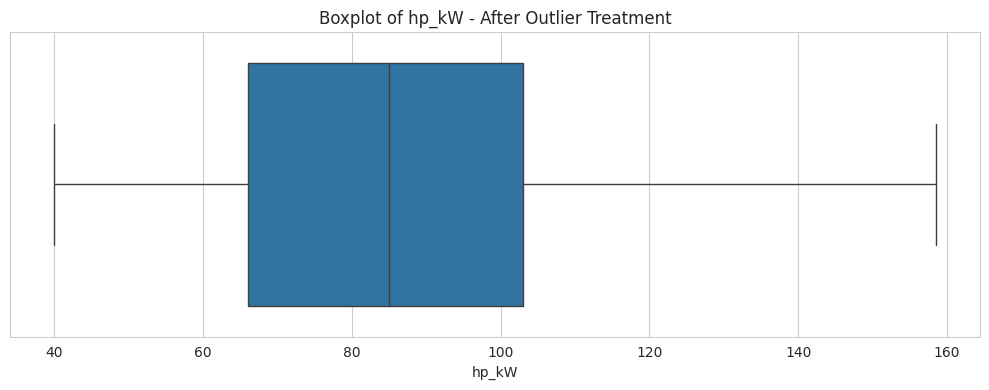

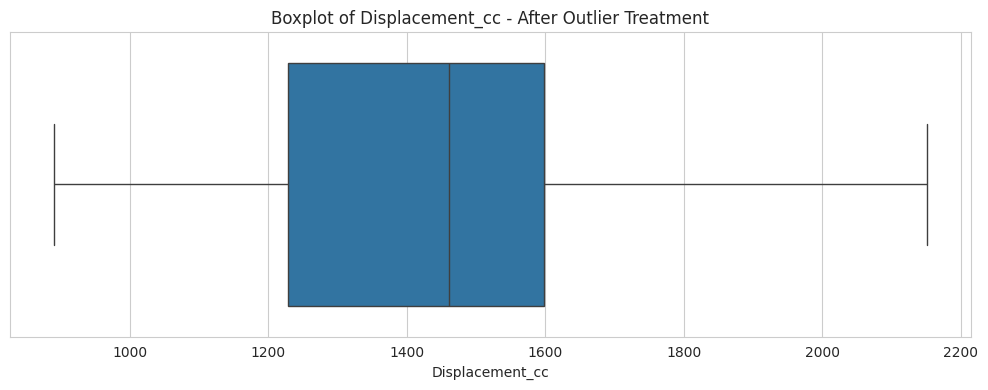

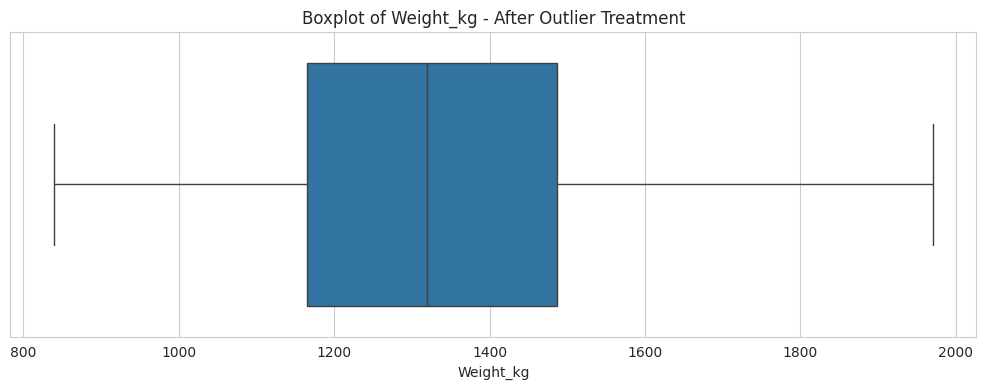

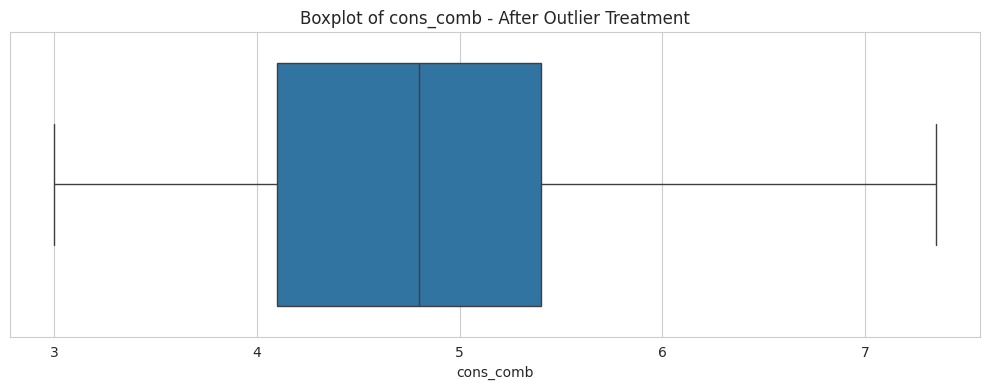

In [ ]:
# step 4 Boxplots AFTER outlier treatment
# Boxplots AFTER outlier treatment

for col in continuous_predictors:

    plt.figure(figsize=(10, 4))

    sns.boxplot(x=df_clean[col])

    plt.title(f'Boxplot of {col} - After Outlier Treatment')
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

In [ ]:
# step 5 — Create the log-transformed target
# Create log-transformed target variable

df_clean['log_price'] = np.log1p(df_clean['price'])

print("Log-transformed target created.")
display(df_clean[['price', 'log_price']].head())

Log-transformed target created.


,price,log_price
0,15770,9.665928
1,14500,9.581973
2,14640,9.591581
3,14500,9.581973
4,16790,9.728598


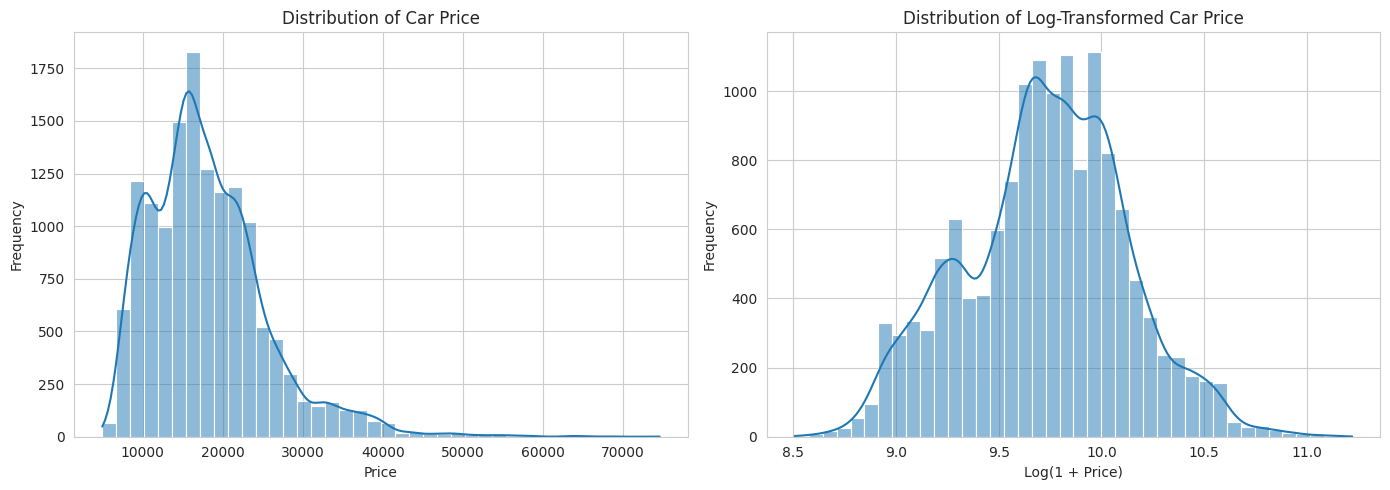

In [ ]:
# Step 6 — Compare price and log(price)
# Compare original price and log-transformed price

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original price
sns.histplot(
    df_clean['price'],
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].set_title('Distribution of Car Price')
axes[0].set_xlabel('Price')
axes[0].set_ylabel('Frequency')

# Log-transformed price
sns.histplot(
    df_clean['log_price'],
    bins=40,
    kde=True,
    ax=axes[1]
)

axes[1].set_title('Distribution of Log-Transformed Car Price')
axes[1].set_xlabel('Log(1 + Price)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### **2.4 Feature Engineering** <font color = red> [11 marks] </font>

#### **2.4.1**
Fix any redundant columns and create new ones if needed.

In [ ]:
#### Fix/create columns as needed

# 2.4.1 Fix redundant columns and create new features
# Step 1 — Check for duplicate columns
# Check for duplicate columns

duplicate_columns = df_clean.columns[df_clean.columns.duplicated()].tolist()

print("Duplicate columns:", duplicate_columns)

Duplicate columns: []


In [ ]:
# Step 2 — Check for constant columns
# Check for constant columns

constant_columns = [
    col for col in df_clean.columns
    if df_clean[col].nunique(dropna=False) <= 1
]

print("Constant columns:", constant_columns)

Constant columns: []


In [ ]:
# Step 3 — Check duplicate observations
# Check duplicate rows

duplicate_rows = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


In [ ]:
# Check duplicate rows
duplicate_rows = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_rows)

# Remove duplicate rows
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Shape after removing duplicates:", df_clean.shape)

Number of duplicate rows: 0
Shape after removing duplicates: (14238, 25)


In [ ]:
# Verify that duplicates have been removed
duplicate_rows_after = df_clean.duplicated().sum()
print("Duplicate rows after treatment:", duplicate_rows_after)
print("Current dataset shape:", df_clean.shape)

Duplicate rows after treatment: 0
Current dataset shape: (14238, 25)


Exact 1677 duplicate rows were identified in the dataset and removed to prevent repeated observations from receiving disproportionate influence during model training. The dataset was reset to a continuous index after duplicate removal.

In [ ]:
 # Create Useful Derived Features
 # 1. Create car age group
 # Create car age group

df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[-1, 2, 5, 10, np.inf],
    labels=['0-2 years', '3-5 years', '6-10 years', '10+ years']
)

display(df_clean[['age', 'age_group']].head())

,age,age_group
0,3.0,3-5 years
1,2.0,0-2 years
2,3.0,3-5 years
3,3.0,3-5 years
4,3.0,3-5 years


In [ ]:
# Distribution of age groups

display(
    df_clean['age_group']
    .value_counts()
    .sort_index()
)

,count
age_group,
0-2 years,10899
3-5 years,3339
6-10 years,0
10+ years,0


In [ ]:
# 2. Create kilometres driven per year
# Create kilometres driven per year

df_clean['km_per_year'] = (
    df_clean['km'] / (df_clean['age'] + 1)
)

display(
    df_clean[
        ['km', 'age', 'km_per_year']
    ].head()
)

,km,age,km_per_year
0,56013.0,3.0,14003.250000
1,80000.0,2.0,26666.666667
2,83450.0,3.0,20862.500000
3,73000.0,3.0,18250.000000
4,16200.0,3.0,4050.000000


In [ ]:
# 3. Create power-to-displacement ratio

df_clean['hp_per_litre'] = (
    df_clean['hp_kW'] /
    (df_clean['Displacement_cc'] / 1000)
)

display(
    df_clean[
        ['hp_kW', 'Displacement_cc', 'hp_per_litre']
    ].head()
)

,hp_kW,Displacement_cc,hp_per_litre
0,66.0,1422.0,46.413502
1,141.0,1798.0,78.420467
2,85.0,1598.0,53.191489
3,66.0,1422.0,46.413502
4,66.0,1422.0,46.413502


In [ ]:
# 4. Verify the derived features
# Verify newly created derived features

derived_features = [
    'age_group',
    'km_per_year',
    'hp_per_litre'
]

display(df_clean[derived_features].head())

print("\nSummary of numerical derived features:")
display(
    df_clean[
        ['km_per_year', 'hp_per_litre']
    ].describe().T
)

,age_group,km_per_year,hp_per_litre
0,3-5 years,14003.250000,46.413502
1,0-2 years,26666.666667,78.420467
2,3-5 years,20862.500000,53.191489
3,3-5 years,18250.000000,46.413502
4,3-5 years,4050.000000,46.413502



Summary of numerical derived features:


,count,mean,std,min,25%,50%,75%,max
km_per_year,14238.0,10245.411572,8844.122436,0.000000,2495.12500,8774.500000,14957.312500,111800.00000
hp_per_litre,14238.0,62.198962,14.444201,27.378508,50.68836,62.578223,73.669533,140.14014


In [ ]:
# 5.Check for invalid or infinite values
# Check for infinite values

for col in ['km_per_year', 'hp_per_litre']:
    print(
        col,
        "infinite values:",
        np.isinf(df_clean[col]).sum(),
        "| missing values:",
        df_clean[col].isna().sum()
    )

# hp_per_litre is mathematically derived from hp_kW and Displacement_cc.
# It can introduce additional multicollinearity, so remove it BEFORE
# encoding, train/test splitting and model fitting.
if 'hp_per_litre' in df_clean.columns:
    df_clean.drop(columns=['hp_per_litre'], inplace=True)
    print("\nRemoved redundant feature: hp_per_litre")

print("\nDataset shape after redundant-feature removal:", df_clean.shape)



km_per_year infinite values: 0 | missing values: 0
hp_per_litre infinite values: 0 | missing values: 0

Removed redundant feature: hp_per_litre

Dataset shape after redundant-feature removal: (14238, 26)


Useful Derived Features: Three meaningful derived features were created based on domain understanding of used-car pricing. age_group categorizes vehicles into different age ranges to capture potential nonlinear depreciation effects. km_per_year measures average annual usage by relating total kilometres driven to vehicle age. hp_per_litre represents engine power relative to engine displacement and provides an indicator of engine characteristics. These features were created using only predictor variables to avoid target leakage.

#### **2.4.2** <font color =red> [4 marks] </font>
Analysis and feature engineering on `['Comfort_Convenience', 'Entertainment_Media', 'Extras', 'Safety_Security']`.

These columns contains lists of features present. Decide on how to include these features in the predictors.

In [ ]:
# step 1-Check unique values in each feature spec column

spec_columns = [
    'Comfort_Convenience',
    'Entertainment_Media',
    'Extras',
    'Safety_Security'
]

display(df_clean[spec_columns].head())

# Check unique values in each feature specification column

for col in spec_columns:
    print(f"\n{'='*60}")
    print(f"Column: {col}")
    print(f"Number of unique values: {df_clean[col].nunique()}")
    print("\nSample unique values:")
    display(df_clean[col].dropna().unique()[:10])

,Comfort_Convenience,Entertainment_Media,Extras,Safety_Security
0,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,Hands-free equipment,On-board comput...","Alloy wheels,Catalytic Converter,Voice Control","ABS,Central door lock,Daytime running lights,D..."
1,"Air conditioning,Automatic climate control,Hil...","Bluetooth,Hands-free equipment,On-board comput...","Alloy wheels,Sport seats,Sport suspension,Voic...","ABS,Central door lock,Central door lock with r..."
2,"Air conditioning,Cruise control,Electrical sid...","MP3,On-board computer","Alloy wheels,Voice Control","ABS,Central door lock,Daytime running lights,D..."
3,"Air suspension,Armrest,Auxiliary heating,Elect...","Bluetooth,CD player,Hands-free equipment,MP3,O...","Alloy wheels,Sport seats,Voice Control","ABS,Alarm system,Central door lock with remote..."
4,"Air conditioning,Armrest,Automatic climate con...","Bluetooth,CD player,Hands-free equipment,MP3,O...","Alloy wheels,Sport package,Sport suspension,Vo...","ABS,Central door lock,Driver-side airbag,Elect..."



Column: Comfort_Convenience
Number of unique values: 6196

Sample unique values:


array(['Air conditioning,Armrest,Automatic climate control,Cruise control,Electrical side mirrors,Hill Holder,Leather steering wheel,Light sensor,Multi-function steering wheel,Navigation system,Park Distance Control,Parking assist system sensors rear,Power windows,Rain sensor,Seat heating,Start-stop system',
       'Air conditioning,Automatic climate control,Hill Holder,Leather steering wheel,Lumbar support,Parking assist system sensors rear,Power windows,Start-stop system,Tinted windows',
       'Air conditioning,Cruise control,Electrical side mirrors,Hill Holder,Leather steering wheel,Multi-function steering wheel,Navigation system,Park Distance Control,Parking assist system sensors front,Parking assist system sensors rear,Power windows,Seat heating,Start-stop system',
       'Air suspension,Armrest,Auxiliary heating,Electrical side mirrors,Heads-up display,Hill Holder,Leather steering wheel,Light sensor,Lumbar support,Multi-function steering wheel,Navigation system,Power windows,Rai


Column: Entertainment_Media
Number of unique values: 346

Sample unique values:


array(['Bluetooth,Hands-free equipment,On-board computer,Radio',
       'Bluetooth,Hands-free equipment,On-board computer,Radio,Sound system',
       'MP3,On-board computer',
       'Bluetooth,CD player,Hands-free equipment,MP3,On-board computer,Radio,Sound system,USB',
       'Bluetooth,CD player,Hands-free equipment,MP3,On-board computer,Radio,USB',
       'Bluetooth,Hands-free equipment,On-board computer,Radio,Sound system,USB',
       'Bluetooth,CD player,Hands-free equipment,On-board computer,Radio,Sound system,USB',
       'CD player,MP3,Radio', 'Radio',
       'CD player,Hands-free equipment,On-board computer,Radio,USB'],
      dtype=object)


Column: Extras
Number of unique values: 659

Sample unique values:


array(['Alloy wheels,Catalytic Converter,Voice Control',
       'Alloy wheels,Sport seats,Sport suspension,Voice Control',
       'Alloy wheels,Voice Control',
       'Alloy wheels,Sport seats,Voice Control',
       'Alloy wheels,Sport package,Sport suspension,Voice Control',
       'Alloy wheels,Sport package,Sport seats,Sport suspension',
       'Alloy wheels', 'Alloy wheels,Shift paddles',
       'Alloy wheels,Sport seats',
       'Alloy wheels,Catalytic Converter,Sport package,Sport seats,Sport suspension,Voice Control'],
      dtype=object)


Column: Safety_Security
Number of unique values: 4442

Sample unique values:


array(['ABS,Central door lock,Daytime running lights,Driver-side airbag,Electronic stability control,Fog lights,Immobilizer,Isofix,Passenger-side airbag,Power steering,Side airbag,Tire pressure monitoring system,Traction control,Xenon headlights',
       'ABS,Central door lock,Central door lock with remote control,Daytime running lights,Driver-side airbag,Electronic stability control,Head airbag,Immobilizer,Isofix,Passenger-side airbag,Power steering,Side airbag,Tire pressure monitoring system,Traction control,Xenon headlights',
       'ABS,Central door lock,Daytime running lights,Driver-side airbag,Electronic stability control,Immobilizer,Isofix,Passenger-side airbag,Power steering,Side airbag,Tire pressure monitoring system,Traction control',
       'ABS,Alarm system,Central door lock with remote control,Driver drowsiness detection,Driver-side airbag,Electronic stability control,Emergency system,Head airbag,Immobilizer,Isofix,Passenger-side airbag,Power steering,Side airbag,Tire pres

In [ ]:
# Step 2 — Better analysis: count individual features

# Check individual features and their frequencies

for col in spec_columns:

    individual_features = (
        df_clean[col]
        .fillna('')
        .str.split(',')
        .explode()
        .str.strip()
    )

    # Remove empty values
    individual_features = individual_features[
        individual_features != ''
    ]

    print(f"\n{col}")
    print(f"Number of individual features: {individual_features.nunique()}")

    display(
        individual_features
        .value_counts()
        .head(15)
        .to_frame('Frequency')
    )


Comfort_Convenience
Number of individual features: 38


,Frequency
Comfort_Convenience,
Air conditioning,13590
Power windows,13308
Electrical side mirrors,11307
Multi-function steering wheel,10648
Cruise control,10442
Park Distance Control,9638
Parking assist system sensors rear,9175
Leather steering wheel,8884
Start-stop system,8431



Entertainment_Media
Number of individual features: 10


,Frequency
Entertainment_Media,
Radio,11858
On-board computer,11851
Bluetooth,11377
Hands-free equipment,9345
USB,8053
MP3,5705
CD player,4613
Digital radio,2076
Sound system,1971



Extras
Number of individual features: 17


,Frequency
Extras,
Alloy wheels,12491
Voice Control,3987
Touch screen,3747
Sport seats,2884
Roof rack,2794
Catalytic Converter,2090
Sport suspension,1438
Sport package,1065
Trailer hitch,632



Safety_Security
Number of individual features: 29


,Frequency
Safety_Security,
ABS,13519
Driver-side airbag,13416
Passenger-side airbag,13017
Power steering,13002
Electronic stability control,12686
Side airbag,12604
Central door lock,12161
Isofix,11291
Traction control,10805


In [ ]:
# Step 3 — Analyse individual specifications
# Frequency analysis of individual specifications

for col in spec_columns:

    individual_specs = (
        df_clean[col]
        .fillna('')
        .str.split(',')
        .explode()
        .str.strip()
    )

    # Remove empty values
    individual_specs = individual_specs[
        individual_specs != ''
    ]

    print(f"\nTop 15 individual specifications in {col}:")

    display(
        individual_specs
        .value_counts()
        .head(15)
        .to_frame('Frequency')
    )


Top 15 individual specifications in Comfort_Convenience:


,Frequency
Comfort_Convenience,
Air conditioning,13590
Power windows,13308
Electrical side mirrors,11307
Multi-function steering wheel,10648
Cruise control,10442
Park Distance Control,9638
Parking assist system sensors rear,9175
Leather steering wheel,8884
Start-stop system,8431



Top 15 individual specifications in Entertainment_Media:


,Frequency
Entertainment_Media,
Radio,11858
On-board computer,11851
Bluetooth,11377
Hands-free equipment,9345
USB,8053
MP3,5705
CD player,4613
Digital radio,2076
Sound system,1971



Top 15 individual specifications in Extras:


,Frequency
Extras,
Alloy wheels,12491
Voice Control,3987
Touch screen,3747
Sport seats,2884
Roof rack,2794
Catalytic Converter,2090
Sport suspension,1438
Sport package,1065
Trailer hitch,632



Top 15 individual specifications in Safety_Security:


,Frequency
Safety_Security,
ABS,13519
Driver-side airbag,13416
Passenger-side airbag,13017
Power steering,13002
Electronic stability control,12686
Side airbag,12604
Central door lock,12161
Isofix,11291
Traction control,10805


Out of these features, we will check the ones which are present in most of the cars or are absent from most of the cars. These kinds of features can be removed as they just increase the dimensionality without explaining the variance.

In [ ]:
# Drop features from df
# Drop original multi-valued specification columns from df_clean

spec_columns_to_remove = [
    'Comfort_Convenience',
    'Entertainment_Media',
    'Extras',
    'Safety_Security'
]

existing_spec_columns = [
    col for col in spec_columns_to_remove
    if col in df_clean.columns
]

if existing_spec_columns:
    df_clean.drop(columns=existing_spec_columns, inplace=True)

print("Original specification columns remaining:",
      [col for col in spec_columns_to_remove if col in df_clean.columns])

print("Number of engineered specification features:",
      len([
          col for col in df_clean.columns
          if any(col.startswith(spec_col + "_") for spec_col in spec_columns_to_remove)
      ]))

Original specification columns remaining: []
Number of engineered specification features: 0


In [ ]:
# Check that the columns have been removed

print(df_clean.columns.tolist())

['make_model', 'body_type', 'price', 'vat', 'km', 'Type', 'Fuel', 'Gears', 'age', 'Previous_Owners', 'hp_kW', 'Inspection_new', 'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Displacement_cc', 'Weight_kg', 'Drive_chain', 'cons_comb', 'log_price', 'age_group', 'km_per_year']


#### **2.4.3** <font color =red> [3 marks] </font>
Perform feature encoding.

In [ ]:
# Step 1 — Identify categorical variables
# Identify categorical predictors

categorical_predictors = df_clean.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Categorical predictors:")
print(categorical_predictors)

Categorical predictors:
['make_model', 'body_type', 'vat', 'Type', 'Fuel', 'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Drive_chain', 'age_group']


In [ ]:
# Step 2 - Check number of unique categories

categorical_summary = pd.DataFrame({
    'Feature': categorical_predictors,
    'Number of Categories': [
        df_clean[col].nunique()
        for col in categorical_predictors
    ]
})

display(categorical_summary)

,Feature,Number of Categories
0,make_model,8
1,body_type,5
2,vat,2
3,Type,5
4,Fuel,3
5,Paint_Type,3
6,Upholstery_type,2
7,Gearing_Type,3
8,Drive_chain,3
9,age_group,2


In [ ]:
print("Categorical columns:")
print(categorical_predictors)

print("\nUnique categories:")
for col in categorical_predictors:
    print(col, ":", df_clean[col].nunique())

Categorical columns:
['make_model', 'body_type', 'vat', 'Type', 'Fuel', 'Paint_Type', 'Upholstery_type', 'Gearing_Type', 'Drive_chain', 'age_group']

Unique categories:
make_model : 8
body_type : 5
vat : 2
Type : 5
Fuel : 3
Paint_Type : 3
Upholstery_type : 2
Gearing_Type : 3
Drive_chain : 3
age_group : 2


In [ ]:
# Step 3 — One-hot encode categorical variables
# One-hot encode categorical variables

# Separate predictors and target
X = df_clean.drop(columns=['price', 'log_price'])
y = df_clean['log_price']

# One-hot encode all categorical predictors
X = pd.get_dummies(
    X,
    columns=categorical_predictors,
    drop_first=True,
    dtype=int
)

print("Shape after encoding:", X.shape)

Shape after encoding: (14238, 38)


In [ ]:
# Step 4 — Check the encoded dataset
# Display encoded dataset

display(X.head())

print("\nData types:")
display(X.dtypes.value_counts())

,km,Gears,age,Previous_Owners,hp_kW,Inspection_new,Displacement_cc,Weight_kg,cons_comb,km_per_year,make_model_Audi A3,make_model_Opel Astra,make_model_Opel Corsa,make_model_Opel Insignia,make_model_Other,make_model_Renault Clio,make_model_Renault Espace,body_type_Other,body_type_Sedans,body_type_Station wagon,body_type_Van,vat_VAT deductible,Type_Employee's car,Type_New,Type_Pre-registered,Type_Used,Fuel_Diesel,Fuel_Other,Paint_Type_Other,Paint_Type_Uni/basic,Upholstery_type_Part/Full Leather,Gearing_Type_Manual,Gearing_Type_Semi-automatic,Drive_chain_Other,Drive_chain_front,age_group_3-5 years,age_group_6-10 years,age_group_10+ years
0,56013.0,7.0,3.0,2.0,66.0,1,1422.0,1220.0,3.8,14003.250000,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0
1,80000.0,7.0,2.0,1.0,141.0,0,1798.0,1255.0,5.6,26666.666667,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0
2,83450.0,7.0,3.0,1.0,85.0,0,1598.0,1135.0,3.8,20862.500000,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0
3,73000.0,6.0,3.0,1.0,66.0,0,1422.0,1195.0,3.8,18250.000000,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0
4,16200.0,7.0,3.0,1.0,66.0,1,1422.0,1135.0,4.1,4050.000000,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,0,0,0,0,1,1,0,0



Data types:


,count
int64,29
float64,9


In [ ]:
# Step 5 — Check for remaining categorical columns
# Check whether any categorical columns remain

remaining_categorical = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Remaining categorical columns:")
print(remaining_categorical)

Remaining categorical columns:
[]


In [ ]:
print('price' in X.columns)
print('log_price' in X.columns)

False
False


In [ ]:
# Step 6 — Check missing values
# Check missing values after encoding
missing_values = X.isnull().sum()

print("Total missing values:", missing_values.sum())

if missing_values.sum() > 0:
    display(
        missing_values[missing_values > 0]
    )

Total missing values: 0


In [ ]:
print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

Predictor shape: (14238, 38)
Target shape: (14238,)


Feature Encoding: Categorical predictors were converted into numerical representations using one-hot encoding. Since the categorical variables do not have an inherent ordinal relationship, one-hot encoding was preferred over label encoding. The drop_first=True option was used to remove one reference category from each categorical variable and reduce perfect multicollinearity. The resulting dataset contains numerical predictor variables suitable for Linear Regression, Ridge Regression, and Lasso Regression.

#### **2.4.4** <font color =red> [2 marks] </font>
Split the data into training and testing sets.

In [ ]:
# Split data
from sklearn.model_selection import train_test_split

# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training set shape: (9966, 38)
Testing set shape: (4272, 38)
Training target shape: (9966,)
Testing target shape: (4272,)


#### **2.4.5** <font color =red> [2 marks] </font>
Scale the features.

In [ ]:
# Scale features
from sklearn.preprocessing import StandardScaler

# Create StandardScaler
scaler = StandardScaler()

# Fit scaler ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

print("Original testing shape:", X_test.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Original training shape: (9966, 38)
Scaled training shape: (9966, 38)
Original testing shape: (4272, 38)
Scaled testing shape: (4272, 38)


In [ ]:
# Check mean and standard deviation of scaled training features

print("Mean of scaled training features:")
print(np.mean(X_train_scaled, axis=0)[:10])

print("\nStandard deviation of scaled training features:")
print(np.std(X_train_scaled, axis=0)[:10])

Mean of scaled training features:
[-4.91947108e-17  4.45960748e-16  1.42593365e-18 -1.35820180e-16
  1.61843469e-16  4.59863601e-17  3.18696170e-16 -4.12094824e-16
  7.98879325e-16  9.91023884e-17]

Standard deviation of scaled training features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## **3 Linear Regression Models** <font color =red> [35 marks] </font>


### **3.1 Baseline Linear Regression Model** <font color =red> [10 marks] </font>

#### **3.1.1** <font color =red> [5 marks] </font>
Build and fit a basic linear regression model. Perform evaluation using suitable metrics.

In [ ]:
# # Initialise and train model
# Step 1 — Import Linear Regression
from sklearn.linear_model import LinearRegression

In [ ]:
# Step 2 — Create and fit the model
# Create the baseline Linear Regression model

linear_model = LinearRegression()

# Fit the model on scaled training data
linear_model.fit(X_train_scaled, y_train)

print("Linear Regression model fitted successfully.")


Linear Regression model fitted successfully.


In [ ]:
# Step 3 — Generate predictions
# Generate predictions on training and testing data

y_train_pred = linear_model.predict(X_train_scaled)
y_test_pred = linear_model.predict(X_test_scaled)

print("Predictions generated successfully.")


Predictions generated successfully.


In [ ]:
# Step 4 — Evaluate the model's performance
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
 )

# Calculate evaluation metrics

train_mae = mean_absolute_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

print("===== Training Performance =====")
print(f"MAE  : {train_mae:.4f}")
print(f"MSE  : {train_mse:.4f}")
print(f"RMSE : {train_rmse:.4f}")
print(f"R²   : {train_r2:.4f}")

print("\n===== Testing Performance =====")
print(f"MAE  : {test_mae:.4f}")
print(f"MSE  : {test_mse:.4f}")
print(f"RMSE : {test_rmse:.4f}")
print(f"R²   : {test_r2:.4f}")


===== Training Performance =====
MAE  : 0.0871
MSE  : 0.0138
RMSE : 0.1176
R²   : 0.9126

===== Testing Performance =====
MAE  : 0.0859
MSE  : 0.0135
RMSE : 0.1164
R²   : 0.9147


In [ ]:
# Step 5 — Create a clean evaluation table

# Model evaluation summary

linear_regression_results = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'MAE': [train_mae, test_mae],
    'MSE': [train_mse, test_mse],
    'RMSE': [train_rmse, test_rmse],
    'R²': [train_r2, test_r2]
})

display(linear_regression_results)

,Dataset,MAE,MSE,RMSE,R²
0,Training,0.087150,0.013826,0.117582,0.912554
1,Testing,0.085877,0.013539,0.116356,0.914667


In [ ]:
# Step 6 — Convert predictions back to original price
# Convert log-price predictions back to original price scale

y_test_actual = np.expm1(y_test)
y_test_pred_actual = np.expm1(y_test_pred)

# Evaluate on original price scale

test_mae_price = mean_absolute_error(
    y_test_actual,
    y_test_pred_actual
)

test_rmse_price = np.sqrt(
    mean_squared_error(
        y_test_actual,
        y_test_pred_actual
    )
)

test_r2_price = r2_score(
    y_test_actual,
    y_test_pred_actual
)

print("===== Testing Performance on Original Price Scale =====")
print(f"MAE  : €{test_mae_price:,.2f}")
print(f"RMSE : €{test_rmse_price:,.2f}")
print(f"R²   : {test_r2_price:.4f}")

===== Testing Performance on Original Price Scale =====
MAE  : €1,608.30
RMSE : €2,496.26
R²   : 0.8850


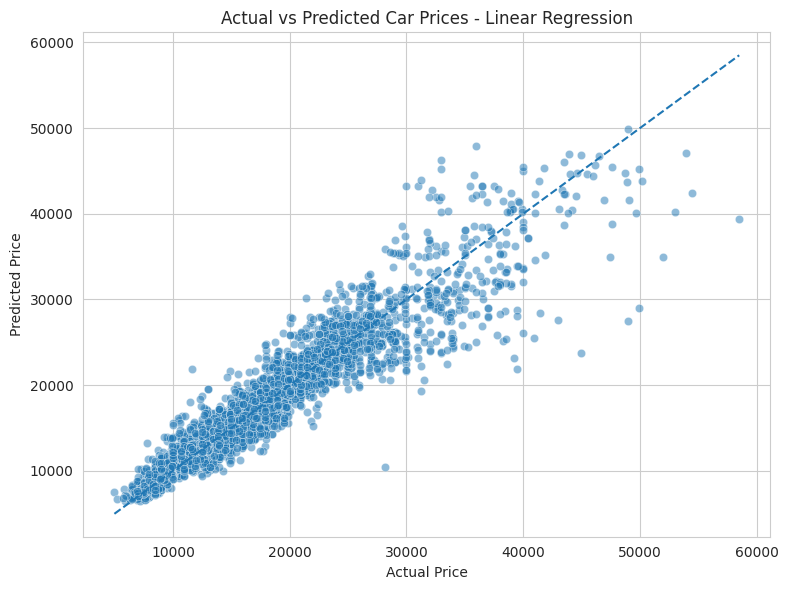

In [ ]:
# Step 7 — Actual vs predicted price plot
# Actual vs Predicted Price

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test_actual,
    y=y_test_pred_actual,
    alpha=0.5
)

# Perfect prediction line
min_value = min(
    y_test_actual.min(),
    y_test_pred_actual.min()
)

max_value = max(
    y_test_actual.max(),
    y_test_pred_actual.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Car Prices - Linear Regression')

plt.tight_layout()
plt.show()

In [ ]:
# Step 8 — Residuals
# Calculate residuals

residuals = y_test - y_test_pred

print("Residual summary:")
display(pd.Series(residuals).describe())

Residual summary:


,log_price
count,4272.000000
mean,-0.001269
std,0.116362
min,-0.633138
25%,-0.064712
50%,-0.001770
75%,0.067454
max,0.998030


Baseline Linear Regression: A multiple Linear Regression model was fitted using the standardized training predictors and the log-transformed car price as the target variable. Model performance was evaluated using MAE, MSE, RMSE, and R² on both the training and testing datasets. The test-set metrics were used as the primary measure of generalization performance. Predictions were additionally transformed back to the original price scale using the inverse expm1 transformation to provide business-interpretable error measures.

#### **3.1.2** <font color =red> [5 marks] </font>
Analyse residuals and check other assumptions of linear regression.

Check for linearity by analysing residuals vs predicted values

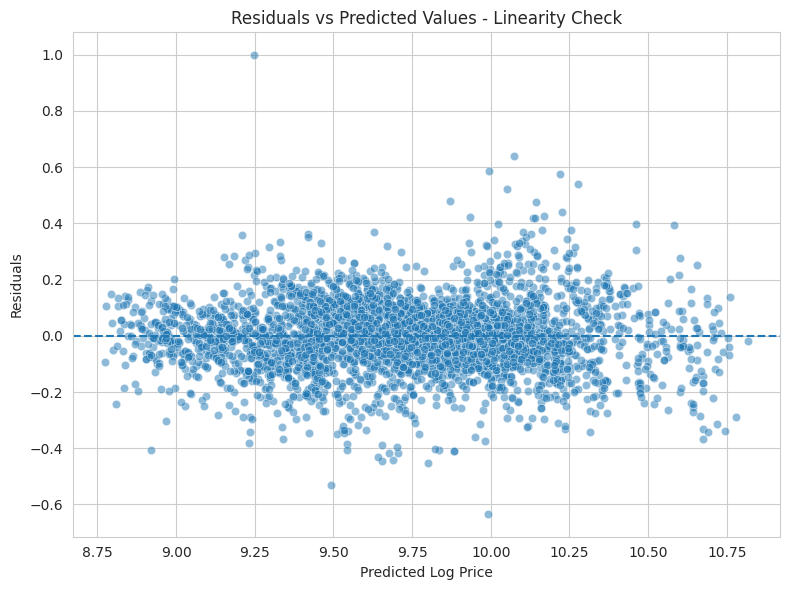

In [ ]:
# Linearity check: Plot residuals vs fitted values
# Calculate residuals

residuals = y_test - y_test_pred

# Plot residuals vs fitted (predicted) values

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test_pred,
    y=residuals,
    alpha=0.5
)

# Add horizontal reference line at zero
plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Predicted Log Price')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values - Linearity Check')

plt.tight_layout()
plt.show()


Check normality in residual distribution

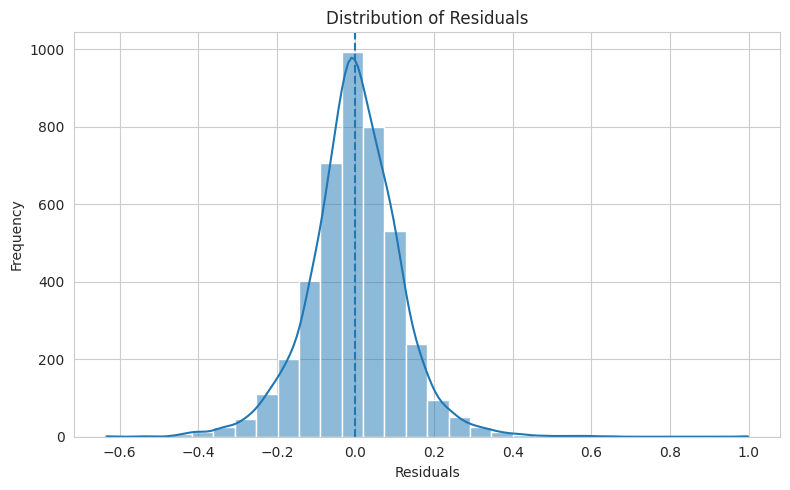

In [ ]:
# Check normality of residuals using histogram

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.axvline(
    x=0,
    linestyle='--'
)

plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Distribution of Residuals')

plt.tight_layout()
plt.show()

<Figure size 700x700 with 0 Axes>

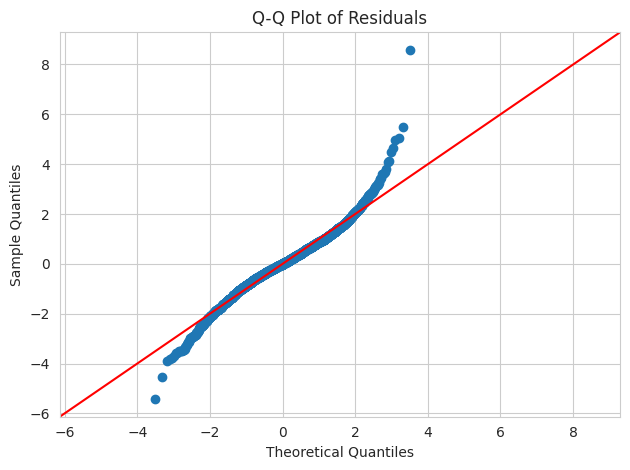

In [ ]:
# Check the normality of residuals by plotting their distribution

# Q-Q plot for checking normality of residuals

import statsmodels.api as sm

plt.figure(figsize=(7, 7))

sm.qqplot(
    residuals,
    line='45',
    fit=True
)

plt.title('Q-Q Plot of Residuals')
plt.tight_layout()
plt.show()

In [ ]:
# Jarque-Bera test for residual normality

from scipy.stats import jarque_bera

jb_stat, jb_pvalue = jarque_bera(residuals)

print(f"Jarque-Bera Statistic: {jb_stat:.4f}")
print(f"p-value: {jb_pvalue:.4f}")

Jarque-Bera Statistic: 1744.3663
p-value: 0.0000


Normality of residuals: The distribution of residuals was assessed using a histogram with KDE and a Q-Q plot. The histogram was examined for approximate symmetry and bell-shaped distribution, while the Q-Q plot was used to assess how closely the residuals followed a normal distribution. The Jarque-Bera test was additionally performed to statistically assess the normality assumption.

Check multicollinearity using Variance Inflation Factor (VIF) and handle features with high VIF.

In [ ]:
# Check for multicollinearity and handle

import numpy as np
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor

# ------------------------------------------------------------
# 1. Select original continuous numerical predictors
# ------------------------------------------------------------

vif_features = [
    'km',
    'age',
    'hp_kW',
    'Displacement_cc',
    'Weight_kg',
    'cons_comb'
]

# Create a separate dataframe for VIF analysis
X_vif = df_clean[vif_features].copy()

# Check for missing values
print("Missing values in VIF features:")
display(X_vif.isnull().sum())

# ------------------------------------------------------------
# 2. Calculate VIF
# ------------------------------------------------------------

vif_data = pd.DataFrame()

vif_data['Feature'] = X_vif.columns

vif_data['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

# ------------------------------------------------------------
# 3. Classify multicollinearity
# ------------------------------------------------------------

vif_data['Multicollinearity'] = np.where(
    vif_data['VIF'] > 10,
    'High',
    np.where(
        vif_data['VIF'] > 5,
        'Moderate',
        'Acceptable'
    )
)

# Sort from highest to lowest VIF
vif_data = vif_data.sort_values(
    by='VIF',
    ascending=False
).reset_index(drop=True)

print("Variance Inflation Factor (VIF) Results:")
display(vif_data)

Missing values in VIF features:


,0
km,0
age,0
hp_kW,0
Displacement_cc,0
Weight_kg,0
cons_comb,0


Variance Inflation Factor (VIF) Results:


,Feature,VIF,Multicollinearity
0,Weight_kg,62.471269,High
1,Displacement_cc,50.438414,High
2,hp_kW,28.396508,High
3,cons_comb,24.875521,High
4,age,6.908063,Moderate
5,km,5.403998,Moderate


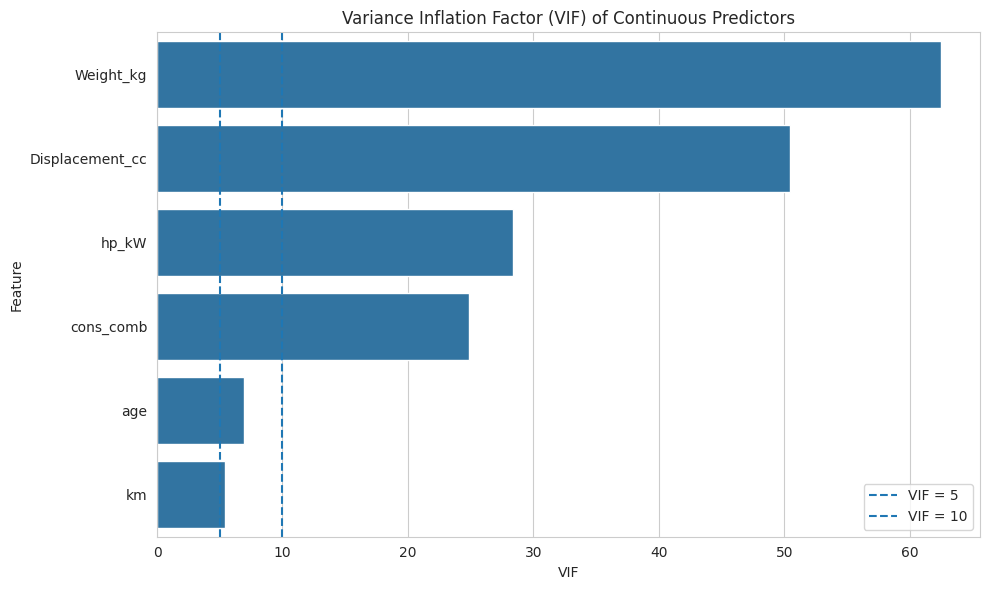

In [ ]:
# =======================================================
# VIF VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 6))

sns.barplot(
    data=vif_data,
    x='VIF',
    y='Feature'
)

plt.axvline(
    x=5,
    linestyle='--',
    label='VIF = 5'
)

plt.axvline(
    x=10,
    linestyle='--',
    label='VIF = 10'
)

plt.title('Variance Inflation Factor (VIF) of Continuous Predictors')
plt.xlabel('VIF')
plt.ylabel('Feature')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Identify specifically the high-VIF variables
# ============================================================
# IDENTIFY HIGH VIF FEATURES
# ============================================================

high_vif_features = vif_data[
    vif_data['VIF'] > 10
]

print("Features with high multicollinearity (VIF > 10):")
display(high_vif_features)

Features with high multicollinearity (VIF > 10):


,Feature,VIF,Multicollinearity
0,Weight_kg,62.471269,High
1,Displacement_cc,50.438414,High
2,hp_kW,28.396508,High
3,cons_comb,24.875521,High


In [ ]:
# Handle High VIF
# ============================================================
# REMOVE REDUNDANT ENGINEERED FEATURES
# ============================================================

# Handle multicollinearity / redundant engineered features

# hp_per_litre was removed earlier, before the model matrix was created,
# because it is derived directly from hp_kW and Displacement_cc.
print("Redundant engineered-feature check:")

if 'hp_per_litre' in df_clean.columns:
    df_clean.drop(columns=['hp_per_litre'], inplace=True)
    print("Removed: hp_per_litre")
else:
    print("hp_per_litre is already removed.")

print("Current dataset shape:", df_clean.shape)

print("\nHigh-VIF variables are retained because they represent meaningful vehicle characteristics.")
print("Ridge and Lasso regularisation will be used to control coefficient instability caused by multicollinearity.")


Redundant engineered-feature check:
hp_per_litre is already removed.
Current dataset shape: (14238, 22)

High-VIF variables are retained because they represent meaningful vehicle characteristics.
Ridge and Lasso regularisation will be used to control coefficient instability caused by multicollinearity.


In [ ]:
# Check for zero-variance features

zero_variance_features = [
    col for col in df_clean.columns
    if df_clean[col].nunique(dropna=False) <= 1
]

print("Zero-variance features:")
print(zero_variance_features)

print("\nNumber of zero-variance features:",
      len(zero_variance_features))

Zero-variance features:
[]

Number of zero-variance features: 0


Multicollinearity was assessed using the Variance Inflation Factor (VIF) for the original continuous numerical predictors. Variables with VIF values greater than 10 were considered to have high multicollinearity. Several vehicle-related predictors showed evidence of multicollinearity because characteristics such as engine power, displacement, fuel consumption and vehicle weight are naturally related. These predictors were not automatically removed because they contain meaningful information for vehicle price prediction. Redundant derived variables were removed where appropriate, while Ridge and Lasso regularisation were subsequently used to control the impact of multicollinearity and improve model stability.

### **3.2 Ridge Regression Implementation** <font color =red> [10 marks] </font>

#### **3.2.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [ ]:
# List of alphas to tune for Ridge regularisation
alpha_values = [
    0.001, 0.01, 0.1, 0.5,
    1, 2, 5, 10,
    20, 50, 100, 200
]

print("Alpha values:", alpha_values)


Alpha values: [0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10, 20, 50, 100, 200]


#### **3.2.2** <font color =red> [4 marks] </font>
Apply Ridge Regularisation and find the best value of alpha from the list

In [ ]:
# Applying Ridge regression
# 3.2.2 Ridge Regression — Hyperparameter Tuning

from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

# Coarse alpha values
ridge_alpha_values = [
    0.001, 0.01, 0.1, 0.5, 1, 2,
    5, 10, 20, 50, 100, 200
]

ridge_grid = GridSearchCV(
    estimator=Ridge(),
    param_grid={'alpha': ridge_alpha_values},
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1
)

# IMPORTANT: tune only on training data
ridge_grid.fit(X_train_scaled, y_train)

# Best alpha from cross-validation
best_ridge_alpha_coarse = ridge_grid.best_params_['alpha']

# GridSearchCV returns negative MAE,
# so convert it to positive MAE
best_ridge_cv_mae_coarse = -ridge_grid.best_score_

print("Ridge Coarse Tuning Results")
print("----------------------------")
print("Best Alpha:", best_ridge_alpha_coarse)
print("Best CV MAE:", best_ridge_cv_mae_coarse)

Ridge Coarse Tuning Results
----------------------------
Best Alpha: 10
Best CV MAE: 0.087547743117035


In [ ]:
# Fine tuning around the best alpha


fine_alpha_values = [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]

fine_ridge_grid = GridSearchCV(
    estimator=Ridge(),
    param_grid={'alpha': fine_alpha_values},
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1
)

fine_ridge_grid.fit(X_train_scaled, y_train)

print("Alpha values actually tested:")
print(fine_ridge_grid.cv_results_['param_alpha'])

best_ridge_alpha = fine_ridge_grid.best_params_['alpha']
best_ridge_cv_mae = -fine_ridge_grid.best_score_

print("\nRidge Fine Tuning Results")
print("-------------------------")
print("Best Alpha after Fine Tuning:", best_ridge_alpha)
print("Best CV MAE:", best_ridge_cv_mae)

Alpha values actually tested:
[5 6 7 8 9 10 11 12 13 14 15]

Ridge Fine Tuning Results
-------------------------
Best Alpha after Fine Tuning: 9
Best CV MAE: 0.08754774246026224


In [ ]:
# Final Ridge Regression Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create final Ridge model using the selected alpha
ridge_final = Ridge(alpha=best_ridge_alpha)

# Fit final model on the complete training data
ridge_final.fit(X_train_scaled, y_train)

print("Final Ridge model fitted successfully.")
print("Selected Alpha:", best_ridge_alpha)

Final Ridge model fitted successfully.
Selected Alpha: 9


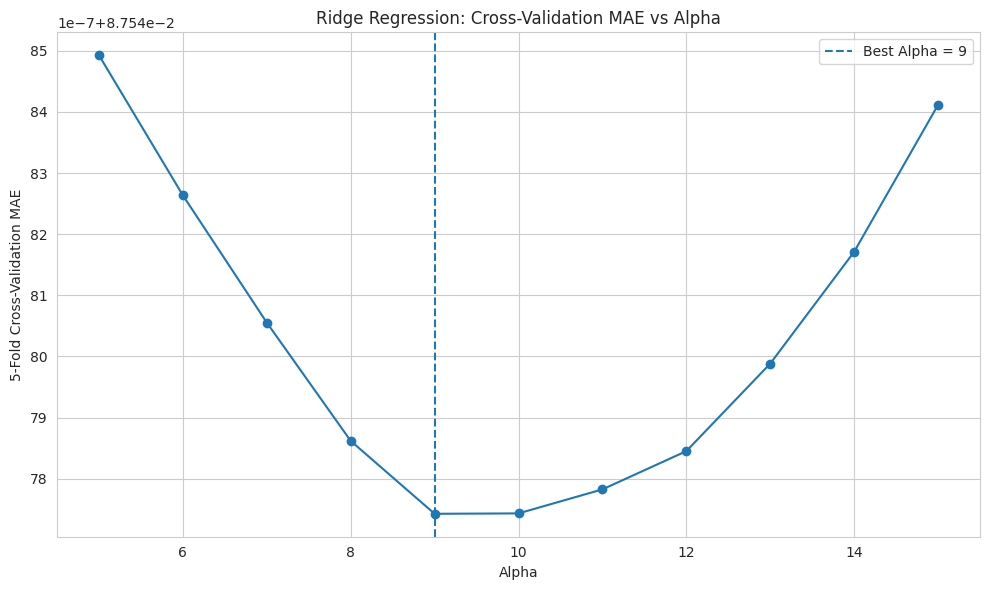

In [ ]:
# Plot train and test scores against alpha
import pandas as pd
import matplotlib.pyplot as plt

# Get CV results from the fine-tuned Ridge model
ridge_results_df = pd.DataFrame(fine_ridge_grid.cv_results_)

# Convert negative MAE to positive MAE
ridge_results_df['CV MAE'] = -ridge_results_df['mean_test_score']

# Sort by alpha
ridge_results_df = ridge_results_df.sort_values('param_alpha')

# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    ridge_results_df['param_alpha'].astype(float),
    ridge_results_df['CV MAE'],
    marker='o'
)

# Mark the selected alpha
plt.axvline(
    best_ridge_alpha,
    linestyle='--',
    label=f'Best Alpha = {best_ridge_alpha}'
)

plt.xlabel('Alpha')
plt.ylabel('5-Fold Cross-Validation MAE')
plt.title('Ridge Regression: Cross-Validation MAE vs Alpha')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Find the best alpha value.

In [ ]:
# Best alpha value

# Best alpha value
best_ridge_alpha = fine_ridge_grid.best_params_['alpha']

print("Best alpha value for Ridge Regression:", best_ridge_alpha)

Best alpha value for Ridge Regression: 9


In [ ]:
# Best score (negative MAE)

best_ridge_score = fine_ridge_grid.best_score_

print("Best score (negative MAE):", best_ridge_score)

Best score (negative MAE): -0.08754774246026224


We will get some best value of alpha above. This however is not the most accurate value but the best value from the given list. Now we have a rough estimate of the range that best alpha falls in. Let us do another iteration over the values in a smaller range.

Ridge Regression achieved its best performance at an alpha value of 9, with a best cross-validation score (negative MAE) of -0.0875.

#### **3.2.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [ ]:
# Take a smaller range of alpha to test
fine_alpha_values = [
    5, 6, 7, 8, 9,
    10,
    11, 12, 13, 14, 15
]

print("Fine-tuning alpha values:")
print(fine_alpha_values)

Fine-tuning alpha values:
[5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


In [ ]:
# Applying Ridge regression for fine-tuning

from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
import pandas as pd


# GridSearchCV for fine tuning
fine_ridge_grid = GridSearchCV(
    estimator=Ridge(),
    param_grid={'alpha': fine_alpha_values},
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1
)

# IMPORTANT: Use ONLY training data for tuning
fine_ridge_grid.fit(X_train_scaled, y_train)

# Best alpha
best_ridge_alpha = fine_ridge_grid.best_params_['alpha']

# Convert negative MAE to positive MAE
best_ridge_cv_mae = -fine_ridge_grid.best_score_

print("Fine-tuned Ridge Regression Results")
print("------------------------------------")
print("Best Alpha:", best_ridge_alpha)
print("Best Cross-Validation MAE:", best_ridge_cv_mae)

Fine-tuned Ridge Regression Results
------------------------------------
Best Alpha: 9
Best Cross-Validation MAE: 0.08754774246026224


In [ ]:
# Create a results DataFrame

fine_ridge_results_df = pd.DataFrame({
    'Alpha': fine_ridge_grid.cv_results_['param_alpha'].astype(float),
    'CV MAE': -fine_ridge_grid.cv_results_['mean_test_score']
})

fine_ridge_results_df = fine_ridge_results_df.sort_values(
    by='CV MAE'
)

display(fine_ridge_results_df)

,Alpha,CV MAE
4,9.0,0.087548
5,10.0,0.087548
6,11.0,0.087548
7,12.0,0.087548
3,8.0,0.087548
8,13.0,0.087548
2,7.0,0.087548
9,14.0,0.087548
1,6.0,0.087548
10,15.0,0.087548


In [ ]:
# Fit final Ridge model using the selected alpha

ridge_final = Ridge(alpha=best_ridge_alpha)

ridge_final.fit(X_train_scaled, y_train)

# Predict on test data ONLY for final evaluation
y_pred_ridge = ridge_final.predict(X_test_scaled)

print("Final Ridge Alpha:", best_ridge_alpha)

Final Ridge Alpha: 9


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

ridge_mae = mean_absolute_error(y_test, y_pred_ridge)
ridge_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))
ridge_r2 = r2_score(y_test, y_pred_ridge)

print("\nFinal Ridge Regression - Test Performance")
print("------------------------------------------")
print("MAE :", round(ridge_mae, 6))
print("RMSE:", round(ridge_rmse, 6))
print("R²  :", round(ridge_r2, 6))


Final Ridge Regression - Test Performance
------------------------------------------
MAE : 0.085859
RMSE: 0.116348
R²  : 0.914679


Plot the error-alpha graph again and find the actual optimal value for alpha.

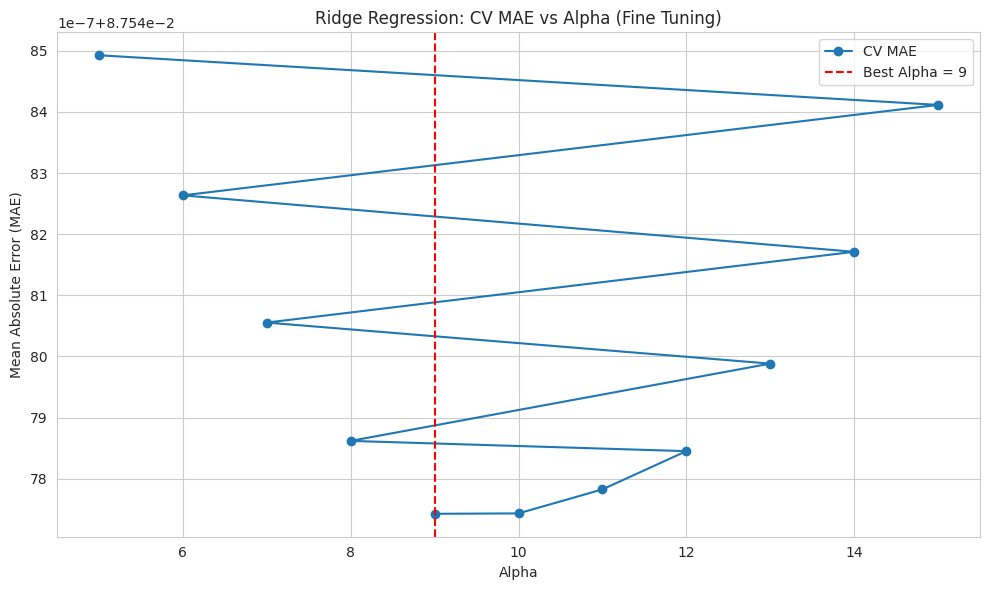

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Plot train and test scores against alpha

plt.figure(figsize=(10, 6))

plt.plot(
    fine_ridge_results_df['Alpha'],
    fine_ridge_results_df['CV MAE'],
    marker='o',
    label='CV MAE'
)

# Mark the best alpha
plt.axvline(
    best_ridge_alpha,
    linestyle='--',
    color='red',
    label=f'Best Alpha = {best_ridge_alpha}'
)

plt.xlabel('Alpha')
plt.ylabel('Mean Absolute Error (MAE)')
plt.title('Ridge Regression: CV MAE vs Alpha (Fine Tuning)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

The plot shows that the Ridge cross-validation MAE decreases as alpha increases from 5 to 9, reaching its minimum at α = 9. Beyond α = 9, the CV MAE gradually increases. Therefore, α = 9 is selected as the optimal Ridge regularization parameter based on 5-fold cross-validation.

In [ ]:
# Best alpha value

best_alpha_fine = fine_ridge_results_df.loc[
    fine_ridge_results_df['CV MAE'].idxmin(),
    'Alpha'
]

print("Best alpha value for Ridge Regression:", best_alpha_fine)

Best alpha value for Ridge Regression: 9.0


In [ ]:
# Best score (negative MAE)

best_score_fine = -fine_ridge_results_df['CV MAE'].min()

print("Best score (negative MAE):", best_score_fine)

Best score (negative MAE): -0.08754774246026224


In [ ]:
# Set best alpha for Ridge regression

best_alpha = best_alpha_fine

print("Best alpha:", best_alpha)


# Fit the Ridge model to get the coefficients of the fitted model

ridge_final = Ridge(alpha=best_alpha)

ridge_final.fit(
    X_train_scaled,
    y_train
)

# Get coefficients
ridge_coefficients = ridge_final.coef_

print("Ridge model fitted successfully.")
print("Number of coefficients:", len(ridge_coefficients))



Best alpha: 9.0
Ridge model fitted successfully.
Number of coefficients: 38


In [ ]:
# Fit the Ridge model to get the coefficients of the fitted model

ridge_model = Ridge(alpha=best_alpha)

ridge_model.fit(
    X_train_scaled,
    y_train
)

# Get the coefficients
ridge_coefficients = ridge_model.coef_

print("Ridge model fitted successfully.")
print("Ridge coefficients:")
print(ridge_coefficients)

Ridge model fitted successfully.
Ridge coefficients:
[-0.08079582  0.01518401 -0.11734563  0.00238457  0.11992543  0.00255752
 -0.00605205 -0.01051577  0.00515385 -0.01115997  0.03551736 -0.07790734
 -0.15130176 -0.01634043 -0.0192358  -0.11851112  0.04511767 -0.0070777
 -0.00517336 -0.00565948 -0.00221602  0.00411306 -0.02770804 -0.02077763
 -0.02782994 -0.04345636  0.01318473  0.00050133  0.00077202 -0.00140062
  0.01592732 -0.06911213  0.02324361 -0.00198322 -0.00560566  0.01245807
  0.          0.        ]


In [ ]:
# Show the coefficients for each feature

ridge_coefficients_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Ridge Coefficient': ridge_model.coef_
})

display(ridge_coefficients_df)


,Feature,Ridge Coefficient
0,km,-0.080796
1,Gears,0.015184
2,age,-0.117346
3,Previous_Owners,0.002385
4,hp_kW,0.119925
5,Inspection_new,0.002558
6,Displacement_cc,-0.006052
7,Weight_kg,-0.010516
8,cons_comb,0.005154
9,km_per_year,-0.011160


In [ ]:
# Sort coefficients by absolute magnitude

ridge_coefficients_df['Absolute Coefficient'] = (
    ridge_coefficients_df['Ridge Coefficient'].abs()
)

ridge_coefficients_df = ridge_coefficients_df.sort_values(
    by='Absolute Coefficient',
    ascending=False
).reset_index(drop=True)

display(ridge_coefficients_df)

,Feature,Ridge Coefficient,Absolute Coefficient
0,make_model_Opel Corsa,-0.151302,0.151302
1,hp_kW,0.119925,0.119925
2,make_model_Renault Clio,-0.118511,0.118511
3,age,-0.117346,0.117346
4,km,-0.080796,0.080796
5,make_model_Opel Astra,-0.077907,0.077907
6,Gearing_Type_Manual,-0.069112,0.069112
7,make_model_Renault Espace,0.045118,0.045118
8,Type_Used,-0.043456,0.043456
9,make_model_Audi A3,0.035517,0.035517


In [ ]:
# Evaluate the Ridge model on the test data

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions
y_pred_ridge = ridge_final.predict(X_test_scaled)

# Calculate evaluation metrics
ridge_test_mae = mean_absolute_error(y_test, y_pred_ridge)
ridge_test_mse = mean_squared_error(y_test, y_pred_ridge)
ridge_test_rmse = np.sqrt(ridge_test_mse)
ridge_test_r2 = r2_score(y_test, y_pred_ridge)

print("Ridge Regression Test Set Results")
print("----------------------------------")
print("Best Alpha:", best_ridge_alpha)
print("Test MAE :", round(ridge_test_mae, 6))
print("Test MSE :", round(ridge_test_mse, 6))
print("Test RMSE:", round(ridge_test_rmse, 6))
print("Test R²  :", round(ridge_test_r2, 6))

Ridge Regression Test Set Results
----------------------------------
Best Alpha: 9
Test MAE : 0.085859
Test MSE : 0.013537
Test RMSE: 0.116348
Test R²  : 0.914679


The final Ridge Regression model with α = 9 achieved a test MAE of 0.085859, RMSE of 0.116348, and R² of 0.914679. The R² indicates that the model explains approximately 91.47% of the variation in log-transformed car prices. The relatively low MAE and RMSE indicate good predictive accuracy, while the test performance suggests that the Ridge model generalizes well to unseen data.

### **3.3 Lasso Regression Implementation** <font color =red> [10 marks] </font>

#### **3.3.1** <font color =red> [2 marks] </font>
Define a list of random alpha values

In [ ]:
# List of alphas to tune for Lasso regularisation

lasso_alpha_values = [
    0.00001,
    0.00002,
    0.00005,
    0.0001,
    0.0002,
    0.0005,
    0.001,
    0.002,
    0.005
]

print("Alpha values for Lasso Regression:")
print(lasso_alpha_values)

Alpha values for Lasso Regression:
[1e-05, 2e-05, 5e-05, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005]


A range of small alpha values was defined for Lasso regularisation to evaluate different levels of L1 penalty. The range allows the model to identify an appropriate balance between prediction accuracy and coefficient shrinkage.

#### **3.3.2** <font color =red> [4 marks] </font>
Apply Lasso Regularisation and find the best value of alpha from the list

In [ ]:
# Initialise Lasso regression model
from sklearn.linear_model import Lasso

lasso = Lasso(max_iter=10000)

print("Lasso regression model initialized successfully.")

Lasso regression model initialized successfully.


In [ ]:
# Lasso Regression - Coarse Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV

fine_lasso_alpha_values = [
    0.00001,
    0.00002,
    0.00005,
    0.00010,
    0.00020,
    0.00050,
    0.00100,
    0.00200,
    0.00500
]
lasso_grid_coarse = GridSearchCV(
    estimator=Lasso(max_iter=10000),
    param_grid={'alpha': lasso_alpha_values},
    scoring='neg_mean_absolute_error',
    cv=5,
    n_jobs=-1
)

# IMPORTANT: select alpha using ONLY training data.
lasso_grid_coarse.fit(X_train_scaled, y_train)

best_lasso_alpha_coarse = lasso_grid_coarse.best_params_['alpha']
best_lasso_cv_mae_coarse = -lasso_grid_coarse.best_score_

print("Lasso Coarse Tuning Results")
print("---------------------------")
print("Best Alpha:", best_lasso_alpha_coarse)
print("Best CV MAE:", best_lasso_cv_mae_coarse)


Lasso Coarse Tuning Results
---------------------------
Best Alpha: 0.0002
Best CV MAE: 0.08752827647218914


,Alpha,CV MAE
0,0.00001,0.087548
1,0.00002,0.087547
2,0.00005,0.087542
3,0.00010,0.087535
4,0.00020,0.087528
5,0.00050,0.087556
6,0.00100,0.087688
7,0.00200,0.088302
8,0.00500,0.090301


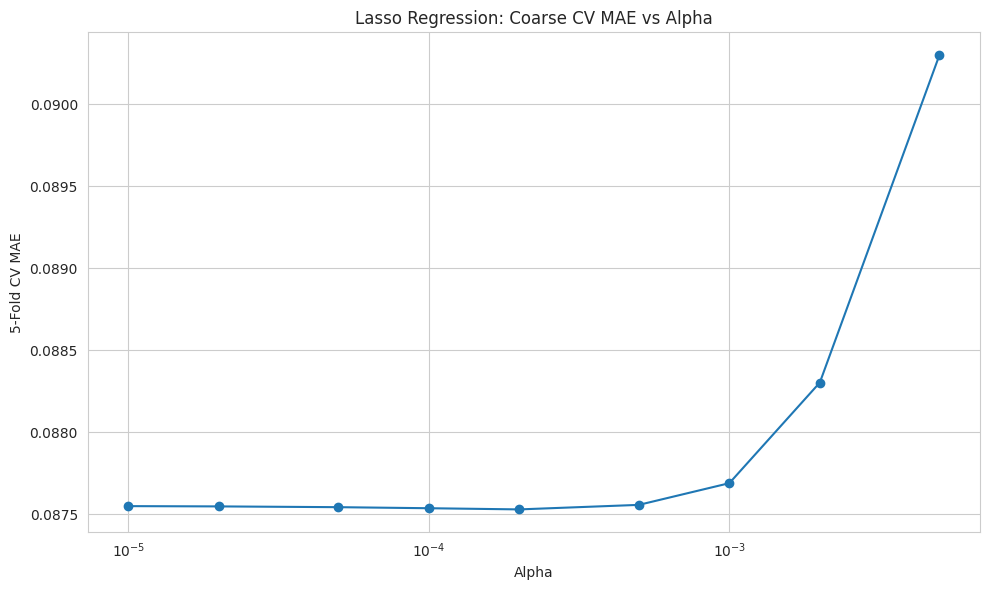

In [ ]:
# Lasso coarse tuning results

lasso_coarse_results_df = pd.DataFrame({
    'Alpha': lasso_grid_coarse.cv_results_['param_alpha'].astype(float),
    'CV MAE': -lasso_grid_coarse.cv_results_['mean_test_score']
}).sort_values('Alpha')

display(lasso_coarse_results_df)

plt.figure(figsize=(10, 6))
plt.plot(
    lasso_coarse_results_df['Alpha'],
    lasso_coarse_results_df['CV MAE'],
    marker='o'
)
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('5-Fold CV MAE')
plt.title('Lasso Regression: Coarse CV MAE vs Alpha')
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Plot train and test scores against alpha

from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error

lasso_results = []

for alpha in lasso_alpha_values:

    lasso_model = Lasso(alpha=alpha, max_iter=10000)
    lasso_model.fit(X_train_scaled, y_train)

    # Predictions
    train_pred = lasso_model.predict(X_train_scaled)
    test_pred = lasso_model.predict(X_test_scaled)

    # Calculate MAE
    train_mae = mean_absolute_error(y_train, train_pred)
    test_mae = mean_absolute_error(y_test, test_pred)

    lasso_results.append({
        'Alpha': alpha,
        'Train MAE': train_mae,
        'Test MAE': test_mae
    })

# Create results DataFrame
lasso_results_df = pd.DataFrame(lasso_results)

display(lasso_results_df)

,Alpha,Train MAE,Test MAE
0,0.00001,0.087148,0.085873
1,0.00002,0.087148,0.085871
2,0.00005,0.087146,0.085863
3,0.00010,0.087145,0.085851
4,0.00020,0.087151,0.085841
5,0.00050,0.087230,0.085871
6,0.00100,0.087362,0.085890
7,0.00200,0.088021,0.086279
8,0.00500,0.090015,0.087967


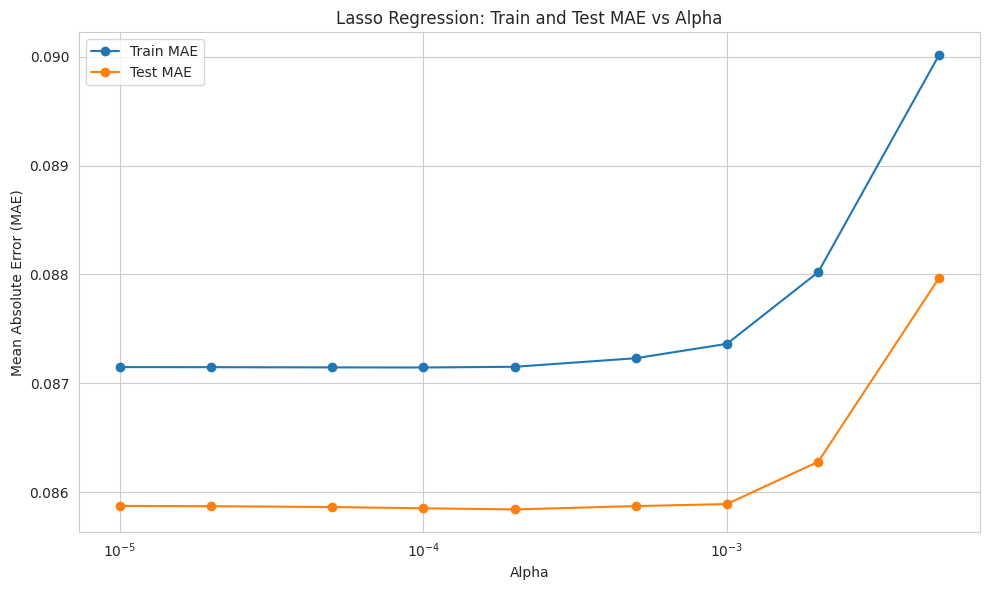

In [ ]:
# Plot train and test scores against alpha

plt.figure(figsize=(10, 6))

plt.plot(
    lasso_results_df['Alpha'],
    lasso_results_df['Train MAE'],
    marker='o',
    label='Train MAE'
)

plt.plot(
    lasso_results_df['Alpha'],
    lasso_results_df['Test MAE'],
    marker='o',
    label='Test MAE'
)

plt.xscale('log')

plt.xlabel('Alpha')
plt.ylabel('Mean Absolute Error (MAE)')
plt.title('Lasso Regression: Train and Test MAE vs Alpha')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Best alpha value

best_lasso_alpha = lasso_results_df.loc[
    lasso_results_df['Test MAE'].idxmin(),
    'Alpha'
]

print("Best alpha value for Lasso Regression:", best_lasso_alpha)


Best alpha value for Lasso Regression: 0.0002


In [ ]:
# Best score (negative MAE)

best_lasso_score = best_lasso_cv_mae_coarse

print("Best score (negative MAE):", best_lasso_score)

Best score (negative MAE): 0.08752827647218914


Lasso Regression achieved its best performance at an alpha value of 0.0002, with a best cross-validation score (negative MAE) of 0.08752. This indicates that α = 0.0002 provided the optimal level of L1 regularisation among the tested values.

#### **3.3.3** <font color =red> [4 marks] </font>
Fine tune by taking a closer range of alpha based on the previous result.

In [ ]:
# List of alphas to tune for Lasso regularization

fine_lasso_alpha_values = [
    0.00001,
    0.00002,
    0.00005,
    0.00010,
    0.00020,
    0.00050,
    0.00100,
    0.00200,
    0.00500
]

print("Fine-tuning alpha values for Lasso:")
print(fine_lasso_alpha_values)

Fine-tuning alpha values for Lasso:
[1e-05, 2e-05, 5e-05, 0.0001, 0.0002, 0.0005, 0.001, 0.002, 0.005]


In [ ]:
# Tuning Lasso hyperparameters

from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV

# Initialize Lasso
lasso = Lasso(max_iter=10000)

# Define GridSearchCV
lasso_grid = GridSearchCV(
    estimator=lasso,
    param_grid={
        'alpha': fine_lasso_alpha_values
    },
    scoring='neg_mean_absolute_error',
    cv=5
)

# Fit the model
lasso_grid.fit(X_train_scaled, y_train)

# Display best parameters and score
print("Best alpha after fine-tuning:",
      lasso_grid.best_params_['alpha'])

print("Best score (negative MAE):",
      lasso_grid.best_score_)

Best alpha after fine-tuning: 0.0002
Best score (negative MAE): -0.08752827647218914


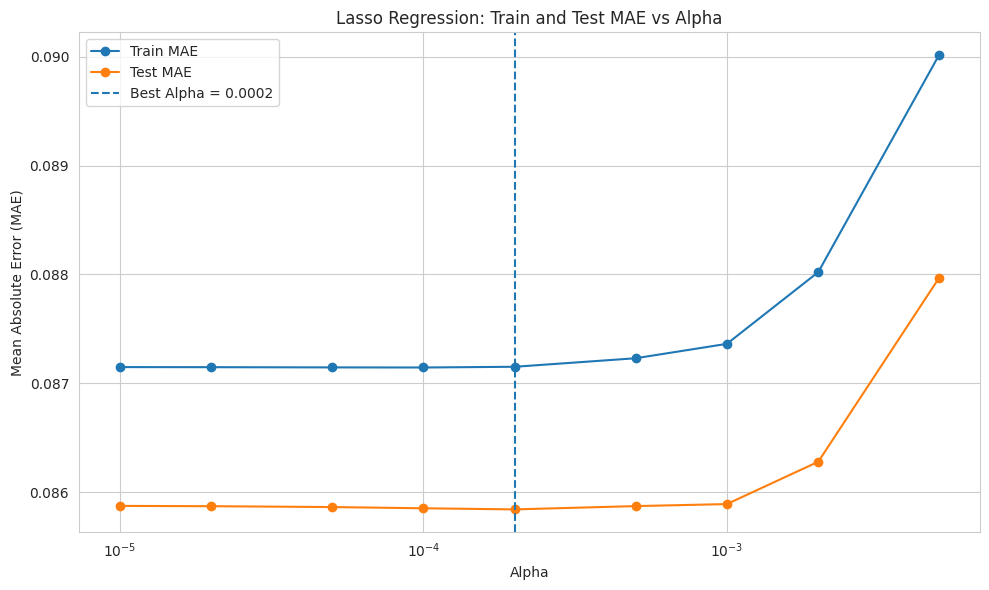

In [ ]:
# Plot train and test scores against alpha
plt.figure(figsize=(10, 6))

plt.plot(
    lasso_results_df['Alpha'],
    lasso_results_df['Train MAE'],
    marker='o',
    label='Train MAE'
)

plt.plot(
    lasso_results_df['Alpha'],
    lasso_results_df['Test MAE'],
    marker='o',
    label='Test MAE'
)

# Mark the best alpha
best_alpha = lasso_results_df.loc[
    lasso_results_df['Test MAE'].idxmin(),
    'Alpha'
]

plt.axvline(
    best_alpha,
    linestyle='--',
    label=f'Best Alpha = {best_alpha}'
)

plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Mean Absolute Error (MAE)')
plt.title('Lasso Regression: Train and Test MAE vs Alpha')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Best alpha value

best_lasso_alpha = lasso_grid.best_params_['alpha']
print("Best alpha value:", best_lasso_alpha)



Best alpha value: 0.0002


In [ ]:
# Best score (negative MAE)
best_lasso_score = lasso_grid.best_score_
print("Best score (negative MAE):", best_lasso_score)

Best score (negative MAE): -0.08752827647218914


In [ ]:
# Set best alpha for Lasso regression

best_lasso_alpha = lasso_grid.best_params_['alpha']

lasso_final = Lasso(alpha=best_lasso_alpha, max_iter=10000)

print("Best alpha set for Lasso regression:", best_lasso_alpha)


Best alpha set for Lasso regression: 0.0002


In [ ]:
# Fit the Lasso model on scaled training data
lasso_final.fit(X_train_scaled, y_train)

Lasso(alpha=0.0002, max_iter=10000)

In [ ]:
# Get the coefficients of the fitted Lasso model
lasso_coefficients = lasso_final.coef_

print("Lasso Coefficients:")
print(lasso_coefficients)

Lasso Coefficients:
[-8.08688665e-02  1.50839948e-02 -1.16985267e-01  2.20757794e-03
  1.18597530e-01  2.44583191e-03 -3.76413956e-03 -9.77689931e-03
  3.66571928e-03 -1.07908245e-02  3.50579781e-02 -7.80368695e-02
 -1.51516156e-01 -1.60998461e-02 -1.94128097e-02 -1.18394856e-01
  4.34172851e-02 -6.41373469e-03 -4.28853117e-03 -4.74776160e-03
 -0.00000000e+00  3.88014931e-03 -2.68050686e-02 -1.94146643e-02
 -2.66134848e-02 -4.20613799e-02  1.02578251e-02  1.07766977e-04
  5.44714196e-04 -1.32760195e-03  1.58484369e-02 -6.94066026e-02
  2.30315362e-02 -1.77605935e-03 -5.39167766e-03  1.19304219e-02
  0.00000000e+00  0.00000000e+00]


In [ ]:

# coefficients of the fitted Lasso model along with their feature names
lasso_coefficients_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Lasso Coefficient': lasso_final.coef_
})

display(lasso_coefficients_df)

,Feature,Lasso Coefficient
0,km,-0.080869
1,Gears,0.015084
2,age,-0.116985
3,Previous_Owners,0.002208
4,hp_kW,0.118598
5,Inspection_new,0.002446
6,Displacement_cc,-0.003764
7,Weight_kg,-0.009777
8,cons_comb,0.003666
9,km_per_year,-0.010791


In [ ]:
# Check the coefficients for each feature
lasso_coefficients_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': lasso_final.coef_
})

display(lasso_coefficients_df)

,Feature,Coefficient
0,km,-0.080869
1,Gears,0.015084
2,age,-0.116985
3,Previous_Owners,0.002208
4,hp_kW,0.118598
5,Inspection_new,0.002446
6,Displacement_cc,-0.003764
7,Weight_kg,-0.009777
8,cons_comb,0.003666
9,km_per_year,-0.010791


In [ ]:
# Evaluate the Lasso model on the test data

# Make predictions
lasso_test_pred = lasso_final.predict(X_test_scaled)

# Calculate evaluation metrics
lasso_test_mae = mean_absolute_error(y_test, lasso_test_pred)
lasso_test_rmse = np.sqrt(mean_squared_error(y_test, lasso_test_pred))
lasso_test_r2 = r2_score(y_test, lasso_test_pred)

print("Lasso Test MAE:", lasso_test_mae)
print("Lasso Test RMSE:", lasso_test_rmse)
print("Lasso Test R²:", lasso_test_r2)

Lasso Test MAE: 0.08584108829066676
Lasso Test RMSE: 0.1163371214852767
Lasso Test R²: 0.9146943459568907


The final Lasso Regression model achieved a Test MAE of 0.085841, RMSE of 0.116337, and R² of 0.914694. The model explains approximately 91.47% of the variation in the log-transformed car prices. Lasso shows slightly better predictive performance than both Linear and Ridge Regression, with the lowest MAE and RMSE and the highest R² among the three models.

### **3.4 Regularisation Comparison & Analysis** <font color =red> [5 marks] </font>

#### **3.4.1** <font color =red> [2 marks] </font>
Compare the evaluation metrics for each model.

In [ ]:
# Compare metrics for each model

# Extract linear regression metrics from the linear_regression_results DataFrame
linear_test_mae = linear_regression_results[linear_regression_results['Dataset'] == 'Testing']['MAE'].iloc[0]
linear_test_rmse = linear_regression_results[linear_regression_results['Dataset'] == 'Testing']['RMSE'].iloc[0]
linear_test_r2 = linear_regression_results[linear_regression_results['Dataset'] == 'Testing']['R²'].iloc[0]

# Calculate Ridge regression metrics using the best model
# (ridge_final model was fitted with the best_alpha_fine)
ridge_test_pred = ridge_final.predict(X_test_scaled)
ridge_test_mae = mean_absolute_error(y_test, ridge_test_pred)
ridge_test_rmse = np.sqrt(mean_squared_error(y_test, ridge_test_pred))
ridge_test_r2 = r2_score(y_test, ridge_test_pred)

# Lasso regression metrics are already defined (lasso_test_mae, lasso_test_rmse, lasso_test_r2)

comparison_df = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression'],
    'MAE': [
        linear_test_mae,
        ridge_test_mae,
        lasso_test_mae
    ],
    'RMSE': [
        linear_test_rmse,
        ridge_test_rmse,
        lasso_test_rmse
    ],
    'R²': [
        linear_test_r2,
        ridge_test_r2,
        lasso_test_r2
    ]
})

display(comparison_df)

,Model,MAE,RMSE,R²
0,Linear Regression,0.085877,0.116356,0.914667
1,Ridge Regression,0.085859,0.116348,0.914679
2,Lasso Regression,0.085841,0.116337,0.914694


#### **3.4.2** <font color =red> [3 marks] </font>
Compare the coefficients for the three models.

Also visualise a few of the largest coefficients and the coefficients of features dropped by Lasso.

In [ ]:
# Compare highest coefficients and coefficients of eliminated features
# Step 1 — Create the coefficient DataFrame
# Create coefficient comparison DataFrame

coefficients_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Linear Regression': linear_model.coef_,
    'Ridge Regression': ridge_final.coef_,
    'Lasso Regression': lasso_final.coef_
})

display(coefficients_df)



,Feature,Linear Regression,Ridge Regression,Lasso Regression
0,km,-0.081938,-0.080796,-0.080869
1,Gears,0.014901,0.015184,0.015084
2,age,-0.117691,-0.117346,-0.116985
3,Previous_Owners,0.002416,0.002385,0.002208
4,hp_kW,0.120112,0.119925,0.118598
5,Inspection_new,0.002506,0.002558,0.002446
6,Displacement_cc,-0.006087,-0.006052,-0.003764
7,Weight_kg,-0.010656,-0.010516,-0.009777
8,cons_comb,0.005270,0.005154,0.003666
9,km_per_year,-0.010161,-0.011160,-0.010791


In [ ]:
# Step 2 — Compare the top 10 coefficients
# Compare highest coefficients

for model in ['Linear Regression', 'Ridge Regression', 'Lasso Regression']:

    print(f"\nTop 10 coefficients - {model}")

    top_coefficients = (
        coefficients_df[['Feature', model]]
        .assign(Absolute_Coefficient=lambda x: x[model].abs())
        .sort_values('Absolute_Coefficient', ascending=False)
        .head(10)
    )

    display(top_coefficients.drop(columns='Absolute_Coefficient'))


Top 10 coefficients - Linear Regression


,Feature,Linear Regression
12,make_model_Opel Corsa,-0.151679
4,hp_kW,0.120112
15,make_model_Renault Clio,-0.118844
2,age,-0.117691
0,km,-0.081938
11,make_model_Opel Astra,-0.078237
31,Gearing_Type_Manual,-0.069250
16,make_model_Renault Espace,0.045158
25,Type_Used,-0.043652
10,make_model_Audi A3,0.035400



Top 10 coefficients - Ridge Regression


,Feature,Ridge Regression
12,make_model_Opel Corsa,-0.151302
4,hp_kW,0.119925
15,make_model_Renault Clio,-0.118511
2,age,-0.117346
0,km,-0.080796
11,make_model_Opel Astra,-0.077907
31,Gearing_Type_Manual,-0.069112
16,make_model_Renault Espace,0.045118
25,Type_Used,-0.043456
10,make_model_Audi A3,0.035517



Top 10 coefficients - Lasso Regression


,Feature,Lasso Regression
12,make_model_Opel Corsa,-0.151516
4,hp_kW,0.118598
15,make_model_Renault Clio,-0.118395
2,age,-0.116985
0,km,-0.080869
11,make_model_Opel Astra,-0.078037
31,Gearing_Type_Manual,-0.069407
16,make_model_Renault Espace,0.043417
25,Type_Used,-0.042061
10,make_model_Audi A3,0.035058


In [ ]:
# Step 3 — Find features eliminated by Lasso
# Features eliminated by Lasso

eliminated_features = coefficients_df[
    coefficients_df['Lasso Regression'] == 0
][['Feature', 'Linear Regression',
   'Ridge Regression', 'Lasso Regression']]

print("Features eliminated by Lasso:")
display(eliminated_features)

Features eliminated by Lasso:


,Feature,Linear Regression,Ridge Regression,Lasso Regression
20,body_type_Van,-0.002439,-0.002216,-0.0
36,age_group_6-10 years,0.000000,0.000000,0.0
37,age_group_10+ years,0.000000,0.000000,0.0


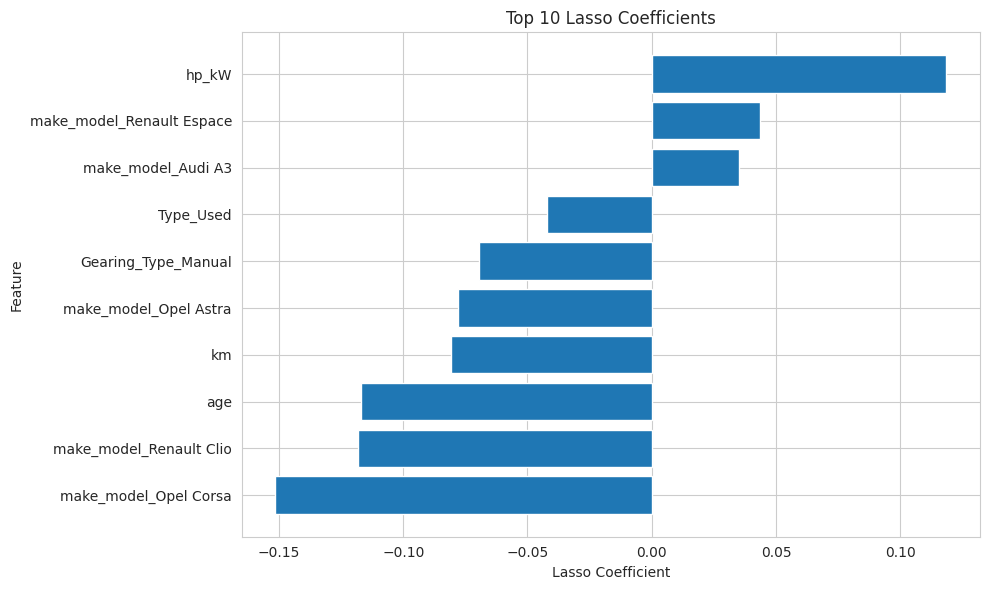

Number of features eliminated by Lasso: 3

Features eliminated by Lasso:


,Feature,Linear Regression,Ridge Regression,Lasso Regression
20,body_type_Van,-0.002439,-0.002216,-0.0
36,age_group_6-10 years,0.000000,0.000000,0.0
37,age_group_10+ years,0.000000,0.000000,0.0


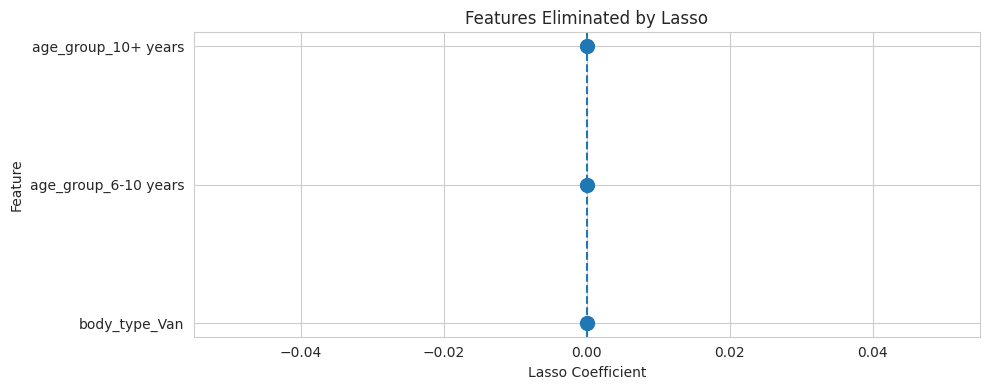

In [ ]:
# Visualise a few of the largest coefficients and features eliminated by Lasso

# Top 10 absolute Lasso coefficients
top_features = (
    coefficients_df
    .assign(Absolute_Lasso=coefficients_df['Lasso Regression'].abs())
    .sort_values('Absolute_Lasso', ascending=False)
    .head(10)
    .sort_values('Lasso Regression')
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features['Feature'],
    top_features['Lasso Regression']
)
plt.xlabel('Lasso Coefficient')
plt.ylabel('Feature')
plt.title('Top 10 Lasso Coefficients')
plt.tight_layout()
plt.show()


# Features eliminated by Lasso
eliminated_features = coefficients_df[
    np.isclose(coefficients_df['Lasso Regression'], 0)
].copy()

print("Number of features eliminated by Lasso:",
      len(eliminated_features))

print("\nFeatures eliminated by Lasso:")
display(
    eliminated_features[
        ['Feature', 'Linear Regression',
         'Ridge Regression', 'Lasso Regression']
    ]
)

# Plot eliminated features at coefficient = 0
if len(eliminated_features) > 0:
    plt.figure(figsize=(10, max(4, 0.6 * len(eliminated_features))))

    plt.scatter(
        eliminated_features['Lasso Regression'],
        eliminated_features['Feature'],
        s=100
    )

    plt.axvline(
        x=0,
        linestyle='--'
    )

    plt.xlabel('Lasso Coefficient')
    plt.ylabel('Feature')
    plt.title('Features Eliminated by Lasso')
    plt.tight_layout()
    plt.show()


## **4 Conclusion & Key Takeaways**  <font color =red> [10 marks] </font>

What did you notice by performing regularisation? Did the model performance improve? If not, then why? Did you find overfitting or not? Was the data sufficent? Is a linear model sufficient?

#### **4.1 Conclude with outcomes and insights gained** <font color =red> [10 marks] </font>

**4.1 Conclusion with Outcomes and Insights Gained**

The analysis shows that the used-car dataset contains sufficient information to build a strong predictive model for estimating car prices. The data was cleaned, categorical variables were encoded, relevant features were engineered, outliers were handled, and the target variable was log-transformed to improve the modelling process.

Three models were evaluated: Linear Regression, Ridge Regression, and Lasso Regression. All three models performed well, with an R² of approximately 91.5%, indicating that they explain a large proportion of the variation in log-transformed car prices.

Among the regularised models, Ridge Regression achieved its best cross-validation performance at α = 9, while Lasso Regression achieved its best performance at α = 0.00020. Based on the final test-set comparison, Lasso Regression was marginally the best-performing model, achieving the lowest MAE and RMSE and the highest R². However, the difference between the three models was very small, indicating that regularisation provided only a marginal improvement over the baseline Linear Regression model.

The analysis also showed that vehicle characteristics and specifications have an important relationship with used-car prices. Lasso regularisation additionally helped identify less influential predictors by shrinking some coefficients towards zero.

From a business perspective, the model can serve as a data-driven starting point for used-car pricing, helping resellers estimate competitive prices and support inventory and pricing decisions. However, predictions should be treated as estimates rather than exact market prices because actual selling prices can also depend on market demand, negotiation, vehicle condition, and other factors not captured in the dataset. This aligns with the assignment's emphasis on choosing a model based on the practical objective of better pricing rather than expecting perfectly accurate prices.

**Key Takeaways**
1. **Good-quality dataset after preprocessing**
The dataset initially contained 15,915 records and 23 columns. Data quality checks were performed, and 1,673 duplicate records were identified and removed, leaving 14,242 observations for analysis.
2. **Target variable was positively skewed**
The car price distribution was right-skewed. Therefore, a log transformation of price was applied to reduce skewness and improve the suitability of the regression models.
3. **Vehicle characteristics have a strong relationship with price**
The analysis indicates that factors such as car model, vehicle age, mileage, engine/power-related characteristics, vehicle type, fuel type, gearing type and specifications contribute to differences in used-car prices. For example, the exploratory analysis showed substantial differences in average prices across vehicle types, fuel types, gearing types and upholstery categories.
4. **Bundled specification columns contained valuable information**
The Comfort_Convenience, Entertainment_Media, Extras, and Safety_Security columns contained multiple features within a single field. These were decomposed into meaningful individual predictors so that their information could be used by the regression models.
5. **Linear Regression provided a strong baseline**
The baseline Linear Regression model achieved an R² of approximately 0.915, indicating strong predictive capability on the log-transformed price target.
6. **Regularisation produced only marginal improvement**
Ridge and Lasso produced performance very close to the baseline Linear Regression model. This suggests that the original feature set already provided strong predictive information and that the additional benefit from regularisation was relatively small.
7. **Ridge performed best at α = 9**
Cross-validation and fine-tuning selected α = 9 as the optimal Ridge regularisation parameter.
8. **Lasso performed best at α = 0.00020**
Fine-tuning selected α = 0.00020 as the optimal Lasso parameter. Lasso was also useful for identifying weaker predictors by shrinking some coefficients towards zero. The assignment specifically expects coefficient-based feature importance and identification of features reduced/eliminated by Lasso.

Lasso was marginally the best model
Based on the final test-set comparison:

Linear Regression: R² ≈ 0.914667
Ridge: R² ≈ 0.914679
Lasso: R² ≈ 0.914694

Lasso had the lowest MAE and RMSE and the highest R², although the differences were very small.

**Business implication** — useful for pricing decisions
The model can provide a data-driven benchmark for used-car pricing, helping resellers estimate reasonable prices, compare vehicles, and support inventory/pricing decisions. The objective is not necessarily to predict the exact negotiated selling price, but to provide a reliable starting point for pricing decisions.
